In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/RadarHAR")

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "results",
    "src"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("RadarHAR project created successfully!")

RadarHAR project created successfully!


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

print("All libraries imported successfully!")
import sys
import shutil

print("Python version:", sys.version)

total, used, free = shutil.disk_usage("/content")

print("Available storage:", round(free / 1024**3, 2), "GB")

All libraries imported successfully!
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Available storage: 107.61 GB


In [7]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/RadarHAR")
DATA_DIR = PROJECT_DIR / "data" / "raw"

for file in DATA_DIR.iterdir():
    print(file.name)

Readme_848.pdf
Sample_data_preprocessing+label_extraction.zip
Dataset_848.7z


In [8]:
%pip install -q py7zr

In [9]:
import py7zr
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/RadarHAR")
DATA_DIR = PROJECT_DIR / "data" / "raw"

archive_path = DATA_DIR / "Dataset_848.7z"

EXTRACT_DIR = Path("/content/RadarHAR_dataset")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with py7zr.SevenZipFile(archive_path, mode="r") as archive:
    archive.extractall(path=EXTRACT_DIR)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [10]:
import zipfile

zip_path = DATA_DIR / "Sample_data_preprocessing+label_extraction.zip"

REFERENCE_DIR = PROJECT_DIR / "reference"

REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(REFERENCE_DIR)

print("Reference code extracted successfully!")

for file in REFERENCE_DIR.rglob("*"):
    if file.is_file():
        print(file.name)

Reference code extracted successfully!
DataProcessingExample.m
Label_extract4.m
oddnumber.m


In [11]:
from collections import Counter

files = [
    file for file in EXTRACT_DIR.rglob("*")
    if file.is_file()
]

print("Total files:", len(files))

extensions = Counter(
    file.suffix.lower() for file in files
)

print("\nFile types:")

for extension, count in extensions.items():
    print(extension, ":", count)

print("\nFirst 15 files:")

for file in files[:15]:
    print(file.relative_to(EXTRACT_DIR))

Total files: 1755

File types:
.pdf : 1
.dat : 1754

First 15 files:
Document for all datasets - 03092019.pdf
7 March 2019 West Cumbria Dataset/5P48A05R3.dat
7 March 2019 West Cumbria Dataset/5P46A05R3.dat
7 March 2019 West Cumbria Dataset/3P41A03R3.dat
7 March 2019 West Cumbria Dataset/1P55A01R2.dat
7 March 2019 West Cumbria Dataset/3P43A03R3.dat
7 March 2019 West Cumbria Dataset/4P47A04R3.dat
7 March 2019 West Cumbria Dataset/1P38A01R2.dat
7 March 2019 West Cumbria Dataset/5P47A05R2.dat
7 March 2019 West Cumbria Dataset/4P44A04R2.dat
7 March 2019 West Cumbria Dataset/1P55A01R3.dat
7 March 2019 West Cumbria Dataset/1P54A01R2.dat
7 March 2019 West Cumbria Dataset/2P46A02R2.dat
7 March 2019 West Cumbria Dataset/2P37A02R1.dat
7 March 2019 West Cumbria Dataset/1P56A01R3.dat


In [12]:
total_size = sum(
    file.stat().st_size for file in files
)

print(
    "Extracted dataset size:",
    round(total_size / 1024**3, 2),
    "GB"
)

Extracted dataset size: 14.9 GB


In [13]:
for file in sorted(REFERENCE_DIR.rglob("*.m")):
    print("=" * 60)
    print("FILE:", file.name)
    print("=" * 60)

    print(file.read_text(errors="replace"))

FILE: DataProcessingExample.m
%% Creates a quick look of Range-Time and Spectrograms from a data file
%==========================================================================
% Author UoG Radar Group
% Version 1.0

% The user has to select manually the range bins over which the
% spectrograms are calculated. There may be different ways to calculate the
% spectrogram (e.g. coherent sum of range bins prior to STFT). 
% Note that the scripts have to be in the same folder where the data file
% is located, otherwise uigetfile() and textscan() give an error. The user
% may replace those functions with manual read to the file path of a
% specific data file
%==========================================================================
%% Data reading part
[filename,pathname] = uigetfile('*.dat');
fileID = fopen(filename, 'r');
dataArray = textscan(fileID, '%f');
fclose(fileID);
radarData = dataArray{1};
clearvars fileID dataArray ans;
fc = radarData(1); % Center frequency
Tsweep = radarData(2)

In [14]:
radar_files = sorted(EXTRACT_DIR.rglob("*.dat"))

print("Total radar recordings:", len(radar_files))

sample_file = radar_files[0]

print("Selected file:", sample_file.name)
print("File size:", sample_file.stat().st_size, "bytes")

print("\nFirst 500 bytes of raw data:")

with open(sample_file, "rb") as f:
    print(f.read(500))

Total radar recordings: 1754
Selected file: 1P36A01R01.dat
File size: 15360052 bytes

First 500 bytes of raw data:
b'5800000000.000000\r\n1.000000\r\n128\r\n400000000.000000\r\n1812+1897i\r\n1782+2029i\r\n2265+2014i\r\n2286+1763i\r\n2401+2152i\r\n2342+2324i\r\n2225+2441i\r\n2047+2460i\r\n1888+2372i\r\n1773+2218i\r\n1709+1996i\r\n1727+1825i\r\n1858+1595i\r\n1979+1546i\r\n2240+1628i\r\n2438+1834i\r\n2516+2220i\r\n2388+2541i\r\n2096+2699i\r\n1701+2528i\r\n1451+2098i\r\n1490+1666i\r\n1785+1352i\r\n2261+1413i\r\n2600+1788i\r\n2629+2289i\r\n2296+2671i\r\n1996+2695i\r\n1612+2257i\r\n1620+1784i\r\n1862+1507i\r\n2163+1581i\r\n2401+1911i\r\n2376+2259i\r\n2184+2445i\r\n1942+2387i\r\n1788+2177i\r\n1769'


In [15]:
from collections import Counter

folder_counts = Counter(
    file.parent.relative_to(EXTRACT_DIR)
    for file in radar_files
)

print("Dataset folders:\n")

for folder, count in folder_counts.items():
    print(folder, ":", count, "recordings")

Dataset folders:

1 December 2017 Dataset : 360 recordings
2 March 2017 Dataset : 48 recordings
3 June 2017 Dataset : 162 recordings
4 July 2018 Dataset : 288 recordings
5 February 2019 UoG Dataset : 306 recordings
6 February 2019 NG Homes Dataset : 301 recordings
7 March 2019 West Cumbria Dataset : 289 recordings


In [16]:
total_size = sum(
    file.stat().st_size for file in radar_files
)

print(
    "Total radar data size:",
    round(total_size / 1024**3, 2),
    "GB"
)

Total radar data size: 14.9 GB


DAY-2

In [17]:
import re
import pandas as pd

activity_map = {
    1: "Walking",
    2: "Sitting down",
    3: "Standing up",
    4: "Drinking water",
    5: "Picking up an object",
    6: "Falling"
}

records = []
unmatched_files = []

for file in radar_files:

    match = re.search(
        r"P(\d+)A(\d+)R(\d+)",
        file.stem
    )

    if match:

        person = int(match.group(1))
        activity = int(match.group(2))
        repetition = int(match.group(3))

        records.append({
            "filename": file.name,
            "filepath": str(file),
            "person_id": person,
            "activity_id": activity,
            "activity": activity_map.get(
                activity, "Unknown"
            ),
            "repetition": repetition,
            "collection": file.parent.name
        })

    else:
        unmatched_files.append(file.name)

df = pd.DataFrame(records)

print("Total labelled recordings:", len(df))
print("Unmatched files:", len(unmatched_files))

display(df.head(10))

Total labelled recordings: 1754
Unmatched files: 0


,filename,filepath,person_id,activity_id,activity,repetition,collection
0,1P36A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,36,1,Walking,1,1 December 2017 Dataset
1,1P36A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,36,1,Walking,2,1 December 2017 Dataset
2,1P36A01R03.dat,/content/RadarHAR_dataset/1 December 2017 Data...,36,1,Walking,3,1 December 2017 Dataset
3,1P37A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,37,1,Walking,1,1 December 2017 Dataset
4,1P37A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,37,1,Walking,2,1 December 2017 Dataset
5,1P37A01R03.dat,/content/RadarHAR_dataset/1 December 2017 Data...,37,1,Walking,3,1 December 2017 Dataset
6,1P38A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,38,1,Walking,1,1 December 2017 Dataset
7,1P38A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,38,1,Walking,2,1 December 2017 Dataset
8,1P38A01R03.dat,/content/RadarHAR_dataset/1 December 2017 Data...,38,1,Walking,3,1 December 2017 Dataset
9,1P39A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,39,1,Walking,1,1 December 2017 Dataset


In [18]:
print("Unique participants:",
      df["person_id"].nunique())

print("\nActivity distribution:")
print(df["activity"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nUnmatched filenames:")
print(unmatched_files[:10])

Unique participants: 72

Activity distribution:
activity
Walking                 312
Sitting down            312
Standing up             311
Drinking water          311
Picking up an object    311
Falling                 197
Name: count, dtype: int64

Missing values:
filename       0
filepath       0
person_id      0
activity_id    0
activity       0
repetition     0
collection     0
dtype: int64

Unmatched filenames:
[]


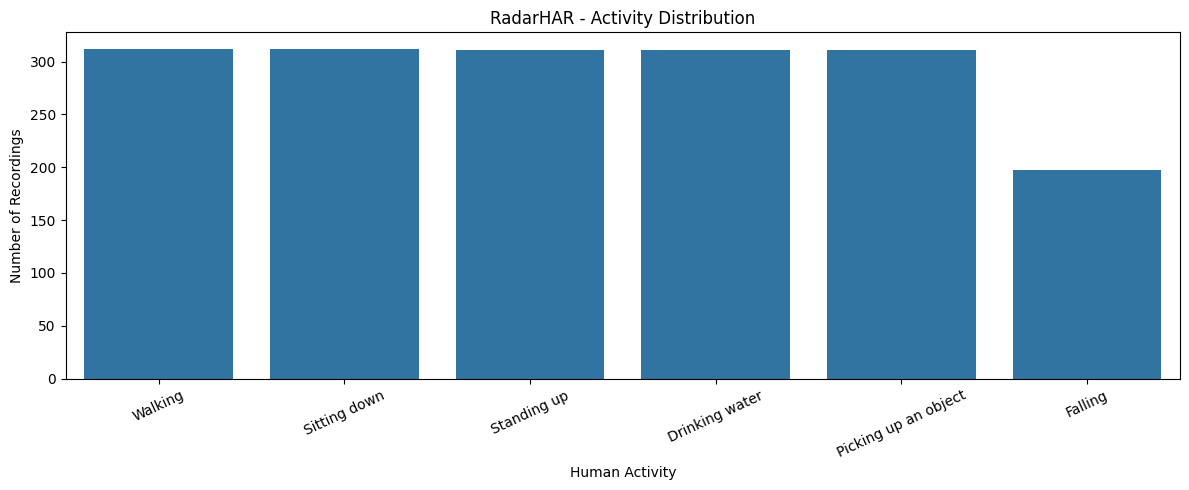

In [19]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="activity",
    order=list(activity_map.values())
)

plt.title("RadarHAR - Activity Distribution")
plt.xlabel("Human Activity")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" / "activity_distribution.png",
    dpi=300
)

plt.show()

In [20]:
df.to_csv(
    PROJECT_DIR / "data" / "processed" / "metadata.csv",
    index=False
)

print("Metadata saved successfully!")

Metadata saved successfully!


In [22]:
import numpy as np

def load_radar_data(filepath):

    with open(filepath, "r") as f:

        fc = float(f.readline())

        sweep_time = float(f.readline()) / 1000

        samples_per_sweep = int(float(f.readline()))

        bandwidth = float(f.readline())

        signal = np.fromiter(
            (
                complex(line.strip().replace("i", "j"))
                for line in f
                if line.strip()
            ),
            dtype=np.complex64
        )

    parameters = {
        "center_frequency": fc,
        "sweep_time": sweep_time,
        "samples_per_sweep": samples_per_sweep,
        "bandwidth": bandwidth,
        "sampling_frequency": samples_per_sweep / sweep_time,
        "prf": 1 / sweep_time
    }

    return signal, parameters

In [23]:
signal, params = load_radar_data(radar_files[0])

print("Radar parameters:")

for key, value in params.items():
    print(key, ":", value)

print("\nSignal shape:", signal.shape)
print("Signal datatype:", signal.dtype)

print("\nFirst 10 samples:")
print(signal[:10])

duration = (
    len(signal) / params["sampling_frequency"]
)

print("\nRecording duration:", duration, "seconds")

Radar parameters:
center_frequency : 5800000000.0
sweep_time : 0.001
samples_per_sweep : 128
bandwidth : 400000000.0
sampling_frequency : 128000.0
prf : 1000.0

Signal shape: (1280000,)
Signal datatype: complex64

First 10 samples:
[1812.+1897.j 1782.+2029.j 2265.+2014.j 2286.+1763.j 2401.+2152.j
 2342.+2324.j 2225.+2441.j 2047.+2460.j 1888.+2372.j 1773.+2218.j]

Recording duration: 10.0 seconds


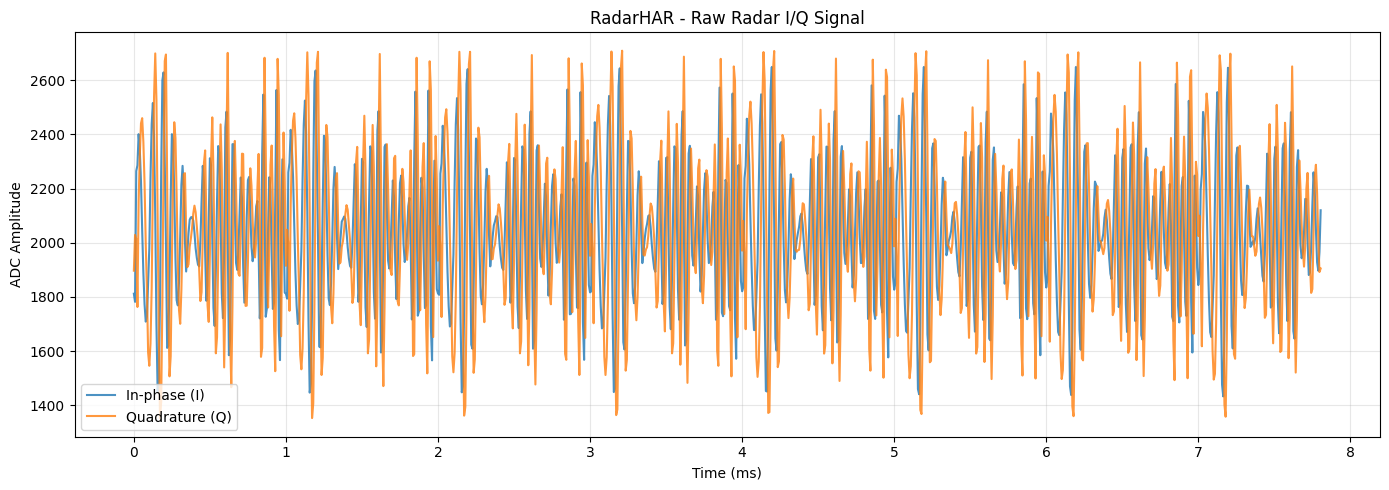

In [24]:
n = 1000

time = np.arange(n) / params["sampling_frequency"]

plt.figure(figsize=(14, 5))

plt.plot(
    time * 1000,
    signal[:n].real,
    label="In-phase (I)",
    alpha=0.8
)

plt.plot(
    time * 1000,
    signal[:n].imag,
    label="Quadrature (Q)",
    alpha=0.8
)

plt.title("RadarHAR - Raw Radar I/Q Signal")
plt.xlabel("Time (ms)")
plt.ylabel("ADC Amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" / "raw_radar_signal.png",
    dpi=300
)

plt.show()

DAY-3

In [25]:
NTS = params["samples_per_sweep"]

assert len(signal) % NTS == 0

num_chirps = len(signal) // NTS

data_time = signal.reshape(
    num_chirps, NTS
).T

print("Original shape:", signal.shape)
print("Reshaped data:", data_time.shape)
print("Number of chirps:", num_chirps)

Original shape: (1280000,)
Reshaped data: (128, 10000)
Number of chirps: 10000


In [26]:
from scipy.fft import fft, fftshift

range_fft = fft(data_time, axis=0)

range_fft = fftshift(range_fft, axes=0)

data_range = range_fft[NTS // 2:, :]

print("Range FFT shape:", data_range.shape)

Range FFT shape: (64, 10000)


In [27]:
c = 3e8

bandwidth = params["bandwidth"]

range_resolution = c / (2 * bandwidth)

range_axis = (
    np.arange(data_range.shape[0])
    * range_resolution
)

print("Range resolution:",
      range_resolution, "meters")

print("Last positive range bin:",
      range_axis[-1], "meters")

Range resolution: 0.375 meters
Last positive range bin: 23.625 meters


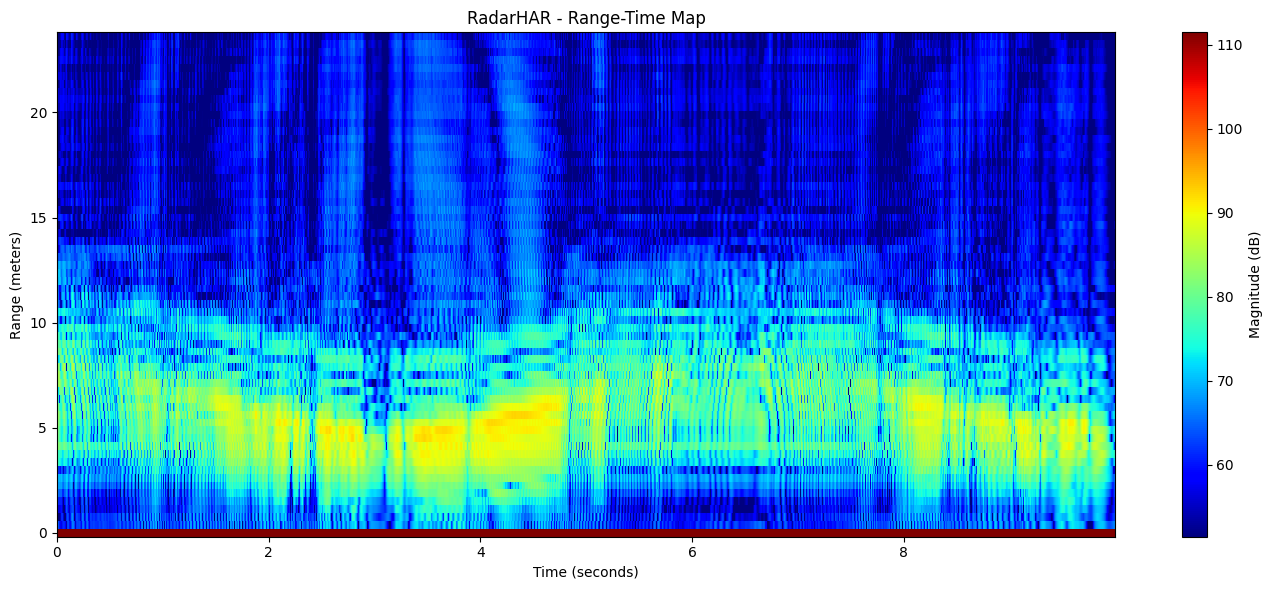

In [28]:
range_db = 20 * np.log10(
    np.abs(data_range) + 1e-10
)

time_axis = (
    np.arange(num_chirps)
    * params["sweep_time"]
)

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    time_axis,
    range_axis,
    range_db,
    shading="auto",
    cmap="jet",
    vmin=range_db.max() - 60,
    vmax=range_db.max()
)

plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (seconds)")
plt.ylabel("Range (meters)")
plt.title("RadarHAR - Range-Time Map")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" / "range_time.png",
    dpi=300
)

plt.show()

In [29]:
from scipy.signal import butter, lfilter

b, a = butter(
    4,
    0.0075,
    btype="highpass"
)

data_range_mti = lfilter(
    b, a,
    data_range,
    axis=1
)

# Remove the zero-range bin
data_range_mti = data_range_mti[1:, :]

print("MTI data shape:",
      data_range_mti.shape)

MTI data shape: (63, 10000)


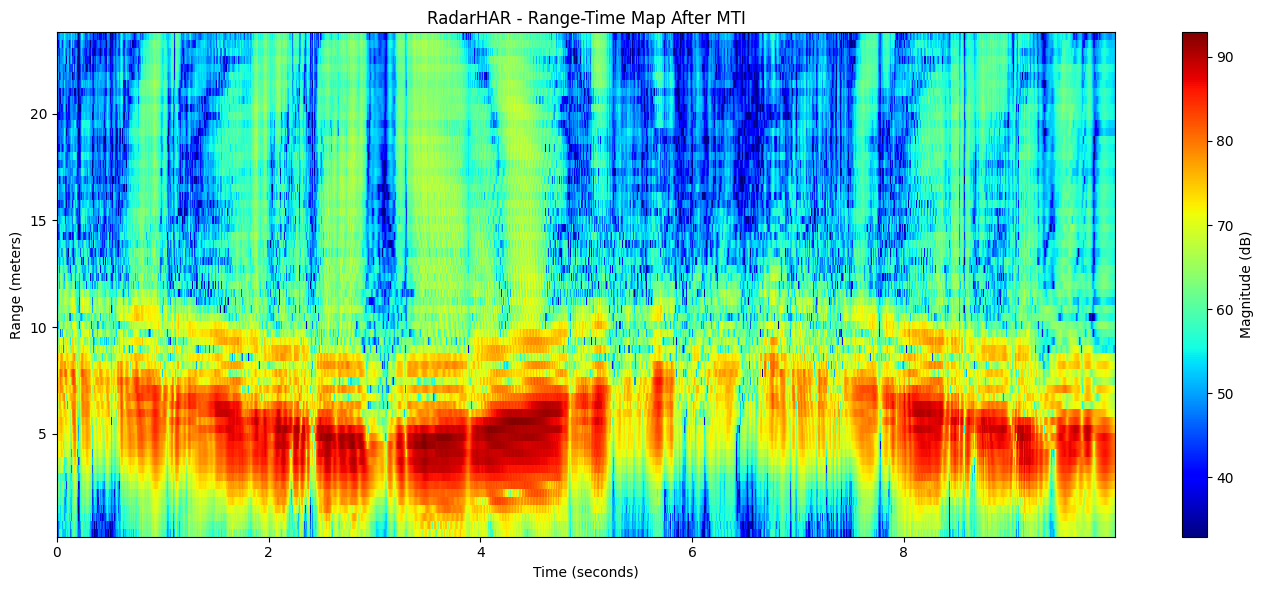

In [30]:
mti_db = 20 * np.log10(
    np.abs(data_range_mti) + 1e-10
)

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    time_axis,
    range_axis[1:],
    mti_db,
    shading="auto",
    cmap="jet",
    vmin=mti_db.max() - 60,
    vmax=mti_db.max()
)

plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (seconds)")
plt.ylabel("Range (meters)")
plt.title("RadarHAR - Range-Time Map After MTI")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" / "range_time_mti.png",
    dpi=300
)

plt.show()

In [31]:
from scipy.signal import stft

prf = params["prf"]

window_length = 200

overlap = 190

nfft = 800

spectrogram_sum = None

for rbin in range(9, 30):

    frequencies, times, Zxx = stft(
        data_range_mti[rbin, :],
        fs=prf,
        window="hamming",
        nperseg=window_length,
        noverlap=overlap,
        nfft=nfft,
        return_onesided=False,
        boundary=None,
        padded=False
    )

    magnitude = np.abs(
        fftshift(Zxx, axes=0)
    )

    if spectrogram_sum is None:
        spectrogram_sum = magnitude

    else:
        spectrogram_sum += magnitude

doppler_axis = fftshift(frequencies)

velocity_axis = (
    doppler_axis * c
    / (2 * params["center_frequency"])
)

# Match the reference velocity sign convention
spectrogram_sum = np.flipud(spectrogram_sum)

spectrogram_db = 20 * np.log10(
    spectrogram_sum + 1e-10
)

print("Spectrogram shape:",
      spectrogram_db.shape)

Spectrogram shape: (800, 981)


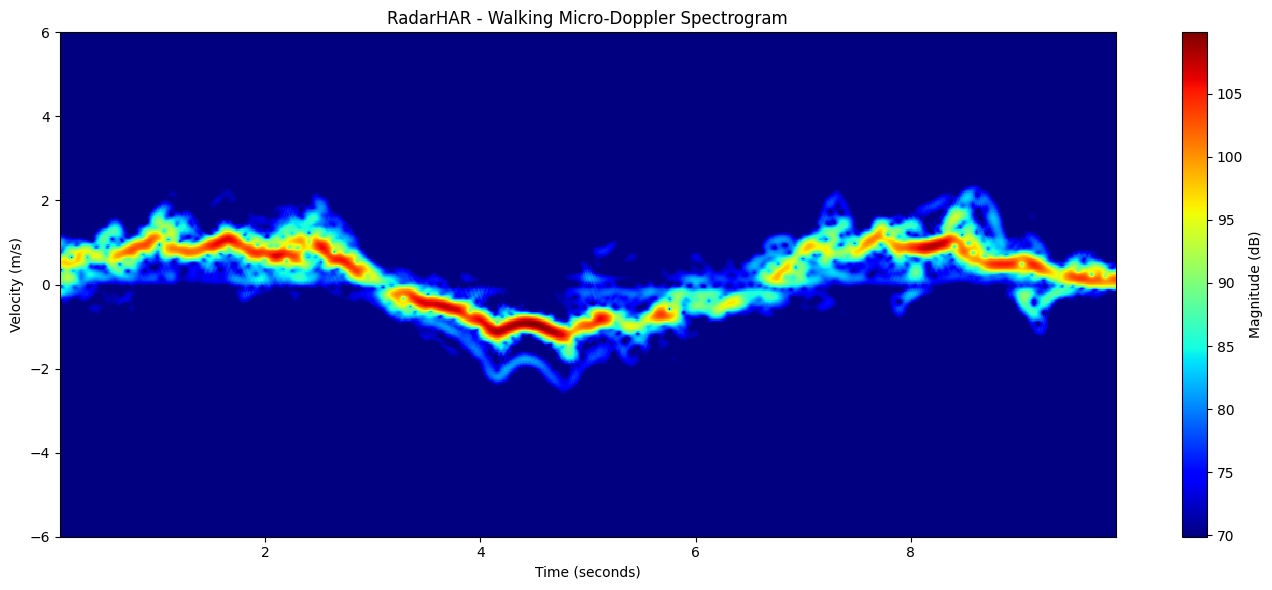

In [32]:
plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    velocity_axis,
    spectrogram_db,
    shading="auto",
    cmap="jet",
    vmin=spectrogram_db.max() - 40,
    vmax=spectrogram_db.max()
)

plt.ylim(-6, 6)

plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (seconds)")
plt.ylabel("Velocity (m/s)")

plt.title(
    "RadarHAR - Walking Micro-Doppler Spectrogram"
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" /
    "walking_spectrogram.png",
    dpi=300
)

plt.show()

DAY-4

In [33]:
from scipy.fft import fft, fftshift
from scipy.signal import butter, sosfilt, stft

def generate_spectrogram(filepath):

    # 1. Load raw radar data
    signal, params = load_radar_data(filepath)

    NTS = params["samples_per_sweep"]
    prf = params["prf"]

    # Validate recording
    if len(signal) % NTS != 0:
        raise ValueError("Incomplete radar chirp")

    # 2. Reshape into chirps
    num_chirps = len(signal) // NTS

    data_time = signal.reshape(
        num_chirps, NTS
    ).T

    # 3. Range FFT
    range_fft = fftshift(
        fft(data_time, axis=0),
        axes=0
    )

    data_range = range_fft[NTS // 2:, :]

    # 4. MTI filtering
    sos = butter(
        4,
        0.0075,
        btype="highpass",
        output="sos"
    )

    data_mti = sosfilt(
        sos,
        data_range,
        axis=1
    )

    data_mti = data_mti[1:, :]

    # 5. Micro-Doppler STFT
    spectrogram_sum = None

    for rbin in range(9, min(30, len(data_mti))):

        frequencies, times, Zxx = stft(
            data_mti[rbin, :],
            fs=prf,
            window="hamming",
            nperseg=200,
            noverlap=190,
            nfft=800,
            return_onesided=False,
            boundary=None,
            padded=False
        )

        magnitude = np.abs(
            fftshift(Zxx, axes=0)
        )

        if spectrogram_sum is None:
            spectrogram_sum = magnitude
        else:
            spectrogram_sum += magnitude

    # 6. Calculate velocity axis
    doppler_axis = fftshift(frequencies)

    velocity_axis = (
        doppler_axis * 3e8
        / (2 * params["center_frequency"])
    )

    # Match reference velocity convention
    spectrogram_sum = np.flipud(spectrogram_sum)

    # 7. Convert to decibels
    spectrogram_db = 20 * np.log10(
        spectrogram_sum + 1e-10
    )

    return spectrogram_db, times, velocity_axis

In [34]:
spec, times, velocity = generate_spectrogram(
    radar_files[0]
)

print("Spectrogram shape:", spec.shape)
print("Time axis shape:", times.shape)
print("Velocity axis shape:", velocity.shape)

print("Minimum value:", spec.min())
print("Maximum value:", spec.max())

print("All values finite:",
      np.isfinite(spec).all())

Spectrogram shape: (800, 981)
Time axis shape: (981,)
Velocity axis shape: (800,)
Minimum value: 24.469410256576033
Maximum value: 109.87566111146057
All values finite: True


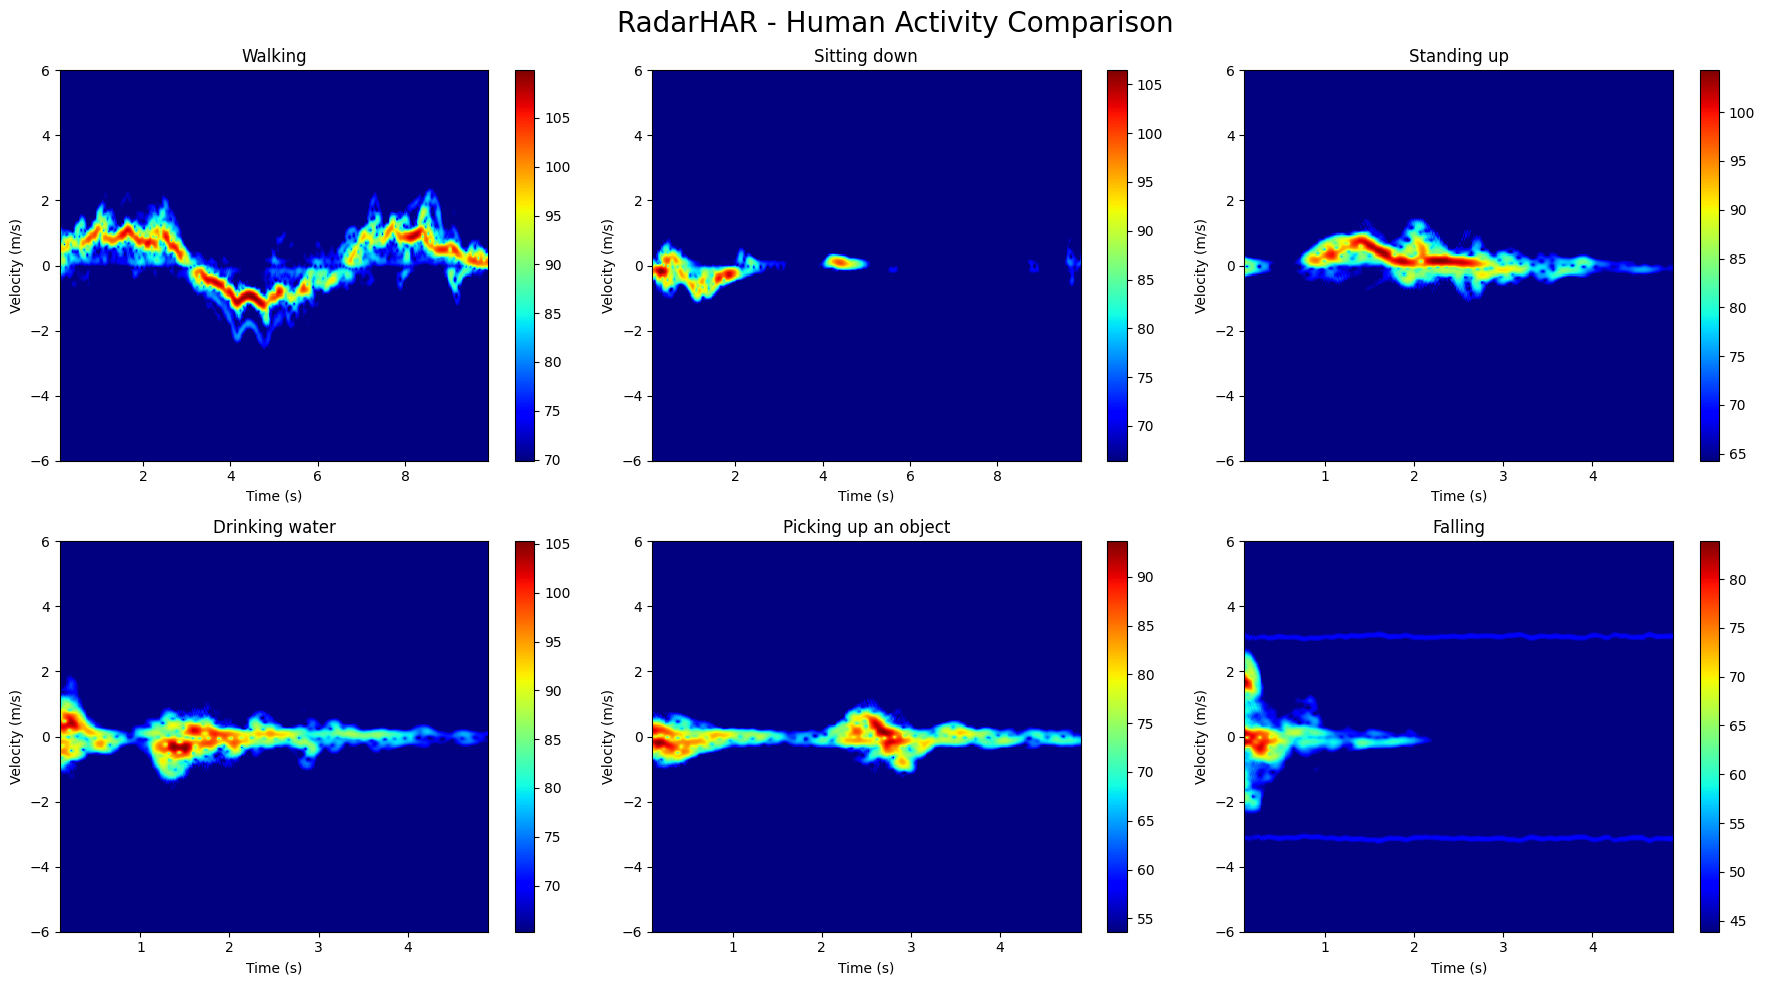

In [35]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

axes = axes.flatten()

for i, (activity_id, activity_name) in enumerate(
    activity_map.items()
):

    sample = df[
        df["activity_id"] == activity_id
    ].iloc[0]

    spec, times, velocity = generate_spectrogram(
        sample["filepath"]
    )

    ax = axes[i]

    plot = ax.pcolormesh(
        times,
        velocity,
        spec,
        shading="auto",
        cmap="jet",
        vmin=spec.max() - 40,
        vmax=spec.max()
    )

    ax.set_ylim(-6, 6)

    ax.set_title(activity_name)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Velocity (m/s)")

    fig.colorbar(plot, ax=ax)

plt.suptitle(
    "RadarHAR - Human Activity Comparison",
    fontsize=20
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" /
    "activity_spectrogram_comparison.png",
    dpi=300
)

plt.show()

In [36]:
from scipy.ndimage import zoom

def preprocess_spectrogram(
    spec,
    velocity,
    target_shape=(128, 128)
):

    # 1. Keep velocities between -6 and +6 m/s
    mask = (
        (velocity >= -6) &
        (velocity <= 6)
    )

    spec = spec[mask, :]

    # 2. Normalize relative to peak magnitude
    spec = spec - spec.max()

    # 3. Keep a 40 dB dynamic range
    spec = np.clip(spec, -40, 0)

    # 4. Scale values between 0 and 1
    spec = (spec + 40) / 40

    # 5. Resize to fixed dimensions
    zoom_factors = (
        target_shape[0] / spec.shape[0],
        target_shape[1] / spec.shape[1]
    )

    spec = zoom(
        spec,
        zoom_factors,
        order=1
    )

    return spec.astype(np.float32)

Original shape: (800, 981)
Processed shape: (128, 128)
Minimum: 0.0
Maximum: 0.98817456
Datatype: float32


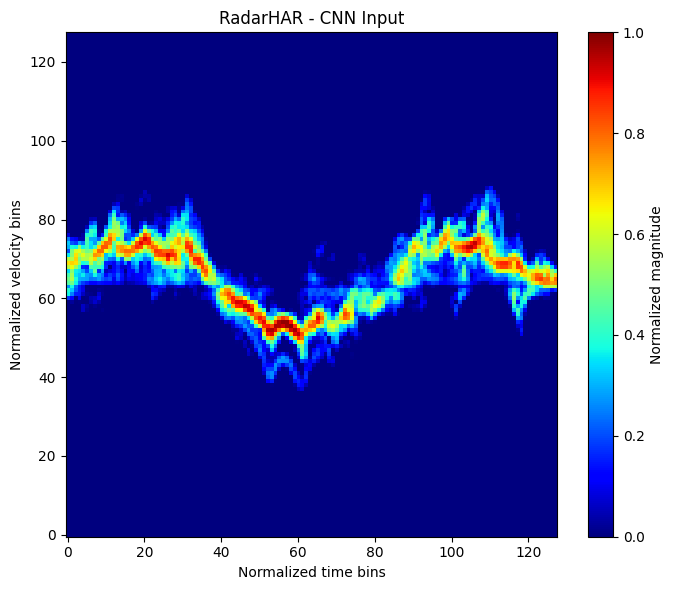

In [37]:
spec, times, velocity = generate_spectrogram(
    radar_files[0]
)

processed_spec = preprocess_spectrogram(
    spec,
    velocity
)

print("Original shape:", spec.shape)
print("Processed shape:", processed_spec.shape)
print("Minimum:", processed_spec.min())
print("Maximum:", processed_spec.max())
print("Datatype:", processed_spec.dtype)

plt.figure(figsize=(7, 6))

plt.imshow(
    processed_spec,
    origin="lower",
    aspect="auto",
    cmap="jet",
    vmin=0,
    vmax=1
)

plt.title("RadarHAR - CNN Input")
plt.xlabel("Normalized time bins")
plt.ylabel("Normalized velocity bins")
plt.colorbar(label="Normalized magnitude")
plt.tight_layout()
plt.show()

DAY-5

In [38]:
from tqdm.auto import tqdm

configurations = []

for file in tqdm(radar_files):

    with open(file, "r") as f:

        fc = float(f.readline())
        sweep_time = float(f.readline())
        nts = int(float(f.readline()))
        bandwidth = float(f.readline())

    configurations.append({
        "filename": file.name,
        "center_frequency": fc,
        "sweep_time_ms": sweep_time,
        "samples_per_sweep": nts,
        "bandwidth": bandwidth
    })

config_df = pd.DataFrame(configurations)

display(
    config_df.drop(columns="filename")
    .value_counts()
    .reset_index(name="count")
)

  0%|          | 0/1754 [00:00<?, ?it/s]

,center_frequency,sweep_time_ms,samples_per_sweep,bandwidth,count
0,5.800000e+09,1.0,128,400000000.0,1694
1,5.800000e+09,1.0,128,100000000.0,60


In [39]:
pilot_df = (
    df.groupby("activity_id", group_keys=False)
    .sample(n=5, random_state=42)
    .reset_index(drop=True)
)

pilot_results = []

for _, row in tqdm(
    pilot_df.iterrows(),
    total=len(pilot_df)
):

    try:

        spec, times, velocity = generate_spectrogram(
            row["filepath"]
        )

        processed = preprocess_spectrogram(
            spec, velocity
        )

        assert processed.shape == (128, 128)
        assert np.isfinite(processed).all()
        assert processed.min() >= 0
        assert processed.max() <= 1

        pilot_results.append({
            "filename": row["filename"],
            "activity": row["activity"],
            "status": "Success"
        })

    except Exception as e:

        pilot_results.append({
            "filename": row["filename"],
            "activity": row["activity"],
            "status": str(e)
        })

pilot_results_df = pd.DataFrame(pilot_results)

print(pilot_results_df["status"].value_counts())

display(
    pilot_results_df[
        pilot_results_df["status"] != "Success"
    ]
)

  0%|          | 0/30 [00:00<?, ?it/s]

status
Success    30
Name: count, dtype: int64


,filename,activity,status


  0%|          | 0/30 [00:00<?, ?it/s]

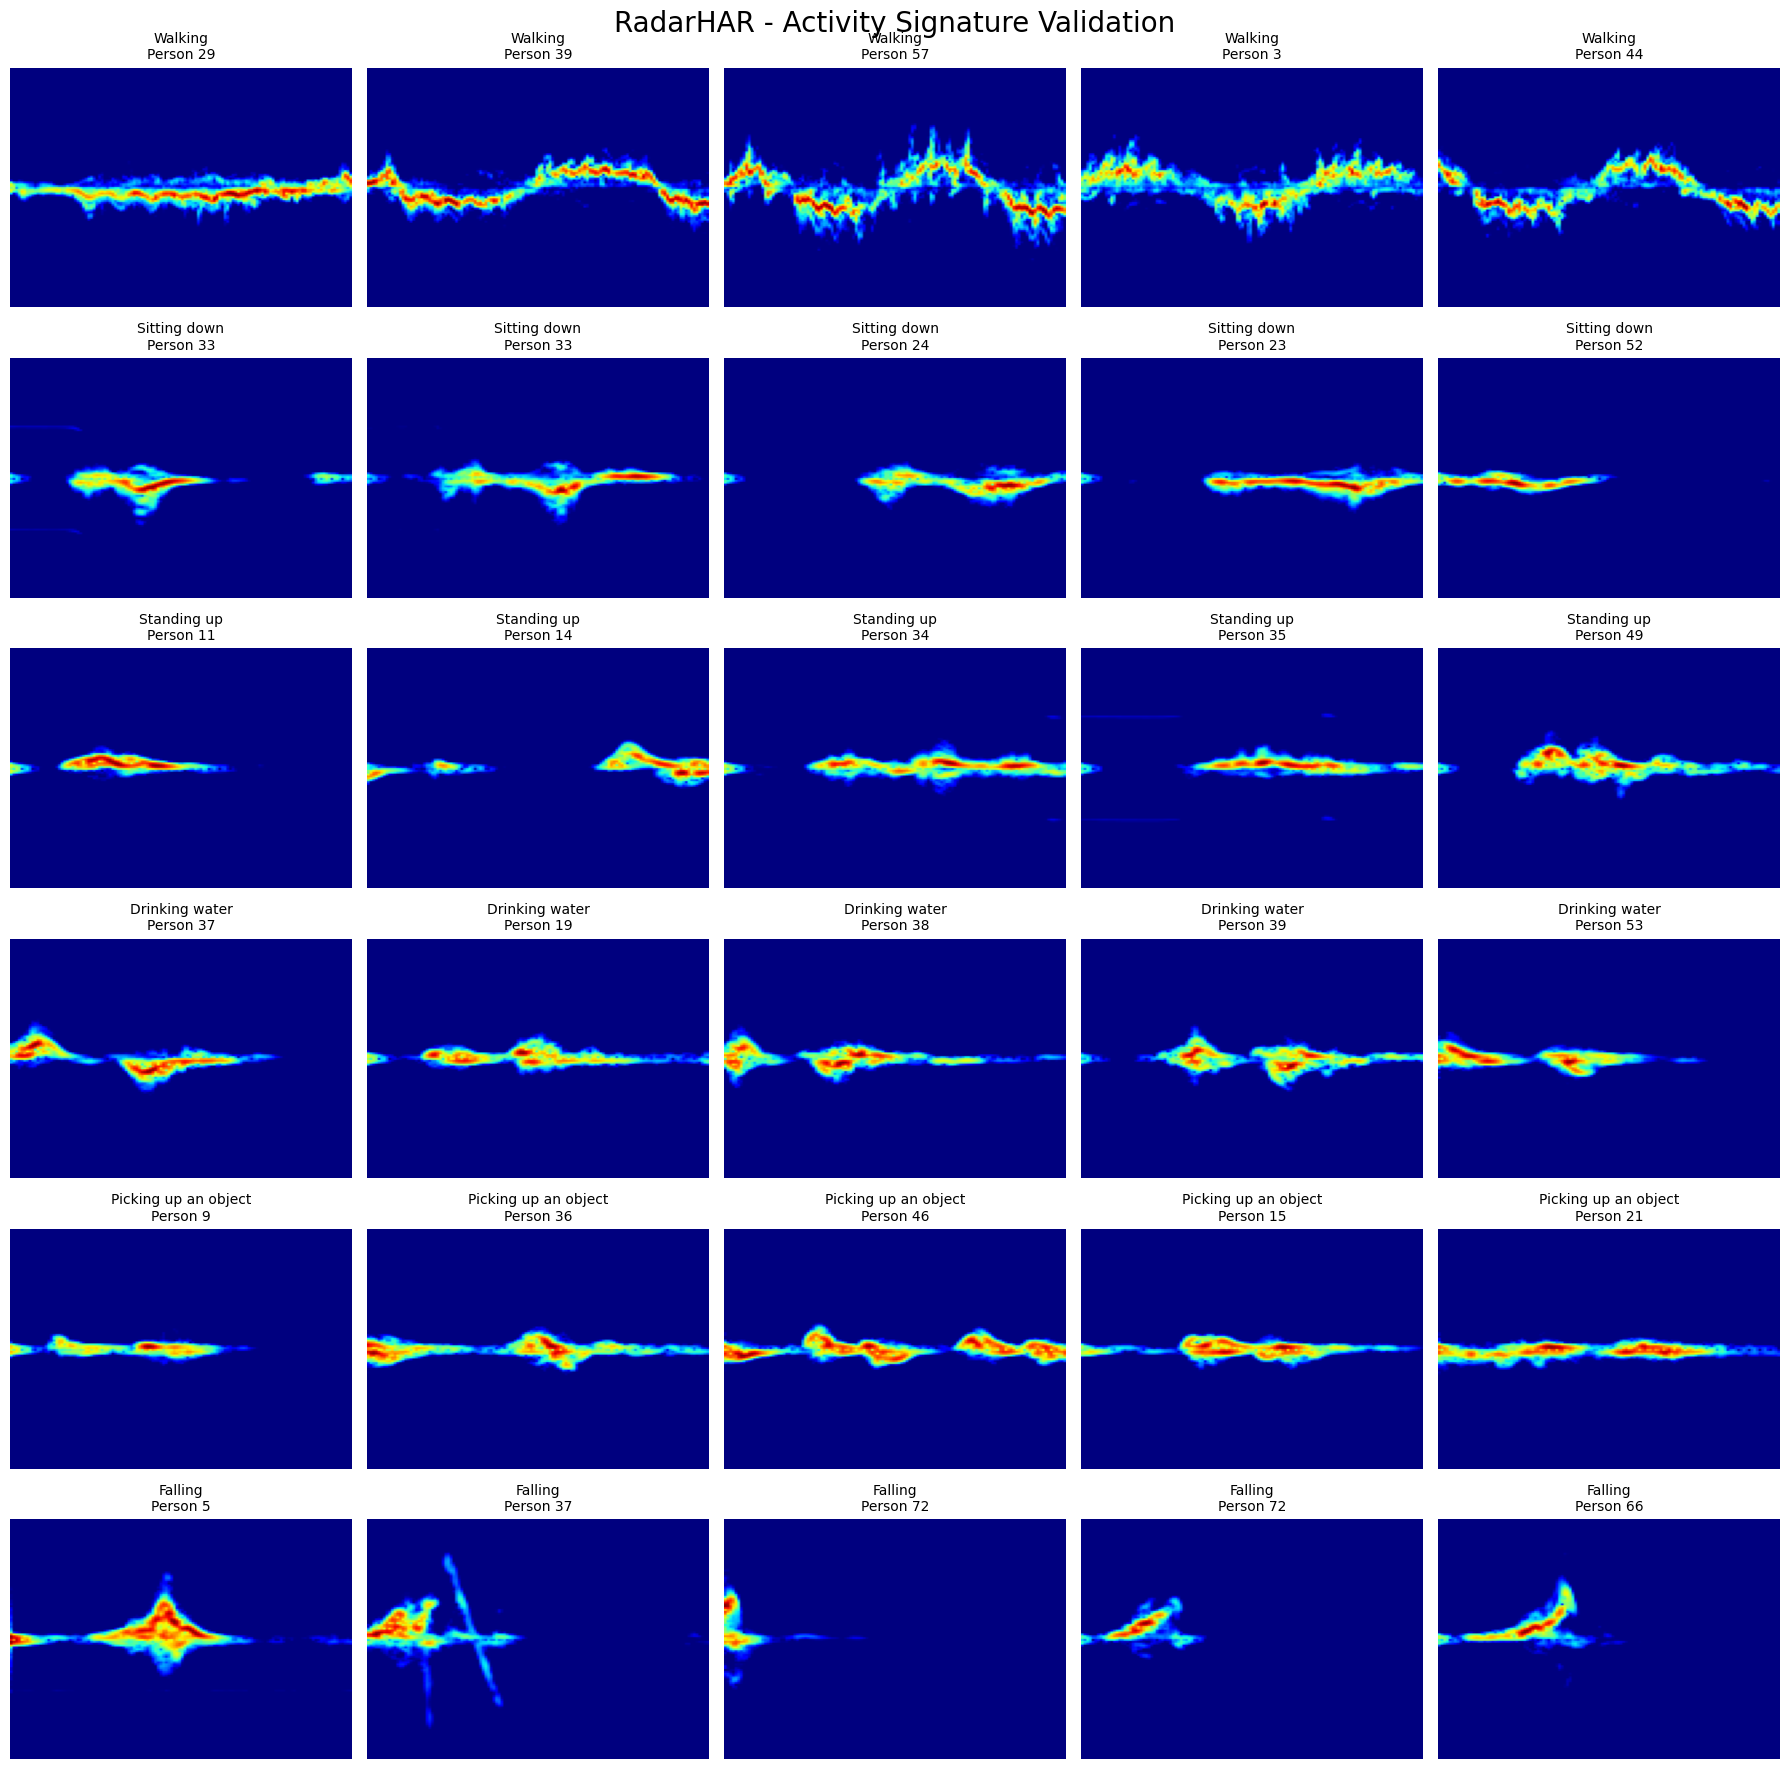

In [40]:
fig, axes = plt.subplots(
    6, 5,
    figsize=(18, 18)
)

for i, (_, row) in enumerate(
    tqdm(pilot_df.iterrows(), total=len(pilot_df))
):

    spec, times, velocity = generate_spectrogram(
        row["filepath"]
    )

    processed = preprocess_spectrogram(
        spec, velocity
    )

    ax = axes.flatten()[i]

    ax.imshow(
        processed,
        origin="lower",
        aspect="auto",
        cmap="jet",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"{row['activity']}\n"
        f"Person {row['person_id']}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "RadarHAR - Activity Signature Validation",
    fontsize=20
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" /
    "pilot_validation.png",
    dpi=200
)

plt.show()

In [41]:
participant_summary = pd.crosstab(
    df["person_id"],
    df["activity"]
)

display(participant_summary)

print(
    "Unique participant IDs:",
    df["person_id"].nunique()
)

print("\nParticipants per collection:")

print(
    df.groupby("collection")["person_id"]
    .nunique()
)

activity,Drinking water,Falling,Picking up an object,Sitting down,Standing up,Walking
person_id,,,,,,
1,3,3,3,3,3,3
2,3,3,3,3,3,3
3,5,5,5,7,4,5
4,3,3,3,3,3,3
5,3,3,3,3,3,3
...,...,...,...,...,...,...
68,3,3,3,3,3,3
69,3,3,3,3,3,3
70,3,3,3,3,3,3


Unique participant IDs: 72

Participants per collection:
collection
1 December 2017 Dataset              20
2 March 2017 Dataset                  4
3 June 2017 Dataset                   9
4 July 2018 Dataset                  16
5 February 2019 UoG Dataset          17
6 February 2019 NG Homes Dataset     20
7 March 2019 West Cumbria Dataset    20
Name: person_id, dtype: int64


DAY-6

In [42]:
from scipy.fft import fft, fftshift
from scipy.signal import butter, sosfilt, stft

def generate_spectrogram(filepath):

    signal, params = load_radar_data(filepath)

    NTS = params["samples_per_sweep"]
    prf = params["prf"]

    if len(signal) % NTS != 0:
        raise ValueError("Incomplete radar chirp")

    # 1. Reshape radar signal
    num_chirps = len(signal) // NTS

    data_time = signal.reshape(
        num_chirps, NTS
    ).T

    # 2. Range FFT
    range_fft = fftshift(
        fft(data_time, axis=0),
        axes=0
    )

    data_range = range_fft[NTS // 2:, :]

    # 3. MTI filtering
    sos = butter(
        4, 0.0075,
        btype="highpass",
        output="sos"
    )

    data_mti = sosfilt(
        sos, data_range, axis=1
    )[1:, :]

    # 4. Calculate physical range
    range_resolution = (
        3e8 / (2 * params["bandwidth"])
    )

    ranges = (
        np.arange(1, NTS // 2)
        * range_resolution
    )

    selected_bins = np.where(
        (ranges >= 3.75) &
        (ranges <= 11.25)
    )[0]

    if len(selected_bins) == 0:
        raise ValueError("No valid range bins")

    # 5. Micro-Doppler STFT
    spectrogram_sum = None

    for rbin in selected_bins:

        frequencies, times, Zxx = stft(
            data_mti[rbin, :],
            fs=prf,
            window="hamming",
            nperseg=200,
            noverlap=190,
            nfft=800,
            return_onesided=False,
            boundary=None,
            padded=False
        )

        magnitude = np.abs(
            fftshift(Zxx, axes=0)
        )

        if spectrogram_sum is None:
            spectrogram_sum = magnitude
        else:
            spectrogram_sum += magnitude

    # 6. Velocity axis
    velocity_axis = (
        fftshift(frequencies) * 3e8
        / (2 * params["center_frequency"])
    )

    # Match reference sign convention
    spectrogram_sum = np.flipud(
        spectrogram_sum
    )

    velocity_axis = -velocity_axis[::-1]

    # 7. Convert to decibels
    spectrogram_db = 20 * np.log10(
        spectrogram_sum + 1e-10
    )

    return spectrogram_db, times, velocity_axis

Bandwidth: 400.0 MHz
Activity: Walking
Shape: (128, 128)
Finite: True


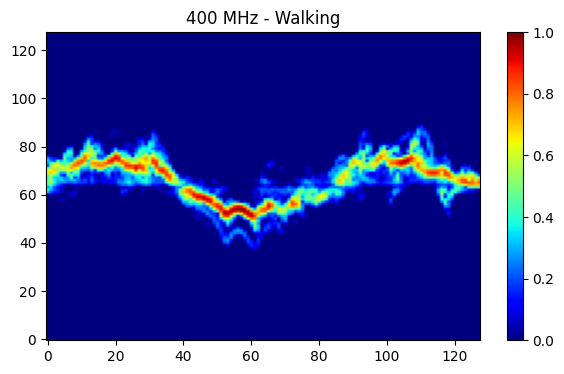

Bandwidth: 100.0 MHz
Activity: Walking
Shape: (128, 128)
Finite: True


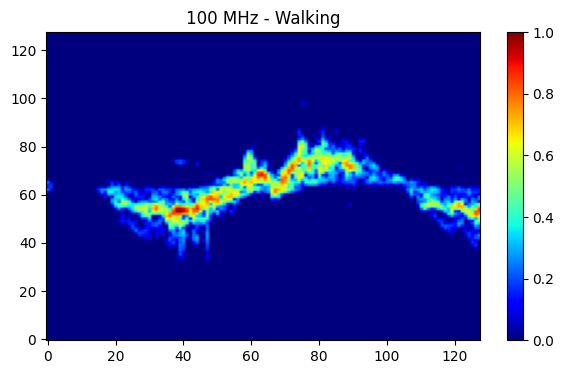

In [43]:
for bandwidth in [400e6, 100e6]:

    sample = config_df[
        config_df["bandwidth"] == bandwidth
    ].iloc[0]

    row = df[
        df["filename"] == sample["filename"]
    ].iloc[0]

    spec, times, velocity = generate_spectrogram(
        row["filepath"]
    )

    processed = preprocess_spectrogram(
        spec, velocity
    )

    print("Bandwidth:", bandwidth / 1e6, "MHz")
    print("Activity:", row["activity"])
    print("Shape:", processed.shape)
    print("Finite:", np.isfinite(processed).all())

    plt.figure(figsize=(7, 4))

    plt.imshow(
        processed,
        origin="lower",
        aspect="auto",
        cmap="jet",
        vmin=0,
        vmax=1
    )

    plt.title(
        f"{bandwidth / 1e6:.0f} MHz - "
        f"{row['activity']}"
    )

    plt.colorbar()
    plt.show()

In [44]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/RadarHAR"
)

SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Permanent storage:", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Permanent storage: /content/drive/MyDrive/RadarHAR


In [45]:
df["subject_session"] = (
    df["collection"] + "_P" +
    df["person_id"].astype(str)
)

df["group_id"] = df["person_id"]

print("Numerical participant IDs:",
      df["person_id"].nunique())

print("Participant-session combinations:",
      df["subject_session"].nunique())

df.to_csv(
    SAVE_DIR / "metadata.csv",
    index=False
)

Numerical participant IDs: 72
Participant-session combinations: 106


In [46]:
BATCH_SIZE = 100

BATCH_DIR = SAVE_DIR / "batches_v1"

BATCH_DIR.mkdir(exist_ok=True)

for start in tqdm(
    range(0, len(df), BATCH_SIZE)
):

    end = min(start + BATCH_SIZE, len(df))

    batch_path = BATCH_DIR / (
        f"batch_{start:04d}_{end:04d}.npz"
    )

    # Skip previously completed batches
    if batch_path.exists():
        print("Skipping:", batch_path.name)
        continue

    X_batch = []
    y_batch = []
    groups_batch = []
    indices_batch = []
    errors = []

    for idx in range(start, end):

        row = df.iloc[idx]

        try:

            spec, times, velocity = (
                generate_spectrogram(
                    row["filepath"]
                )
            )

            processed = preprocess_spectrogram(
                spec, velocity
            )

            assert processed.shape == (128, 128)
            assert np.isfinite(processed).all()
            assert processed.min() >= 0
            assert processed.max() <= 1

            X_batch.append(processed)

            y_batch.append(
                row["activity_id"] - 1
            )

            groups_batch.append(
                row["group_id"]
            )

            indices_batch.append(idx)

        except Exception as e:

            errors.append({
                "index": idx,
                "filename": row["filename"],
                "error": str(e)
            })

    pd.DataFrame(
        errors,
        columns=["index", "filename", "error"]
    ).to_csv(
        BATCH_DIR / f"errors_{start:04d}.csv",
        index=False
    )

    np.savez_compressed(
        batch_path,
        X=np.asarray(
            X_batch, dtype=np.float32
        ).reshape(-1, 128, 128),
        y=np.array(y_batch, dtype=np.int64),
        groups=np.array(
            groups_batch, dtype=np.int64
        ),
        indices=np.array(
            indices_batch, dtype=np.int64
        )
    )

    print(
        f"Batch {start}-{end}: "
        f"{len(X_batch)} successful, "
        f"{len(errors)} failed"
    )

print("Batch processing completed!")

  0%|          | 0/18 [00:00<?, ?it/s]

Batch 0-100: 100 successful, 0 failed
Batch 100-200: 100 successful, 0 failed
Batch 200-300: 100 successful, 0 failed
Batch 300-400: 100 successful, 0 failed
Batch 400-500: 100 successful, 0 failed
Batch 500-600: 100 successful, 0 failed
Batch 600-700: 100 successful, 0 failed
Batch 700-800: 100 successful, 0 failed
Batch 800-900: 100 successful, 0 failed
Batch 900-1000: 100 successful, 0 failed
Batch 1000-1100: 100 successful, 0 failed
Batch 1100-1200: 100 successful, 0 failed
Batch 1200-1300: 100 successful, 0 failed
Batch 1300-1400: 100 successful, 0 failed
Batch 1400-1500: 100 successful, 0 failed
Batch 1500-1600: 100 successful, 0 failed
Batch 1600-1700: 100 successful, 0 failed
Batch 1700-1754: 54 successful, 0 failed
Batch processing completed!


In [47]:
batch_files = sorted(
    BATCH_DIR.glob("batch_*.npz")
)

X_list = []
y_list = []
groups_list = []
indices_list = []

for file in batch_files:

    with np.load(file) as batch:

        X_list.append(batch["X"])
        y_list.append(batch["y"])
        groups_list.append(batch["groups"])
        indices_list.append(batch["indices"])

X = np.concatenate(X_list)
y = np.concatenate(y_list)
groups = np.concatenate(groups_list)
indices = np.concatenate(indices_list)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Groups shape:", groups.shape)

print("Data type:", X.dtype)
print("All finite:", np.isfinite(X).all())

print("Minimum:", X.min())
print("Maximum:", X.max())

print("Processed recordings:", len(X))
print("Missing recordings:", len(df) - len(X))

assert len(np.unique(indices)) == len(indices)

print("\nClass distribution:")

for label, count in zip(
    *np.unique(y, return_counts=True)
):

    print(activity_map[label + 1], ":", count)

X shape: (1754, 128, 128)
y shape: (1754,)
Groups shape: (1754,)
Data type: float32
All finite: True
Minimum: 0.0
Maximum: 0.99998665
Processed recordings: 1754
Missing recordings: 0

Class distribution:
Walking : 312
Sitting down : 312
Standing up : 311
Drinking water : 311
Picking up an object : 311
Falling : 197


In [48]:
np.savez_compressed(
    SAVE_DIR / "RadarHAR_dataset_v1.npz",
    X=X,
    y=y,
    groups=groups,
    indices=indices
)

print("Dataset saved successfully!")

print(
    "Uncompressed array size:",
    round(X.nbytes / 1024**2, 2),
    "MB"
)

Dataset saved successfully!
Uncompressed array size: 109.62 MB


DAY-7

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/RadarHAR"
)

with np.load(
    SAVE_DIR / "RadarHAR_dataset_v1.npz"
) as data:

    X = data["X"]
    y = data["y"]
    groups = data["groups"]
    indices = data["indices"]

metadata = pd.read_csv(
    SAVE_DIR / "metadata.csv"
)

metadata = metadata.iloc[indices].reset_index(
    drop=True
)

class_names = [
    "Walking",
    "Sitting down",
    "Standing up",
    "Drinking water",
    "Picking up an object",
    "Falling"
]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Group IDs:", len(np.unique(groups)))
print("Dataset loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X shape: (1754, 128, 128)
y shape: (1754,)
Group IDs: 72
Dataset loaded successfully!


In [50]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(X, y, groups)
)

second_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative, test_relative = next(
    second_split.split(
        X[temp_idx],
        y[temp_idx],
        groups[temp_idx]
    )
)

val_idx = temp_idx[val_relative]
test_idx = temp_idx[test_relative]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

for name, idx in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:

    print(f"\n{name} set")
    print("Recordings:", len(idx))
    print("Group IDs:", len(np.unique(groups[idx])))

    print(
        pd.Series(y[idx])
        .value_counts()
        .sort_index()
    )


Training set
Recordings: 1194
Group IDs: 50
0    213
1    214
2    210
3    213
4    211
5    133
Name: count, dtype: int64

Validation set
Recordings: 301
Group IDs: 11
0    54
1    54
2    54
3    52
4    54
5    33
Name: count, dtype: int64

Testing set
Recordings: 259
Group IDs: 11
0    45
1    44
2    47
3    46
4    46
5    31
Name: count, dtype: int64


In [51]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print(
    "Train-Validation overlap:",
    len(train_groups & val_groups)
)

print(
    "Train-Test overlap:",
    len(train_groups & test_groups)
)

print(
    "Validation-Test overlap:",
    len(val_groups & test_groups)
)

assert not train_groups & val_groups
assert not train_groups & test_groups
assert not val_groups & test_groups

for labels in [y_train, y_val, y_test]:
    assert len(np.unique(labels)) == 6

np.savez(
    SAVE_DIR / "dataset_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Split validation passed!")

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0
Split validation passed!


In [52]:
from skimage.feature import hog
from tqdm.auto import tqdm

def extract_features(image):

    # HOG features
    hog_features = hog(
        image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    # Statistical features
    statistical_features = [
        np.mean(image),
        np.std(image),
        np.max(image),
        np.median(image),
        np.percentile(image, 25),
        np.percentile(image, 75),
        np.percentile(image, 90),
        np.mean(image ** 2),
        np.mean(image > 0.5)
    ]

    # Velocity and time profiles
    velocity_profile = np.mean(
        image, axis=1
    )

    time_profile = np.mean(
        image, axis=0
    )

    return np.concatenate([
        hog_features,
        statistical_features,
        velocity_profile,
        time_profile
    ])

sample_features = extract_features(X[0])

print("Original shape:", X[0].shape)
print("Original values:", X[0].size)
print("Feature vector shape:", sample_features.shape)
print("All finite:", np.isfinite(sample_features).all())

Original shape: (128, 128)
Original values: 16384
Feature vector shape: (2029,)
All finite: True


In [53]:
X_features = np.array([
    extract_features(image)
    for image in tqdm(X)
], dtype=np.float32)

print("Feature dataset:", X_features.shape)
print("All finite:", np.isfinite(X_features).all())

X_train_features = X_features[train_idx]
X_val_features = X_features[val_idx]
X_test_features = X_features[test_idx]

np.save(
    SAVE_DIR / "extracted_features.npy",
    X_features
)

print("Feature extraction completed!")

  0%|          | 0/1754 [00:00<?, ?it/s]

Feature dataset: (1754, 2029)
All finite: True
Feature extraction completed!


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score

import time

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(
    X_train_features,
    y_train
)

rf_training_time = time.time() - start_time

rf_train_pred = rf_model.predict(
    X_train_features
)

rf_val_pred = rf_model.predict(
    X_val_features
)

print("Random Forest Results")

print(
    "Training accuracy:",
    accuracy_score(y_train, rf_train_pred)
)

print(
    "Validation accuracy:",
    accuracy_score(y_val, rf_val_pred)
)

print(
    "Validation macro F1:",
    f1_score(y_val, rf_val_pred, average="macro")
)

print(
    "Training time:",
    round(rf_training_time, 2),
    "seconds"
)

Random Forest Results
Training accuracy: 1.0
Validation accuracy: 0.9036544850498339
Validation macro F1: 0.9055643981654381
Training time: 12.71 seconds


In [55]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

svm_model = Pipeline([
    ("scaler", StandardScaler()),

    ("svm", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced",
        random_state=42
    ))
])

start_time = time.time()

svm_model.fit(
    X_train_features,
    y_train
)

svm_training_time = time.time() - start_time

svm_train_pred = svm_model.predict(
    X_train_features
)

svm_val_pred = svm_model.predict(
    X_val_features
)

print("SVM Results")

print(
    "Training accuracy:",
    accuracy_score(y_train, svm_train_pred)
)

print(
    "Validation accuracy:",
    accuracy_score(y_val, svm_val_pred)
)

print(
    "Validation macro F1:",
    f1_score(y_val, svm_val_pred, average="macro")
)

print(
    "Training time:",
    round(svm_training_time, 2),
    "seconds"
)

SVM Results
Training accuracy: 0.9958123953098827
Validation accuracy: 0.840531561461794
Validation macro F1: 0.8404168790869081
Training time: 1.48 seconds


In [56]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

results = []

for name, predictions, duration in [
    ("Random Forest", rf_val_pred, rf_training_time),
    ("SVM", svm_val_pred, svm_training_time)
]:

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "Precision": precision_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),

        "Training Time (s)": duration
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    SAVE_DIR / "baseline_results.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s)
0,Random Forest,0.9037,0.9067,0.9066,0.9056,12.7108
1,SVM,0.8405,0.8512,0.8357,0.8404,1.4757


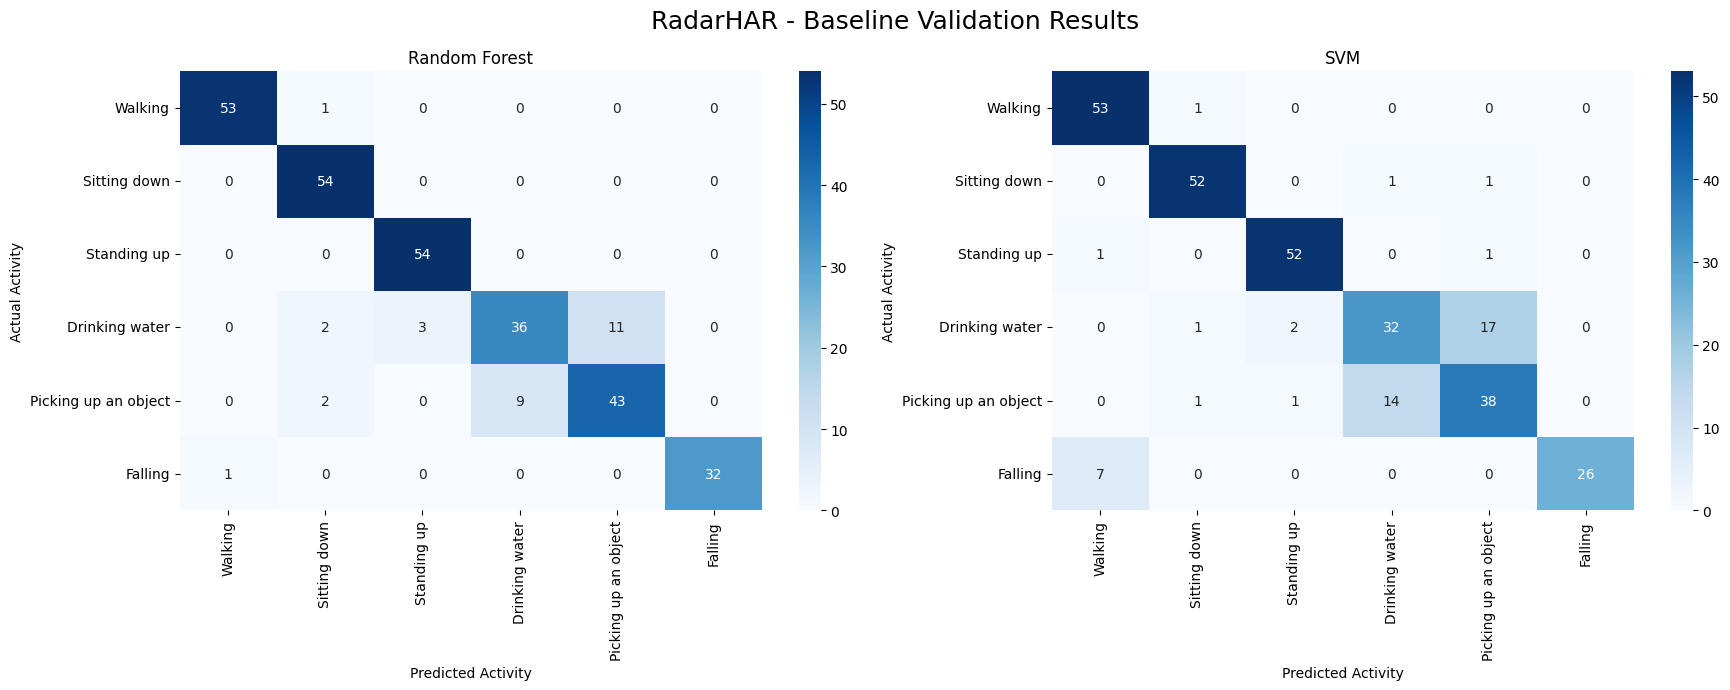


 Random Forest
                      precision    recall  f1-score   support

             Walking       0.98      0.98      0.98        54
        Sitting down       0.92      1.00      0.96        54
         Standing up       0.95      1.00      0.97        54
      Drinking water       0.80      0.69      0.74        52
Picking up an object       0.80      0.80      0.80        54
             Falling       1.00      0.97      0.98        33

            accuracy                           0.90       301
           macro avg       0.91      0.91      0.91       301
        weighted avg       0.90      0.90      0.90       301


 SVM
                      precision    recall  f1-score   support

             Walking       0.87      0.98      0.92        54
        Sitting down       0.95      0.96      0.95        54
         Standing up       0.95      0.96      0.95        54
      Drinking water       0.68      0.62      0.65        52
Picking up an object       0.67      0.70   

In [57]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 7)
)

for ax, name, predictions in zip(
    axes,
    ["Random Forest", "SVM"],
    [rf_val_pred, svm_val_pred]
):

    cm = confusion_matrix(
        y_val, predictions,
        labels=np.arange(6)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Activity")
    ax.set_ylabel("Actual Activity")

plt.suptitle(
    "RadarHAR - Baseline Validation Results",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "baseline_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

for name, predictions in [
    ("Random Forest", rf_val_pred),
    ("SVM", svm_val_pred)
]:

    print("\n", name)

    print(
        classification_report(
            y_val,
            predictions,
            labels=np.arange(6),
            target_names=class_names,
            zero_division=0
        )
    )

In [58]:
import joblib

MODEL_DIR = SAVE_DIR / "models"

MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest.joblib"
)

joblib.dump(
    svm_model,
    MODEL_DIR / "svm_model.joblib"
)

print("Random Forest saved successfully!")
print("SVM saved successfully!")

Random Forest saved successfully!
SVM saved successfully!


DAY-8

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path
from google.colab import drive

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)

print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/RadarHAR"
)

MODEL_DIR = SAVE_DIR / "models"

MODEL_DIR.mkdir(exist_ok=True)

with np.load(
    SAVE_DIR / "RadarHAR_dataset_v1.npz"
) as data:

    X = data["X"]
    y = data["y"]
    groups = data["groups"]

with np.load(
    SAVE_DIR / "dataset_splits.npz"
) as splits:

    train_idx = splits["train_idx"]
    val_idx = splits["val_idx"]
    test_idx = splits["test_idx"]

class_names = [
    "Walking",
    "Sitting down",
    "Standing up",
    "Drinking water",
    "Picking up an object",
    "Falling"
]

print("Dataset:", X.shape)
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

Mounted at /content/drive
Dataset: (1754, 128, 128)
Training: 1194
Validation: 301
Testing: 259


In [3]:
X_cnn = np.expand_dims(X, axis=-1)

X_train = X_cnn[train_idx]
X_val = X_cnn[val_idx]
X_test = X_cnn[test_idx]

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Training: (1194, 128, 128, 1)
Validation: (301, 128, 128, 1)
Testing: (259, 128, 128, 1)
Minimum: 0.0
Maximum: 0.9999176


In [4]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

for label, weight in class_weights.items():

    print(
        class_names[label],
        ":",
        round(weight, 4)
    )

Walking : 0.9343
Sitting down : 0.9299
Standing up : 0.9476
Drinking water : 0.9343
Picking up an object : 0.9431
Falling : 1.4962


In [5]:
cnn_model = keras.Sequential([

    layers.Input(shape=(128, 128, 1)),

    # Convolutional Block 1
    layers.Conv2D(
        32, (3, 3), padding="same"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.15),

    # Convolutional Block 2
    layers.Conv2D(
        64, (3, 3), padding="same"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    # Convolutional Block 3
    layers.Conv2D(
        128, (3, 3), padding="same"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Classification Head
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),

    layers.Dense(6, activation="softmax")

], name="RadarHAR_CNN")

cnn_model.summary()

Model: "RadarHAR_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,854 (433.02 KB)

 Trainable params: 110,406 (431.27 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
cnn_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN compiled successfully!")

CNN compiled successfully!


In [7]:
from sklearn.metrics import f1_score

class MacroF1Callback(keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            logs = {}

        probabilities = self.model.predict(
            X_val,
            batch_size=32,
            verbose=0
        )

        predictions = np.argmax(
            probabilities, axis=1
        )

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        logs["val_macro_f1"] = macro_f1

        print(
            f" - val_macro_f1: {macro_f1:.4f}"
        )


callbacks = [

    MacroF1Callback(),

    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "best_cnn.keras"
        ),
        monitor="val_macro_f1",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        mode="max",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

In [8]:
import time

start_time = time.time()

history = cnn_model.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=80,

    batch_size=32,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)

cnn_training_time = time.time() - start_time

print(
    "Total training time:",
    round(cnn_training_time / 60, 2),
    "minutes"
)

Epoch 1/80
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step - accuracy: 0.3058 - loss: 1.6506 - val_macro_f1: 0.0329

Epoch 1: val_macro_f1 improved from None to 0.03293, saving model to /content/drive/MyDrive/RadarHAR/models/best_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RadarHAR/models/best_cnn.keras
38/38 ━━━━━━━━━━━━━━━━━━━━ 47s 564ms/step - accuracy: 0.3576 - loss: 1.5442 - val_accuracy: 0.1096 - val_loss: 1.8631 - val_macro_f1: 0.0329 - learning_rate: 0.0010
Epoch 2/80
36/38 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4441 - loss: 1.3365 - val_macro_f1: 0.0329

Epoch 2: val_macro_f1 did not improve from 0.03293
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.4757 - loss: 1.2912 - val_accuracy: 0.1096 - val_loss: 2.2162 - val_macro_f1: 0.0329 - learning_rate: 0.0010
Epoch 3/80
37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4928 - loss: 1.2111 - val_macro_f1: 0.0329

Epoch 3: val_macro_f1 did not improve from 0.03293
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 

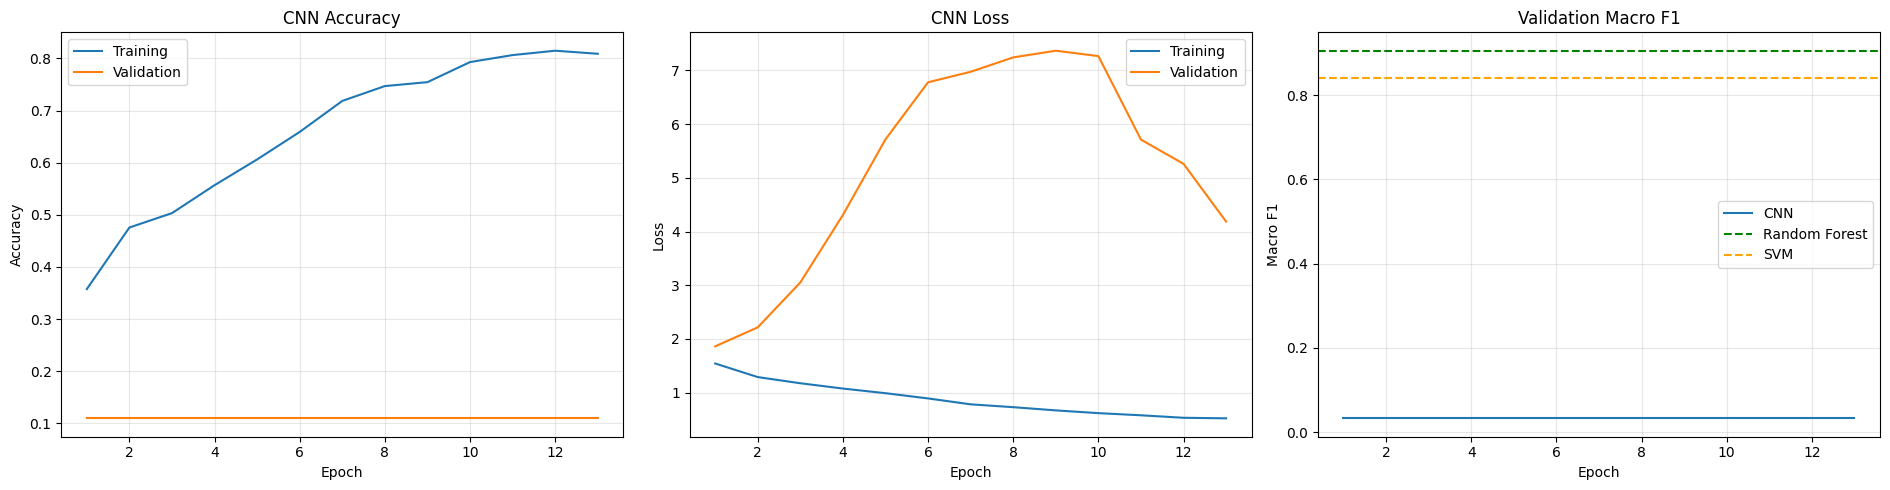

In [9]:
history_df = pd.DataFrame(
    history.history
)

history_df.to_csv(
    SAVE_DIR / "cnn_training_history.csv",
    index=False
)

fig, axes = plt.subplots(
    1, 3, figsize=(19, 5)
)

epochs = np.arange(
    1, len(history_df) + 1
)

# Accuracy
axes[0].plot(
    epochs, history_df["accuracy"],
    label="Training"
)

axes[0].plot(
    epochs, history_df["val_accuracy"],
    label="Validation"
)

axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    epochs, history_df["loss"],
    label="Training"
)

axes[1].plot(
    epochs, history_df["val_loss"],
    label="Validation"
)

axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Macro F1
axes[2].plot(
    epochs,
    history_df["val_macro_f1"],
    label="CNN"
)

axes[2].axhline(
    0.905564398,
    linestyle="--",
    color="green",
    label="Random Forest"
)

axes[2].axhline(
    0.840416879,
    linestyle="--",
    color="orange",
    label="SVM"
)

axes[2].set_title("Validation Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro F1")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "cnn_training_curves.png",
    dpi=200
)

plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_cnn = keras.models.load_model(
    MODEL_DIR / "best_cnn.keras"
)

cnn_val_probabilities = best_cnn.predict(
    X_val,
    verbose=0
)

cnn_val_pred = np.argmax(
    cnn_val_probabilities,
    axis=1
)

cnn_train_pred = np.argmax(
    best_cnn.predict(X_train, verbose=0),
    axis=1
)

cnn_results = {

    "Model": "CNN",

    "Accuracy": accuracy_score(
        y_val, cnn_val_pred
    ),

    "Precision": precision_score(
        y_val, cnn_val_pred,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_val, cnn_val_pred,
        average="macro",
        zero_division=0
    ),

    "F1 Score": f1_score(
        y_val, cnn_val_pred,
        average="macro"
    ),

    "Training Time (s)": cnn_training_time
}

print(
    "Training accuracy:",
    accuracy_score(y_train, cnn_train_pred)
)

print(
    "Validation accuracy:",
    cnn_results["Accuracy"]
)

print(
    "Validation macro F1:",
    cnn_results["F1 Score"]
)

print(
    classification_report(
        y_val,
        cnn_val_pred,
        labels=np.arange(6),
        target_names=class_names,
        zero_division=0
    )
)

Training accuracy: 0.11139028475711893
Validation accuracy: 0.10963455149501661
Validation macro F1: 0.03293413173652695
                      precision    recall  f1-score   support

             Walking       0.00      0.00      0.00        54
        Sitting down       0.00      0.00      0.00        54
         Standing up       0.00      0.00      0.00        54
      Drinking water       0.00      0.00      0.00        52
Picking up an object       0.00      0.00      0.00        54
             Falling       0.11      1.00      0.20        33

            accuracy                           0.11       301
           macro avg       0.02      0.17      0.03       301
        weighted avg       0.01      0.11      0.02       301



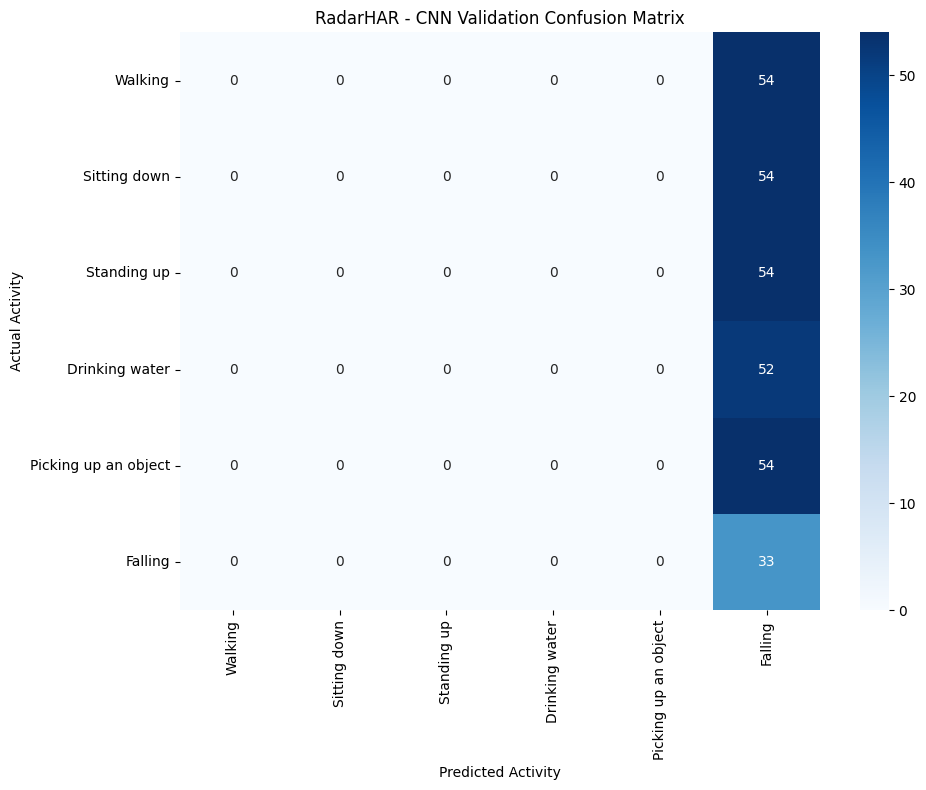

In [11]:
cm = confusion_matrix(
    y_val,
    cnn_val_pred,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "RadarHAR - CNN Validation Confusion Matrix"
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "cnn_confusion_matrix.png",
    dpi=200
)

plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s)
0,Random Forest,0.9037,0.9067,0.9066,0.9056,12.7108
1,SVM,0.8405,0.8512,0.8357,0.8404,1.4757
2,CNN,0.1096,0.0183,0.1667,0.0329,65.2678


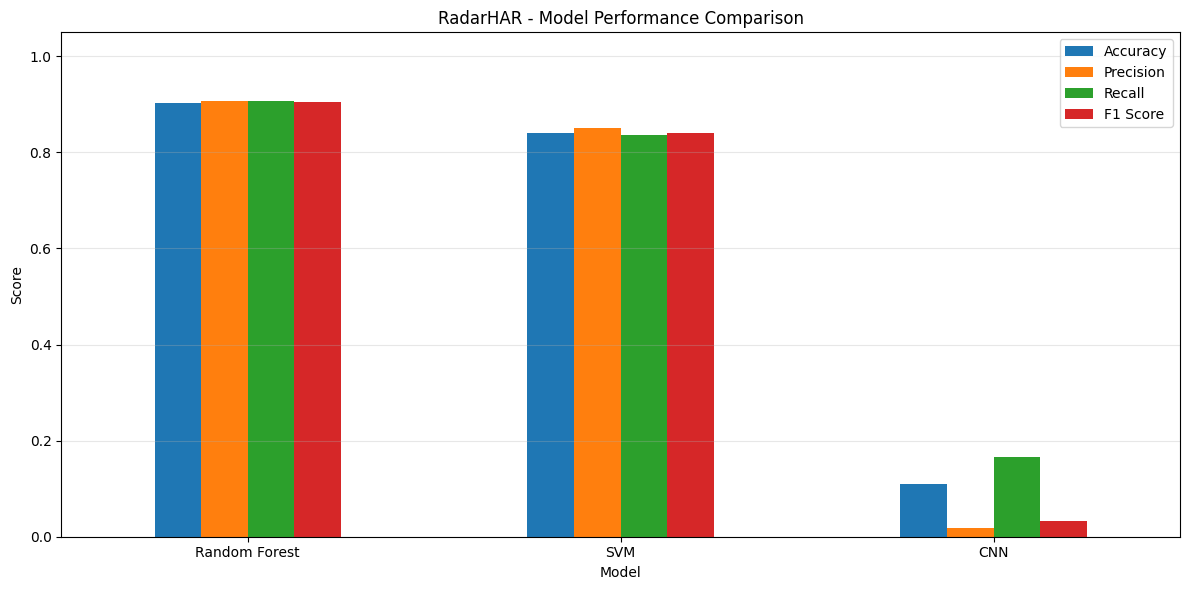

Best CNN saved successfully!


In [12]:
baseline_results = pd.read_csv(
    SAVE_DIR / "baseline_results.csv"
)

comparison_df = pd.concat([

    baseline_results,

    pd.DataFrame([cnn_results])

], ignore_index=True)

display(comparison_df.round(4))

comparison_df.to_csv(
    SAVE_DIR / "model_comparison.csv",
    index=False
)

comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    rot=0
)

plt.title("RadarHAR - Model Performance Comparison")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    SAVE_DIR / "model_comparison.png",
    dpi=200
)

plt.show()

print("Best CNN saved successfully!")

Fixing failures

In [13]:
import shutil

V1_DIR = SAVE_DIR / "experiments" / "cnn_v1"
V1_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    MODEL_DIR / "best_cnn.keras",
    V1_DIR / "best_cnn.keras"
)

for filename in [
    "cnn_training_history.csv",
    "cnn_training_curves.png",
    "cnn_confusion_matrix.png",
    "model_comparison.csv",
    "model_comparison.png"
]:
    source = SAVE_DIR / filename

    if source.exists():
        shutil.copy2(source, V1_DIR / filename)

print("CNN V1 experiment preserved!")

CNN V1 experiment preserved!


In [14]:
from sklearn.metrics import accuracy_score, f1_score

diagnostic_model = keras.models.clone_model(best_cnn)
diagnostic_model.set_weights(best_cnn.get_weights())

X_debug = X_val[:64]
y_debug = y_val[:64]

for mode in [False, True]:

    probabilities = diagnostic_model(
        X_debug,
        training=mode
    ).numpy()

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    print("\nTraining mode:", mode)

    print(
        "Accuracy:",
        accuracy_score(y_debug, predictions)
    )

    print(
        "Prediction distribution:",
        np.bincount(predictions, minlength=6)
    )

    print(
        "Average class probabilities:",
        probabilities.mean(axis=0).round(4)
    )


Training mode: False
Accuracy: 0.0625
Prediction distribution: [ 0  0  0  0  0 64]
Average class probabilities: [0.0967 0.1885 0.1839 0.1339 0.1454 0.2516]

Training mode: True
Accuracy: 0.5
Prediction distribution: [12  8  4  7 10 23]
Average class probabilities: [0.2109 0.1566 0.1358 0.1508 0.1563 0.1896]


In [15]:
for name, data in [
    ("Training", X_train),
    ("Validation", X_val)
]:

    print("\n", name)

    print("Shape:", data.shape)
    print("Mean:", data.mean())
    print("Standard deviation:", data.std())
    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("All finite:", np.isfinite(data).all())

    print(
        "Percentage of zero values:",
        round(np.mean(data == 0) * 100, 2)
    )


 Training
Shape: (1194, 128, 128, 1)
Mean: 0.030468415
Standard deviation: 0.123483606
Minimum: 0.0
Maximum: 0.9999176
All finite: True
Percentage of zero values: 91.24

 Validation
Shape: (301, 128, 128, 1)
Mean: 0.031277154
Standard deviation: 0.12527783
Minimum: 0.0
Maximum: 0.99972653
All finite: True
Percentage of zero values: 91.15


In [16]:
tf.keras.utils.set_random_seed(42)

from tensorflow.keras import regularizers

cnn_v2 = keras.Sequential([

    layers.Input(shape=(128, 128, 1)),

    # Block 1
    layers.Conv2D(16, 3, padding="same"),
    layers.LayerNormalization(axis=-1),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(32, 3, padding="same"),
    layers.LayerNormalization(axis=-1),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.10),

    # Block 3
    layers.Conv2D(64, 3, padding="same"),
    layers.LayerNormalization(axis=-1),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.15),

    # Block 4
    layers.Conv2D(64, 3, padding="same"),
    layers.LayerNormalization(axis=-1),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Classification head
    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),

    layers.Dropout(0.30),

    layers.Dense(6, activation="softmax")

], name="RadarHAR_CNN_V2")

cnn_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_v2.summary()

Model: "RadarHAR_CNN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 128, 128, 16)   │            32 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 64, 64, 32)     │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 32, 32, 64)     │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, 16, 16, 64)     │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585,766 (2.23 MB)

 Trainable params: 585,766 (2.23 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
rng = np.random.default_rng(42)

small_indices = np.concatenate([
    rng.choice(
        np.where(y_train == label)[0],
        size=10,
        replace=False
    )
    for label in range(6)
])

rng.shuffle(small_indices)

X_small = X_train[small_indices]
y_small = y_train[small_indices]

sanity_model = keras.models.clone_model(cnn_v2)

sanity_model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sanity_model.fit(
    X_small,
    y_small,
    epochs=30,
    batch_size=16,
    verbose=0
)

loss, accuracy = sanity_model.evaluate(
    X_small,
    y_small,
    verbose=0
)

print("Sanity test recordings:", len(X_small))
print("Sanity test accuracy:", accuracy)
print("Sanity test loss:", loss)

Sanity test recordings: 60
Sanity test accuracy: 0.1666666716337204
Sanity test loss: 1.8094509840011597


In [19]:
class MacroF1V2(keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            logs = {}

        probabilities = self.model.predict(
            X_val,
            batch_size=32,
            verbose=0
        )

        predictions = probabilities.argmax(axis=1)

        score = f1_score(
            y_val,
            predictions,
            labels=np.arange(6),
            average="macro",
            zero_division=0
        )

        logs["val_macro_f1"] = score

        print(
            f"\nMacro F1: {score:.4f}"
        )

        print(
            "Prediction counts:",
            np.bincount(predictions, minlength=6)
        )


callbacks_v2 = [

    MacroF1V2(),

    keras.callbacks.ModelCheckpoint(
        str(MODEL_DIR / "best_cnn_v2.keras"),
        monitor="val_macro_f1",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        mode="max",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

In [20]:
import time

start_time = time.time()

history_v2 = cnn_v2.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=60,

    batch_size=32,

    callbacks=callbacks_v2,

    verbose=1
)

cnn_v2_training_time = time.time() - start_time

print(
    "Training time:",
    round(cnn_v2_training_time, 2),
    "seconds"
)

pd.DataFrame(history_v2.history).to_csv(
    SAVE_DIR / "cnn_v2_training_history.csv",
    index=False
)

Epoch 1/60
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.2092 - loss: 2.2243
Macro F1: 0.2696
Prediction counts: [ 24  52   1 219   0   5]

Epoch 1: val_macro_f1 improved from None to 0.26959, saving model to /content/drive/MyDrive/RadarHAR/models/best_cnn_v2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RadarHAR/models/best_cnn_v2.keras
38/38 ━━━━━━━━━━━━━━━━━━━━ 58s 708ms/step - accuracy: 0.2236 - loss: 2.0105 - val_accuracy: 0.3256 - val_loss: 1.7052 - val_macro_f1: 0.2696 - learning_rate: 3.0000e-04
Epoch 2/60
36/38 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2675 - loss: 1.7465
Macro F1: 0.3449
Prediction counts: [ 41  10   3 108 131   8]

Epoch 2: val_macro_f1 improved from 0.26959 to 0.34492, saving model to /content/drive/MyDrive/RadarHAR/models/best_cnn_v2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RadarHAR/models/best_cnn_v2.keras
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.2889 - loss: 1.6880 - val_accuracy: 0.382

In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

best_cnn_v2 = keras.models.load_model(
    MODEL_DIR / "best_cnn_v2.keras"
)

v2_predictions = np.argmax(
    best_cnn_v2.predict(X_val, verbose=0),
    axis=1
)

v2_train_predictions = np.argmax(
    best_cnn_v2.predict(X_train, verbose=0),
    axis=1
)

print(
    "Training accuracy:",
    accuracy_score(y_train, v2_train_predictions)
)

print(
    "Validation accuracy:",
    accuracy_score(y_val, v2_predictions)
)

print(
    "Validation macro F1:",
    f1_score(y_val, v2_predictions, average="macro")
)

print(
    "Prediction distribution:",
    np.bincount(v2_predictions, minlength=6)
)

print(
    classification_report(
        y_val,
        v2_predictions,
        labels=np.arange(6),
        target_names=class_names,
        zero_division=0
    )
)

Training accuracy: 0.9288107202680067
Validation accuracy: 0.8903654485049833
Validation macro F1: 0.8954375503564301
Prediction distribution: [53 58 54 56 47 33]
                      precision    recall  f1-score   support

             Walking       0.98      0.96      0.97        54
        Sitting down       0.93      1.00      0.96        54
         Standing up       0.98      0.98      0.98        54
      Drinking water       0.70      0.75      0.72        52
Picking up an object       0.79      0.69      0.73        54
             Falling       1.00      1.00      1.00        33

            accuracy                           0.89       301
           macro avg       0.90      0.90      0.90       301
        weighted avg       0.89      0.89      0.89       301



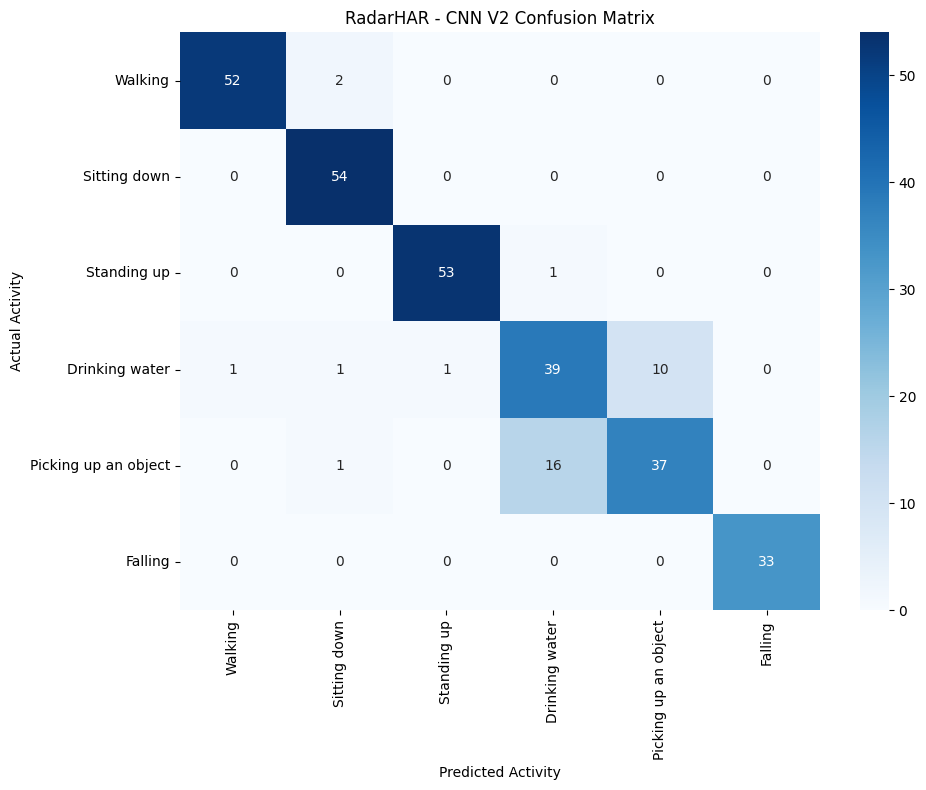

In [22]:
cm_v2 = confusion_matrix(
    y_val,
    v2_predictions,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("RadarHAR - CNN V2 Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()

plt.savefig(
    SAVE_DIR / "cnn_v2_confusion_matrix.png",
    dpi=200
)

plt.show()

In [23]:
v2_results = {

    "Model": "CNN V2",

    "Accuracy": accuracy_score(
        y_val, v2_predictions
    ),

    "Precision": precision_score(
        y_val, v2_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_val, v2_predictions,
        average="macro",
        zero_division=0
    ),

    "F1 Score": f1_score(
        y_val, v2_predictions,
        average="macro"
    ),

    "Training Time (s)": cnn_v2_training_time
}

comparison_v2 = pd.read_csv(
    V1_DIR / "model_comparison.csv"
)

comparison_v2 = pd.concat([
    comparison_v2,
    pd.DataFrame([v2_results])
], ignore_index=True)

display(comparison_v2.round(4))

comparison_v2.to_csv(
    SAVE_DIR / "model_comparison_v2.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s)
0,Random Forest,0.9037,0.9067,0.9066,0.9056,12.7108
1,SVM,0.8405,0.8512,0.8357,0.8404,1.4757
2,CNN,0.1096,0.0183,0.1667,0.0329,65.2678
3,CNN V2,0.8904,0.8962,0.8966,0.8954,96.4186


DAY-9

In [25]:
from pathlib import Path

pdf_files = list(
    Path("/content/RadarHAR_dataset").rglob("*.pdf")
)

for path in pdf_files:
    print(path)

In [26]:
!pip -q install pymupdf

In [27]:
import fitz

for path in pdf_files:

    print("\nDOCUMENT:", path.name)
    print("=" * 70)

    with fitz.open(path) as doc:

        for i, page in enumerate(doc):

            print(f"\nPAGE {i+1}")
            print(page.get_text())

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [28]:
error_df = pd.DataFrame({

    "Actual": y_val,

    "Predicted": v2_predictions

})

error_df["Actual Activity"] = error_df["Actual"].map(
    dict(enumerate(class_names))
)

error_df["Predicted Activity"] = error_df["Predicted"].map(
    dict(enumerate(class_names))
)

errors = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

display(
    errors.groupby([
        "Actual Activity",
        "Predicted Activity"
    ]).size().sort_values(ascending=False)
)

print("Total errors:", len(errors))

Actual Activity       Predicted Activity  
Picking up an object  Drinking water          16
Drinking water        Picking up an object    10
Walking               Sitting down             2
Drinking water        Sitting down             1
                      Walking                  1
                      Standing up              1
Picking up an object  Sitting down             1
Standing up           Drinking water           1
dtype: int64

Total errors: 33


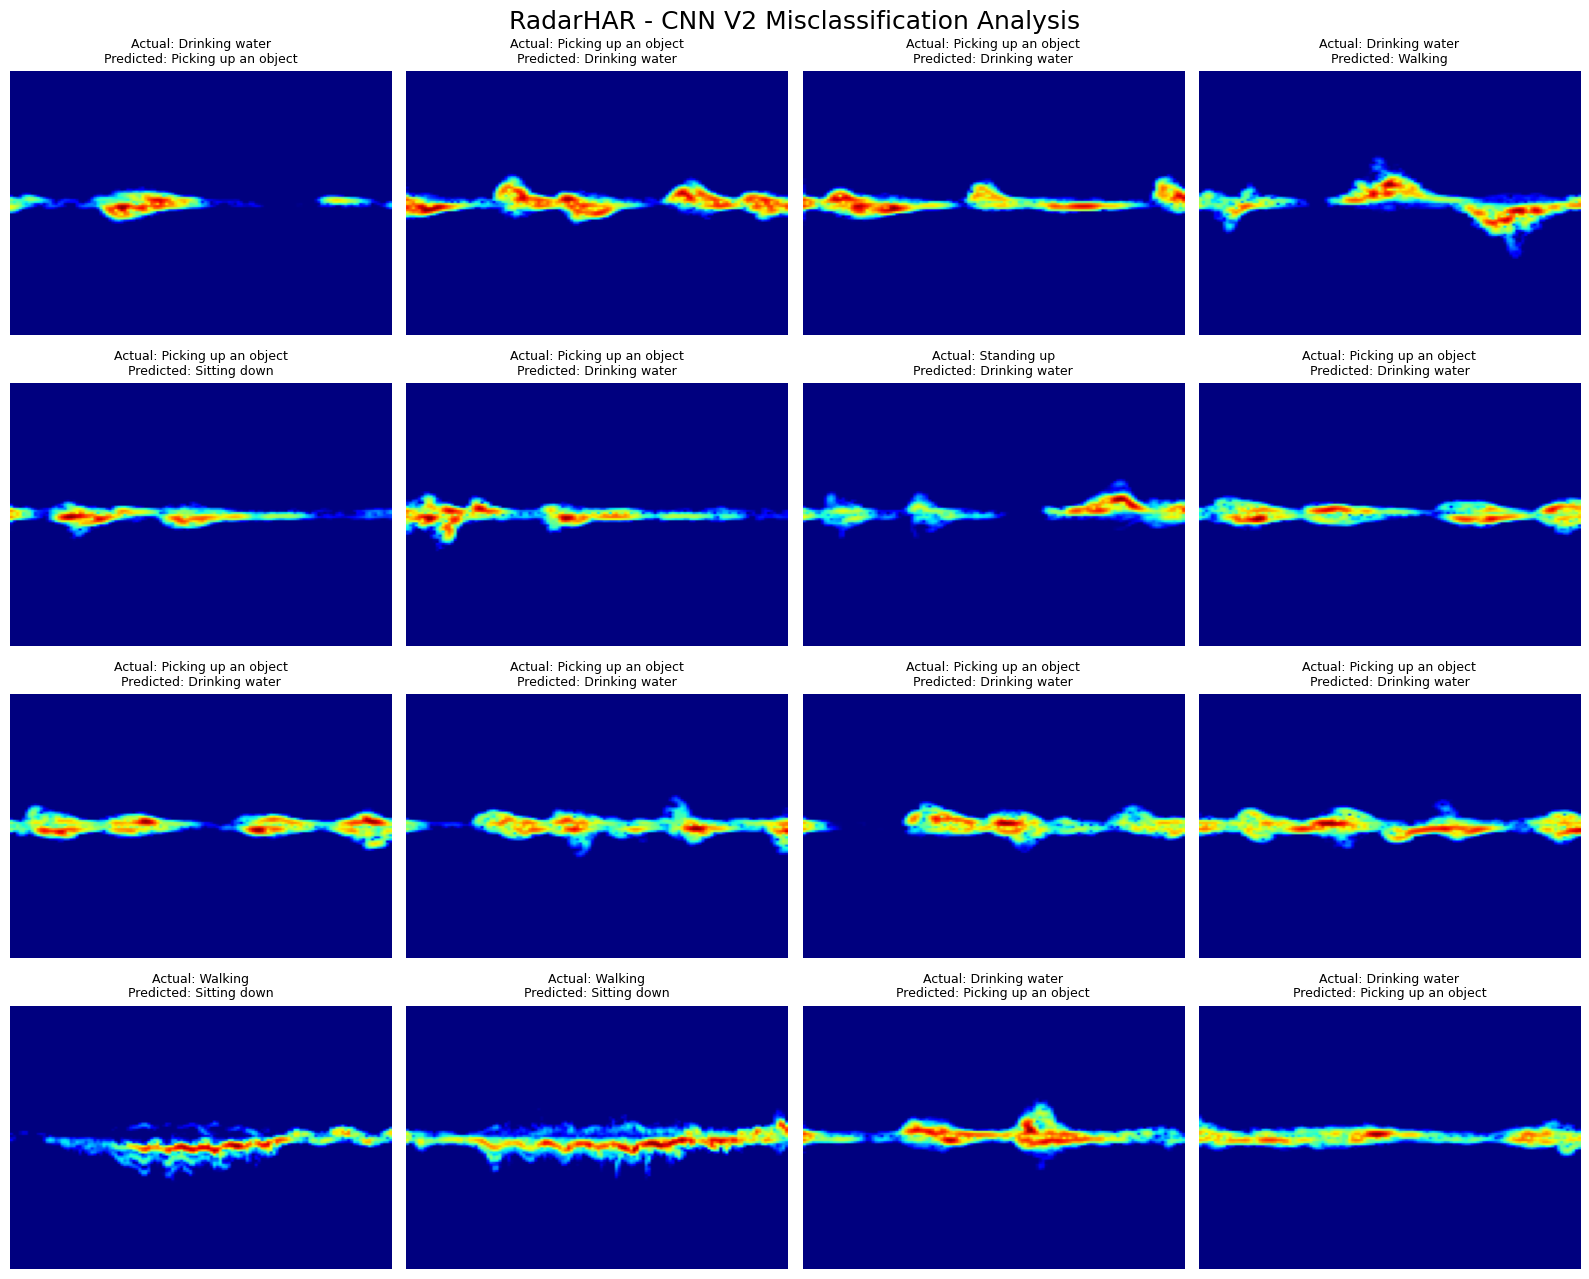

In [29]:
wrong_indices = np.where(
    y_val != v2_predictions
)[0]

fig, axes = plt.subplots(
    4, 4,
    figsize=(16, 13)
)

for ax, idx in zip(
    axes.flat,
    wrong_indices[:16]
):

    ax.imshow(
        X_val[idx].squeeze(),
        origin="lower",
        aspect="auto",
        cmap="jet",
        vmin=0,
        vmax=1
    )

    actual = class_names[y_val[idx]]

    predicted = class_names[v2_predictions[idx]]

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=9
    )

    ax.axis("off")

for ax in axes.flat[len(wrong_indices[:16]):]:
    ax.axis("off")

plt.suptitle(
    "RadarHAR - CNN V2 Misclassification Analysis",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "cnn_v2_error_analysis.png",
    dpi=200
)

plt.show()

In [30]:
cnn_probabilities = best_cnn_v2.predict(
    X_val,
    verbose=0
)

confidence = cnn_probabilities.max(axis=1)

correct_mask = (
    v2_predictions == y_val
)

print(
    "Average confidence (correct):",
    confidence[correct_mask].mean()
)

print(
    "Average confidence (incorrect):",
    confidence[~correct_mask].mean()
)

print(
    "Incorrect predictions above 90% confidence:",
    np.sum(
        (~correct_mask) &
        (confidence >= 0.90)
    )
)

Average confidence (correct): 0.9093267
Average confidence (incorrect): 0.6843248
Incorrect predictions above 90% confidence: 1


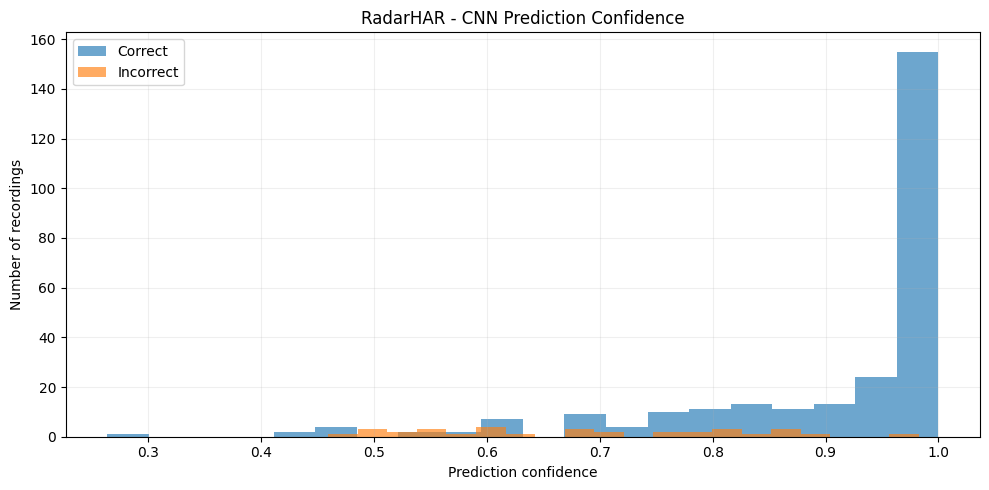

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(
    confidence[correct_mask],
    bins=20,
    alpha=0.65,
    label="Correct"
)

plt.hist(
    confidence[~correct_mask],
    bins=20,
    alpha=0.65,
    label="Incorrect"
)

plt.xlabel("Prediction confidence")
plt.ylabel("Number of recordings")

plt.title(
    "RadarHAR - CNN Prediction Confidence"
)

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "cnn_confidence_analysis.png",
    dpi=200
)

plt.show()

In [32]:
from pathlib import Path

dataset_root = Path("/content/RadarHAR_dataset")

doc_extensions = {
    ".pdf", ".txt", ".md", ".docx",
    ".xlsx", ".csv", ".html", ".rtf"
}

documentation_files = [
    p for p in dataset_root.rglob("*")
    if p.is_file() and (
        p.suffix.lower() in doc_extensions
        or "readme" in p.name.lower()
    )
]

print("Dataset exists:", dataset_root.exists())
print("Documentation files:", len(documentation_files))

for path in documentation_files:
    print(path)

Dataset exists: False
Documentation files: 0


In [34]:
for path in documentation_files:

    if path.suffix.lower() in {".txt", ".md"}:

        print("\nDOCUMENT:", path.name)
        print("=" * 70)

        print(
            path.read_text(
                encoding="utf-8",
                errors="replace"
            )[:20000]
        )

In [35]:
%whos

Variable                Type               Data/Info
----------------------------------------------------
MODEL_DIR               PosixPath          /content/drive/MyDrive/RadarHAR/models
MacroF1Callback         type               <class '__main__.MacroF1Callback'>
MacroF1V2               type               <class '__main__.MacroF1V2'>
Path                    type               <class 'pathlib._local.Path'>
SAVE_DIR                PosixPath          /content/drive/MyDrive/RadarHAR
V1_DIR                  PosixPath          /content/drive/MyDrive/Ra<...>darHAR/experiments/cnn_v1
X                       ndarray            1754x128x128: 28737536 elems, type `float32`, 114950144 bytes (109.625 Mb)
X_cnn                   ndarray            1754x128x128x1: 28737536 elems, type `float32`, 114950144 bytes (109.625 Mb)
X_debug                 ndarray            64x128x128x1: 1048576 elems, type `float32`, 4194304 bytes (4.0 Mb)
X_small                 ndarray            60x128x128x1: 983040 el

In [38]:
from sklearn.ensemble import RandomForestClassifier

for name, obj in list(globals().items()):
    if isinstance(obj, RandomForestClassifier):
        print("Random Forest variable:", name)

In [39]:
from pathlib import Path

model_dir = Path("/content/drive/MyDrive/RadarHAR/models")

for path in model_dir.glob("*"):
    print(path.name)

random_forest.joblib
svm_model.joblib
best_cnn.keras
best_cnn_v2.keras


In [40]:
%whos

Variable                 Type               Data/Info
-----------------------------------------------------
MODEL_DIR                PosixPath          /content/drive/MyDrive/RadarHAR/models
MacroF1Callback          type               <class '__main__.MacroF1Callback'>
MacroF1V2                type               <class '__main__.MacroF1V2'>
Path                     type               <class 'pathlib._local.Path'>
RandomForestClassifier   ABCMeta            <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SAVE_DIR                 PosixPath          /content/drive/MyDrive/RadarHAR
V1_DIR                   PosixPath          /content/drive/MyDrive/Ra<...>darHAR/experiments/cnn_v1
X                        ndarray            1754x128x128: 28737536 elems, type `float32`, 114950144 bytes (109.625 Mb)
X_cnn                    ndarray            1754x128x128x1: 28737536 elems, type `float32`, 114950144 bytes (109.625 Mb)
X_debug                  ndarray            64x128x128x1: 1048576 e

In [41]:
import joblib

rf_model = joblib.load(
    MODEL_DIR / "random_forest.joblib"
)

svm_model = joblib.load(
    MODEL_DIR / "svm_model.joblib"
)

print("Random Forest loaded successfully!")
print("SVM loaded successfully!")

print("RF model type:", type(rf_model))
print("Expected features:", rf_model.n_features_in_)
print("Model classes:", rf_model.classes_)

Random Forest loaded successfully!
SVM loaded successfully!
RF model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Expected features: 2029
Model classes: [0 1 2 3 4 5]


In [42]:
for path in SAVE_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".npy", ".npz", ".csv", ".joblib",
        ".pkl", ".parquet"
    }:
        print(
            path.relative_to(SAVE_DIR),
            "|",
            round(path.stat().st_size / 1024**2, 2),
            "MB"
        )

metadata.csv | 0.27 MB
RadarHAR_dataset_v1.npz | 9.56 MB
dataset_splits.npz | 0.01 MB
extracted_features.npy | 13.58 MB
baseline_results.csv | 0.0 MB
cnn_training_history.csv | 0.0 MB
model_comparison.csv | 0.0 MB
cnn_v2_training_history.csv | 0.0 MB
model_comparison_v2.csv | 0.0 MB
models/random_forest.joblib | 9.44 MB
models/svm_model.joblib | 14.35 MB
batches_v1/errors_0000.csv | 0.0 MB
batches_v1/batch_0000_0100.npz | 0.79 MB
batches_v1/errors_0100.csv | 0.0 MB
batches_v1/batch_0100_0200.npz | 0.43 MB
batches_v1/errors_0200.csv | 0.0 MB
batches_v1/batch_0200_0300.npz | 0.48 MB
batches_v1/errors_0300.csv | 0.0 MB
batches_v1/batch_0300_0400.npz | 0.49 MB
batches_v1/errors_0400.csv | 0.0 MB
batches_v1/batch_0400_0500.npz | 0.6 MB
batches_v1/errors_0500.csv | 0.0 MB
batches_v1/batch_0500_0600.npz | 0.82 MB
batches_v1/errors_0600.csv | 0.0 MB
batches_v1/batch_0600_0700.npz | 0.54 MB
batches_v1/errors_0700.csv | 0.0 MB
batches_v1/batch_0700_0800.npz | 0.44 MB
batches_v1/errors_0800.csv |

In [43]:
print("Original dataset:", X.shape)

print("Training indices:", train_idx.shape)
print("Validation indices:", val_idx.shape)
print("Testing indices:", test_idx.shape)

print(
    "Validation labels aligned:",
    np.array_equal(y[val_idx], y_val)
)

print(
    "Validation spectrograms aligned:",
    np.array_equal(X[val_idx], X_val.squeeze(-1))
)

Original dataset: (1754, 128, 128)
Training indices: (1194,)
Validation indices: (301,)
Testing indices: (259,)
Validation labels aligned: True
Validation spectrograms aligned: True


In [44]:
X_features = np.load(
    SAVE_DIR / "extracted_features.npy"
)

print("Full feature dataset:", X_features.shape)
print("Datatype:", X_features.dtype)
print("All finite:", np.isfinite(X_features).all())

assert X_features.shape == (1754, 2029)
assert np.isfinite(X_features).all()

X_train_features = X_features[train_idx]
X_val_features = X_features[val_idx]

print("Training features:", X_train_features.shape)
print("Validation features:", X_val_features.shape)

Full feature dataset: (1754, 2029)
Datatype: float32
All finite: True
Training features: (1194, 2029)
Validation features: (301, 2029)


In [45]:
recovered_rf_predictions = rf_model.predict(
    X_val_features
)

recovered_accuracy = accuracy_score(
    y_val, recovered_rf_predictions
)

recovered_f1 = f1_score(
    y_val,
    recovered_rf_predictions,
    average="macro"
)

print("Random Forest validation accuracy:",
      recovered_accuracy)

print("Random Forest validation macro F1:",
      recovered_f1)

assert np.isclose(
    recovered_accuracy,
    0.9036544850498339
)

assert np.isclose(
    recovered_f1,
    0.9055643981654381
)

print("Original validation performance reproduced!")

Random Forest validation accuracy: 0.9036544850498339
Random Forest validation macro F1: 0.9055643981654381
Original validation performance reproduced!


In [46]:
rf_probabilities = rf_model.predict_proba(
    X_val_features
)

cnn_probabilities = best_cnn_v2.predict(
    X_val,
    verbose=0
)

assert np.array_equal(
    rf_model.classes_, np.arange(6)
)

assert rf_probabilities.shape == (301, 6)
assert cnn_probabilities.shape == (301, 6)

rf_predictions = rf_probabilities.argmax(axis=1)
cnn_predictions = cnn_probabilities.argmax(axis=1)

rf_correct = rf_predictions == y_val
cnn_correct = cnn_predictions == y_val

print("Both models correct:",
      np.sum(rf_correct & cnn_correct))

print("Only Random Forest correct:",
      np.sum(rf_correct & ~cnn_correct))

print("Only CNN correct:",
      np.sum(~rf_correct & cnn_correct))

print("Both models incorrect:",
      np.sum(~rf_correct & ~cnn_correct))

print("Prediction agreement:",
      np.mean(rf_predictions == cnn_predictions))

print("Oracle accuracy:",
      np.mean(rf_correct | cnn_correct))

Both models correct: 260
Only Random Forest correct: 12
Only CNN correct: 8
Both models incorrect: 21
Prediction agreement: 0.9335548172757475
Oracle accuracy: 0.9302325581395349


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

ensemble_results = []

for alpha in np.linspace(0, 1, 21):

    probabilities = (
        alpha * rf_probabilities
        + (1 - alpha) * cnn_probabilities
    )

    predictions = probabilities.argmax(axis=1)

    ensemble_results.append({

        "RF Weight": round(alpha, 2),

        "CNN Weight": round(1-alpha, 2),

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "Precision": precision_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_val, predictions,
            average="macro"
        )

    })

ensemble_df = pd.DataFrame(ensemble_results)

display(
    ensemble_df.sort_values(
        "Macro F1",
        ascending=False
    ).reset_index(drop=True)
)

,RF Weight,CNN Weight,Accuracy,Precision,Recall,Macro F1
0,0.70,0.30,0.910299,0.913726,0.915123,0.914220
1,0.75,0.25,0.910299,0.913726,0.915123,0.914220
2,0.65,0.35,0.910299,0.913726,0.915123,0.914220
3,0.80,0.20,0.910299,0.913380,0.915123,0.913947
4,0.90,0.10,0.910299,0.912826,0.914886,0.913188
5,0.60,0.40,0.906977,0.910583,0.912037,0.911060
6,0.85,0.15,0.906977,0.909874,0.911918,0.910468
7,0.50,0.50,0.903654,0.908169,0.908951,0.908312
8,0.55,0.45,0.903654,0.908169,0.908951,0.908312
9,0.45,0.55,0.903654,0.908169,0.908951,0.908312


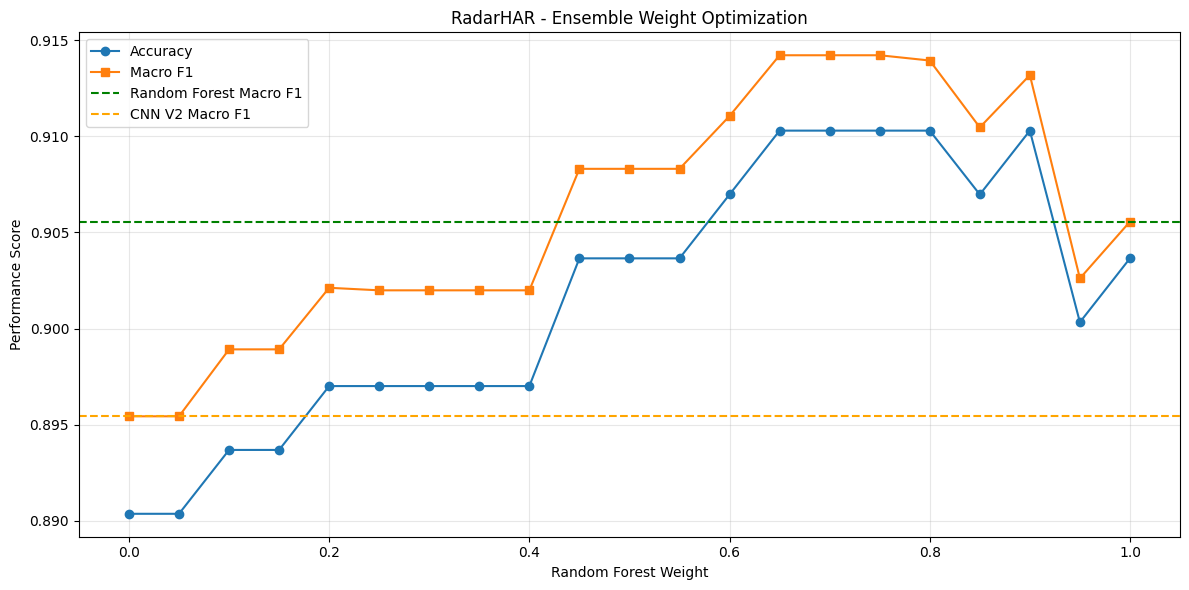

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    ensemble_df["RF Weight"],
    ensemble_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    ensemble_df["RF Weight"],
    ensemble_df["Macro F1"],
    marker="s",
    label="Macro F1"
)

plt.axhline(
    0.9055643981654381,
    linestyle="--",
    color="green",
    label="Random Forest Macro F1"
)

plt.axhline(
    0.8954375503564301,
    linestyle="--",
    color="orange",
    label="CNN V2 Macro F1"
)

plt.xlabel("Random Forest Weight")
plt.ylabel("Performance Score")
plt.title("RadarHAR - Ensemble Weight Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    SAVE_DIR / "ensemble_optimization.png",
    dpi=200
)

plt.show()

Best Random Forest weight: 0.65
Best CNN weight: 0.35
Validation accuracy: 0.9102990033222591
Validation macro F1: 0.9142198876187134
                      precision    recall  f1-score   support

             Walking       1.00      0.98      0.99        54
        Sitting down       0.95      1.00      0.97        54
         Standing up       0.98      1.00      0.99        54
      Drinking water       0.76      0.75      0.76        52
Picking up an object       0.79      0.76      0.77        54
             Falling       1.00      1.00      1.00        33

            accuracy                           0.91       301
           macro avg       0.91      0.92      0.91       301
        weighted avg       0.91      0.91      0.91       301



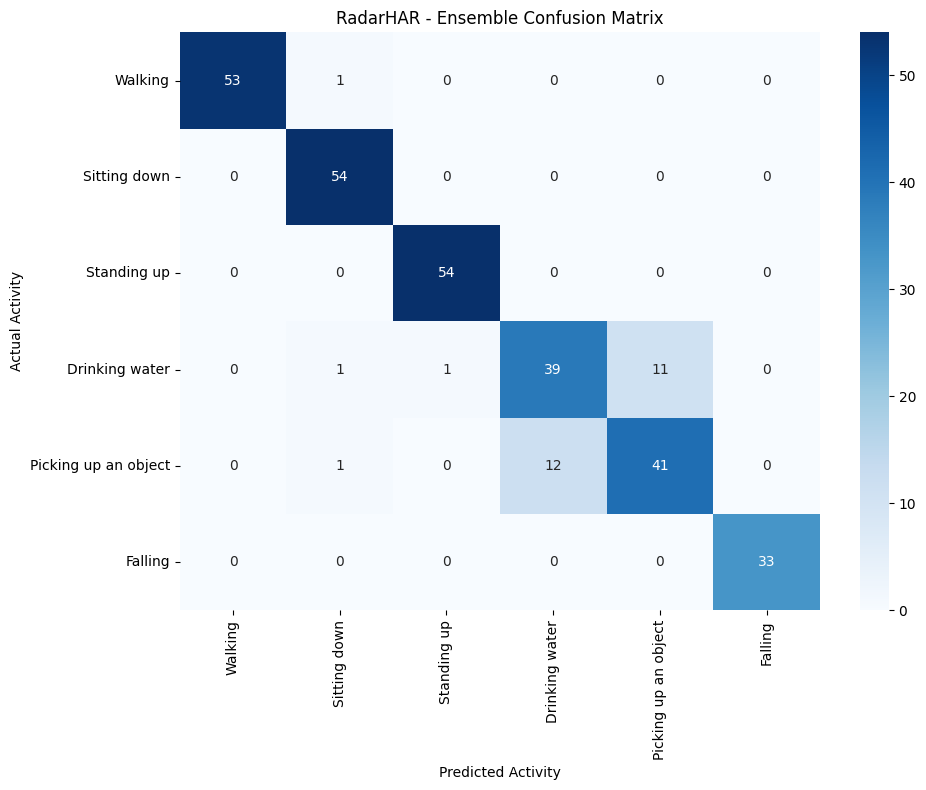

In [49]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

import seaborn as sns

best_result = ensemble_df.loc[
    ensemble_df["Macro F1"].idxmax()
]

best_alpha = float(best_result["RF Weight"])

ensemble_probabilities = (
    best_alpha * rf_probabilities
    + (1-best_alpha) * cnn_probabilities
)

ensemble_predictions = (
    ensemble_probabilities.argmax(axis=1)
)

print("Best Random Forest weight:", best_alpha)
print("Best CNN weight:", 1-best_alpha)

print(
    "Validation accuracy:",
    accuracy_score(y_val, ensemble_predictions)
)

print(
    "Validation macro F1:",
    f1_score(
        y_val,
        ensemble_predictions,
        average="macro"
    )
)

print(
    classification_report(
        y_val,
        ensemble_predictions,
        labels=np.arange(6),
        target_names=class_names,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val,
    ensemble_predictions,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("RadarHAR - Ensemble Confusion Matrix")

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "ensemble_confusion_matrix.png",
    dpi=200
)

plt.show()

DAY-10

In [50]:
import json
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/RadarHAR")
MODEL_DIR = SAVE_DIR / "models"

ensemble_config = {
    "model_name": "RadarHAR_Hybrid_Ensemble",
    "random_forest_weight": 0.65,
    "cnn_weight": 0.35,
    "random_forest_model": "random_forest.joblib",
    "cnn_model": "best_cnn_v2.keras",
    "input_shape": [128, 128, 1],
    "handcrafted_features": 2029,
    "class_names": list(class_names),
    "validation_accuracy": 0.9102990033222591,
    "validation_macro_f1": 0.9142198876187134
}

with open(MODEL_DIR / "ensemble_config.json", "w") as f:
    json.dump(ensemble_config, f, indent=4)

print("Ensemble configuration saved!")
print(json.dumps(ensemble_config, indent=4))

Ensemble configuration saved!
{
    "model_name": "RadarHAR_Hybrid_Ensemble",
    "random_forest_weight": 0.65,
    "cnn_weight": 0.35,
    "random_forest_model": "random_forest.joblib",
    "cnn_model": "best_cnn_v2.keras",
    "input_shape": [
        128,
        128,
        1
    ],
    "handcrafted_features": 2029,
    "class_names": [
        "Walking",
        "Sitting down",
        "Standing up",
        "Drinking water",
        "Picking up an object",
        "Falling"
    ],
    "validation_accuracy": 0.9102990033222591,
    "validation_macro_f1": 0.9142198876187134
}


In [51]:
import numpy as np
import pandas as pd

X_features = np.load(
    SAVE_DIR / "extracted_features.npy"
)

assert len(X) == len(y) == len(groups)
assert len(X_features) == len(y)

all_indices = np.concatenate([
    train_idx, val_idx, test_idx
])

assert len(all_indices) == 1754
assert len(np.unique(all_indices)) == 1754
assert np.array_equal(
    np.sort(all_indices), np.arange(len(y))
)

train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert not train_groups.intersection(val_groups)
assert not train_groups.intersection(test_groups)
assert not val_groups.intersection(test_groups)

assert np.array_equal(y[train_idx], y_train)
assert np.array_equal(y[val_idx], y_val)
assert np.array_equal(y[test_idx], y_test)

assert np.array_equal(X[test_idx], X_test[..., 0])

print("All dataset integrity checks passed!")
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Testing groups:", len(test_groups))

print("Test features:", X_features[test_idx].shape)
print("Test spectrograms:", X_test.shape)
print("Test labels:", y_test.shape)

All dataset integrity checks passed!
Training groups: 50
Validation groups: 11
Testing groups: 11
Test features: (259, 2029)
Test spectrograms: (259, 128, 128, 1)
Test labels: (259,)


In [52]:
from pathlib import Path

search_roots = [
    Path("/content"),
    SAVE_DIR
]

found_pdfs = set()

for root in search_roots:
    for path in root.rglob("*.pdf"):
        name = path.name.lower()

        if any(term in name for term in [
            "848", "dataset", "readme"
        ]):
            found_pdfs.add(str(path))

print("Relevant documentation files:")

for path in sorted(found_pdfs):
    print(path)

print("Total documents found:", len(found_pdfs))

Relevant documentation files:
/content/drive/MyDrive/RadarHAR/data/raw/Readme_848.pdf
Total documents found: 1


In [53]:
import pymupdf

readme_path = SAVE_DIR / "data/raw/Readme_848.pdf"

with pymupdf.open(readme_path) as doc:
    print("Total pages:", len(doc))

    for page_number, page in enumerate(doc, start=1):
        print("\n" + "=" * 70)
        print("PAGE:", page_number)
        print("=" * 70)
        print(page.get_text())

Total pages: 8

PAGE: 1
1 
 
Data Sheet for Project: Intelligent RF Sensing for Falls and Health Prediction – INSHEP (EP/R041679/1) 
James Watt School of Engineering, University of Glasgow  
Dr Syed Aziz Shah, Dr Julien Le Kernec, Dr Francesco Fioranelli (PI) 
 {syed.a.shah, julien.lekernec, francesco.fioranelli}@glasgow.ac.uk 
This document is for the data obtained in March 2017 (University of Glasgow), December 2017 (University of 
Glasgow), June 2017 (University of Glasgow), July 2018 (University of Glasgow), February 2019 (North Glasgow 
Housing Association facilities), and March 2019 (Age UK West Cumbria centre).  
What did people do?  
They were asked to perform two or three repetitions of five different activities, which were walking back and 
forth, sitting down on a chair, standing up, bending to pick up an object, and drinking from a cup or glass. We 
asked people to perform each activity separately one from another in “snapshots.  
In some cases, an additional activity, a si

In [54]:
metadata = pd.read_csv(SAVE_DIR / "metadata.csv")

participant_audit = (
    metadata.groupby("person_id")
    .agg(
        recordings=("filename", "count"),
        collections=("collection", "nunique")
    )
    .reset_index()
)

repeated_participants = participant_audit[
    participant_audit["collections"] > 1
]

print("Total unique participant IDs:",
      metadata["person_id"].nunique())

print("IDs appearing in multiple collections:",
      len(repeated_participants))

display(repeated_participants)

Total unique participant IDs: 72
IDs appearing in multiple collections: 34


,person_id,recordings,collections
2,3,31,2
7,8,36,2
9,10,29,2
10,11,30,2
11,12,30,2
13,14,36,2
27,28,33,2
28,29,33,2
29,30,34,2
30,31,33,2


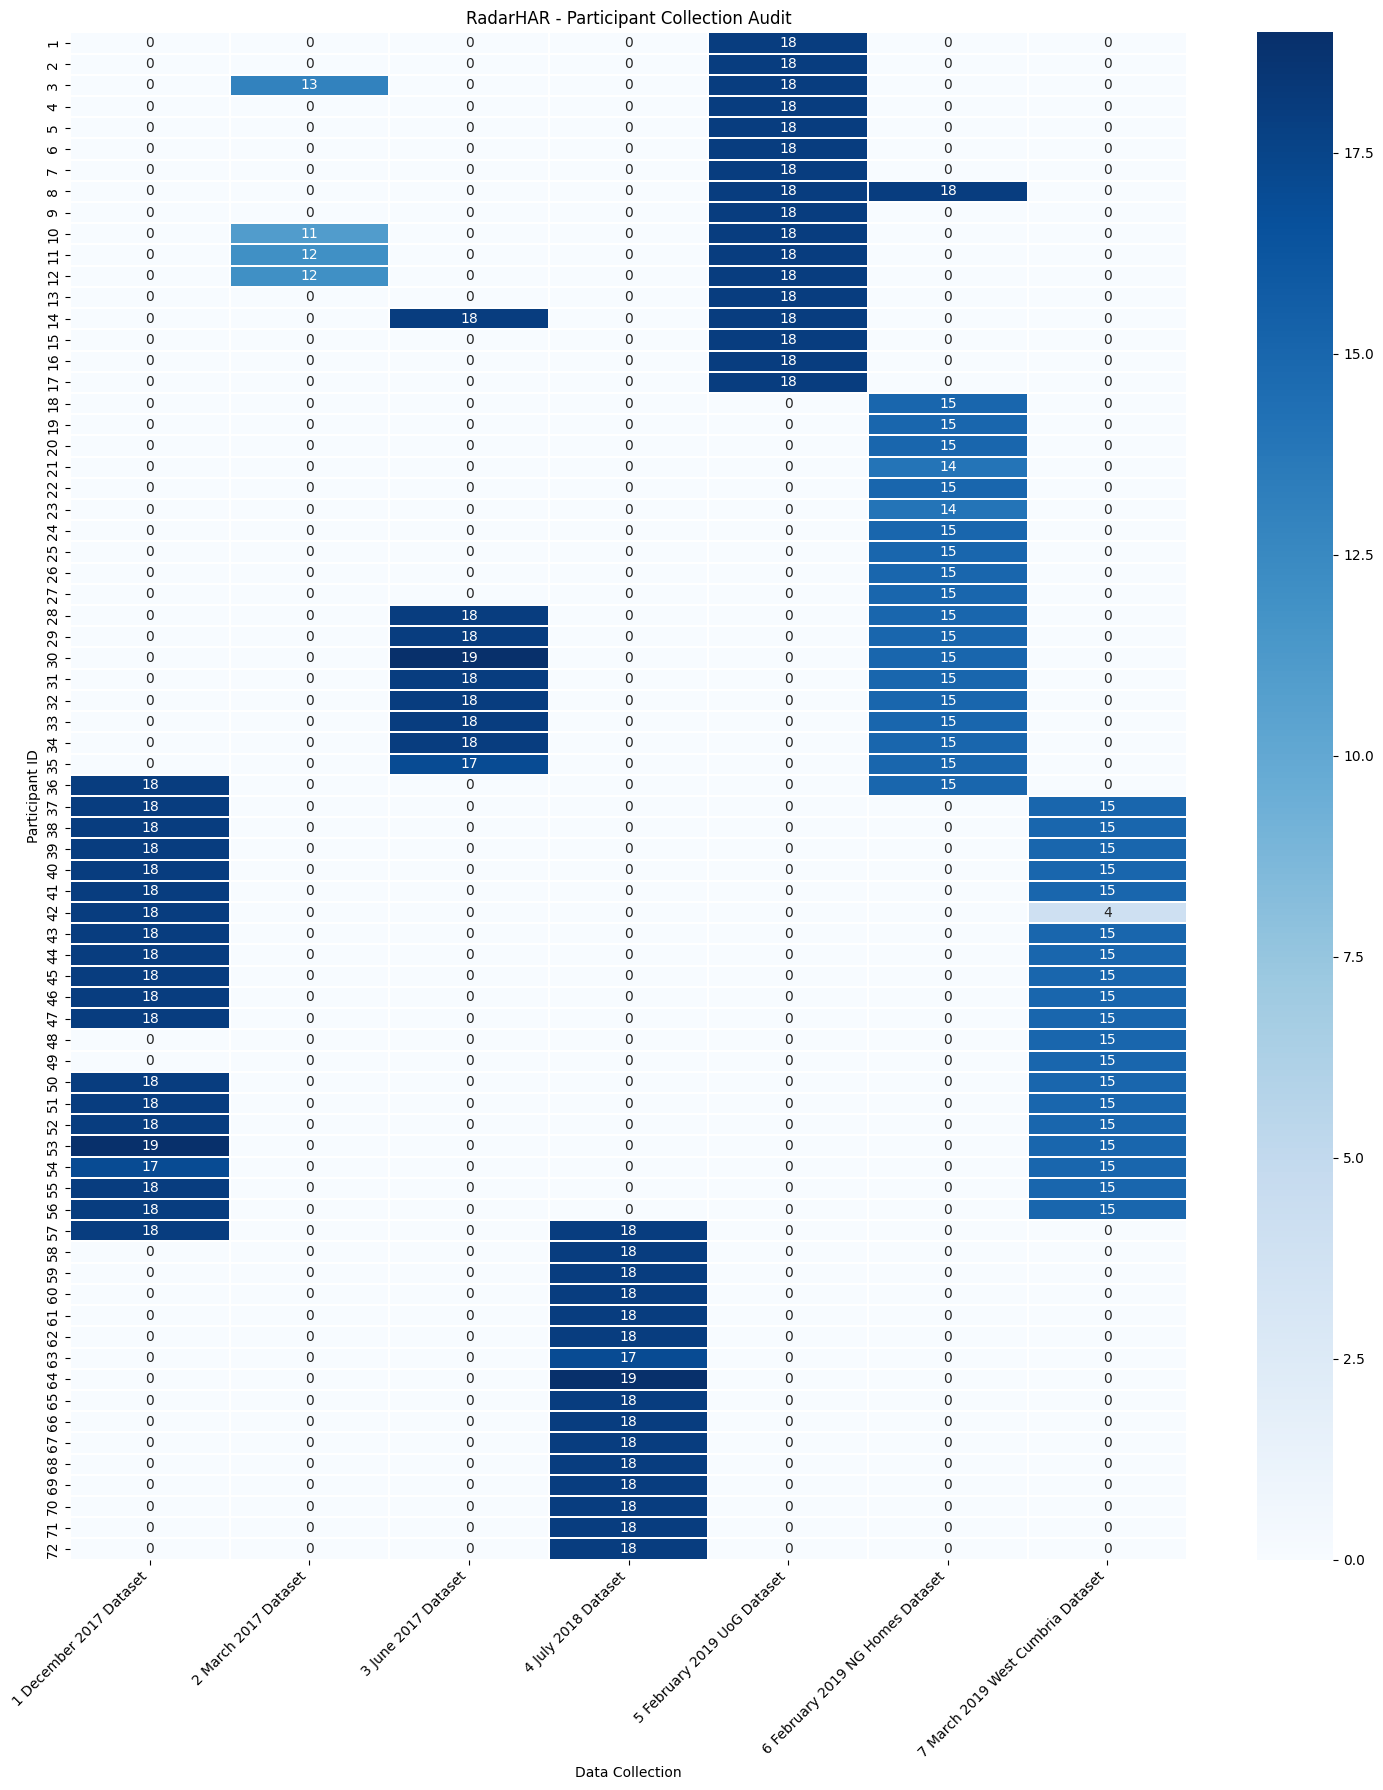

In [56]:
collection_overlap = pd.crosstab(
    metadata["person_id"],
    metadata["collection"]
)

plt.figure(figsize=(15, 18))

sns.heatmap(
    collection_overlap,
    cmap="Blues",
    annot=True,
    fmt="d",
    linewidths=0.3
)

plt.title("RadarHAR - Participant Collection Audit")
plt.xlabel("Data Collection")
plt.ylabel("Participant ID")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [57]:
import joblib
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

rf_model = joblib.load(
    MODEL_DIR / "random_forest.joblib"
)

svm_model = joblib.load(
    MODEL_DIR / "svm_model.joblib"
)

best_cnn_v2 = tf.keras.models.load_model(
    MODEL_DIR / "best_cnn_v2.keras",
    compile=False
)

features = np.load(
    SAVE_DIR / "extracted_features.npy"
)

X_test_features = features[test_idx]

print("All models loaded successfully!")
print("Test features:", X_test_features.shape)
print("Test spectrograms:", X_test.shape)
print("Test labels:", y_test.shape)

assert len(X_test_features) == len(X_test) == len(y_test)
assert np.array_equal(y[test_idx], y_test)
assert np.array_equal(
    rf_model.classes_, np.arange(6)
)

print("Alignment checks passed!")

All models loaded successfully!
Test features: (259, 2029)
Test spectrograms: (259, 128, 128, 1)
Test labels: (259,)
Alignment checks passed!


In [58]:
import time

# Random Forest
start = time.perf_counter()

rf_test_probabilities = rf_model.predict_proba(
    X_test_features
)

rf_test_predictions = np.argmax(
    rf_test_probabilities, axis=1
)

rf_inference_time = time.perf_counter() - start


# SVM
start = time.perf_counter()

svm_test_predictions = svm_model.predict(
    X_test_features
)

svm_inference_time = time.perf_counter() - start


# CNN V2
start = time.perf_counter()

cnn_test_probabilities = best_cnn_v2.predict(
    X_test, verbose=0
)

cnn_test_predictions = np.argmax(
    cnn_test_probabilities, axis=1
)

cnn_inference_time = time.perf_counter() - start


# Hybrid Ensemble
start = time.perf_counter()

ensemble_test_probabilities = (
    0.65 * rf_test_probabilities
    + 0.35 * cnn_test_probabilities
)

ensemble_test_predictions = np.argmax(
    ensemble_test_probabilities, axis=1
)

ensemble_fusion_time = time.perf_counter() - start

ensemble_inference_time = (
    rf_inference_time
    + cnn_inference_time
    + ensemble_fusion_time
)

print("All test predictions generated successfully!")

print("Random Forest:", rf_test_predictions.shape)
print("SVM:", svm_test_predictions.shape)
print("CNN V2:", cnn_test_predictions.shape)
print("Ensemble:", ensemble_test_predictions.shape)

All test predictions generated successfully!
Random Forest: (259,)
SVM: (259,)
CNN V2: (259,)
Ensemble: (259,)


In [59]:
def evaluate_test_model(name, predictions, inference_time):

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Inference Time (s)": inference_time,
        "Time per Recording (ms)": (
            inference_time / len(y_test)
        ) * 1000
    }


test_results = pd.DataFrame([

    evaluate_test_model(
        "Random Forest",
        rf_test_predictions,
        rf_inference_time
    ),

    evaluate_test_model(
        "SVM",
        svm_test_predictions,
        svm_inference_time
    ),

    evaluate_test_model(
        "CNN V2",
        cnn_test_predictions,
        cnn_inference_time
    ),

    evaluate_test_model(
        "Hybrid Ensemble",
        ensemble_test_predictions,
        ensemble_inference_time
    )
])

display(test_results.round(4))

,Model,Accuracy,Precision,Recall,Macro F1,Inference Time (s),Time per Recording (ms)
0,Random Forest,0.8571,0.8691,0.8644,0.8658,0.1497,0.5781
1,SVM,0.8378,0.8541,0.8420,0.8447,0.9406,3.6317
2,CNN V2,0.8687,0.8835,0.8734,0.8761,10.3463,39.9473
3,Hybrid Ensemble,0.8842,0.8967,0.8896,0.8916,10.4964,40.5267


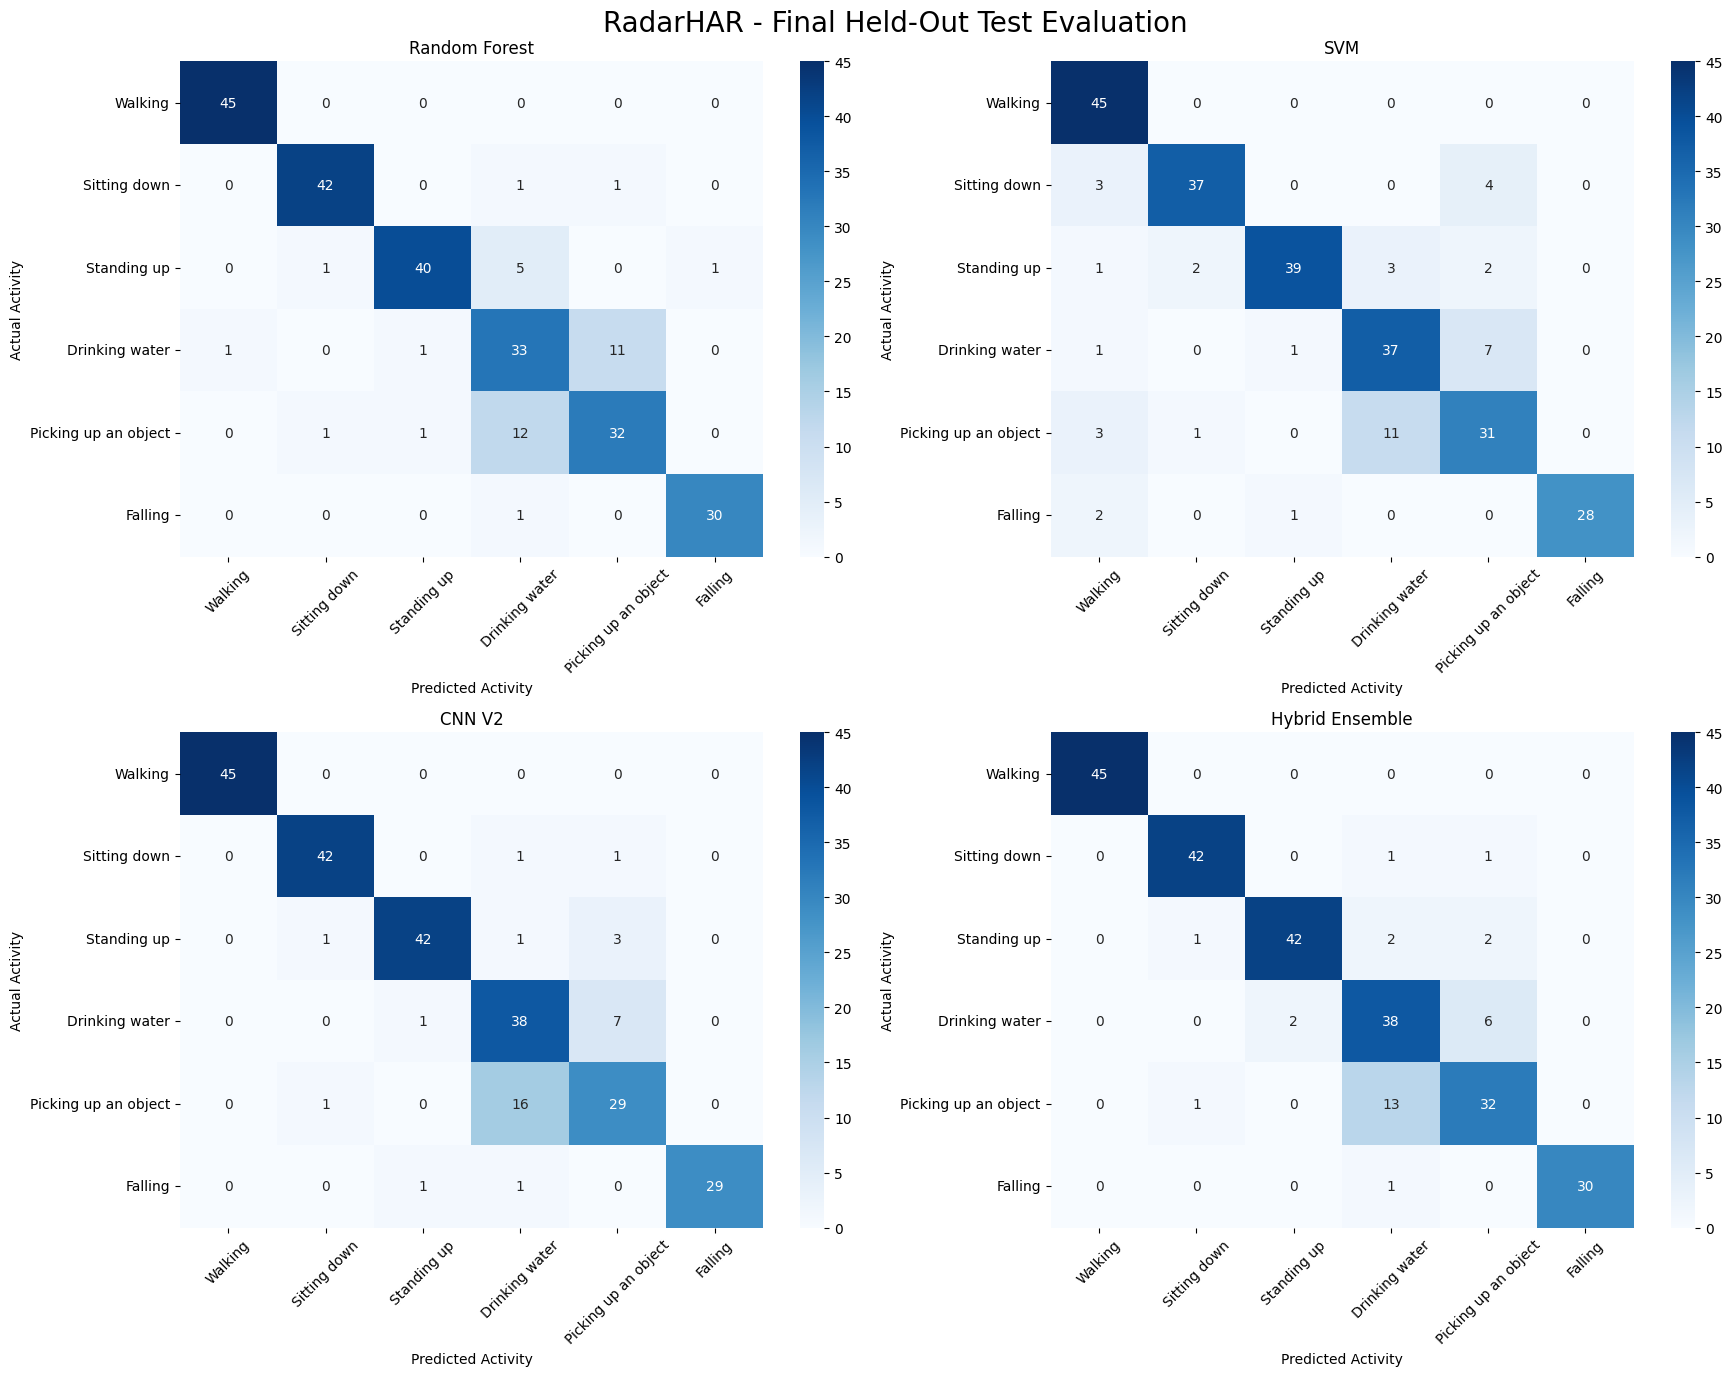

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

model_predictions = {
    "Random Forest": rf_test_predictions,
    "SVM": svm_test_predictions,
    "CNN V2": cnn_test_predictions,
    "Hybrid Ensemble": ensemble_test_predictions
}

fig, axes = plt.subplots(
    2, 2, figsize=(18, 14)
)

for ax, (name, predictions) in zip(
    axes.ravel(),
    model_predictions.items()
):

    cm_test = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(6)
    )

    sns.heatmap(
        cm_test,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Activity")
    ax.set_ylabel("Actual Activity")

    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "RadarHAR - Final Held-Out Test Evaluation",
    fontsize=20
)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "final_test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
for name, predictions in model_predictions.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(classification_report(
        y_test,
        predictions,
        labels=np.arange(6),
        target_names=class_names,
        zero_division=0
    ))


Random Forest
                      precision    recall  f1-score   support

             Walking       0.98      1.00      0.99        45
        Sitting down       0.95      0.95      0.95        44
         Standing up       0.95      0.85      0.90        47
      Drinking water       0.63      0.72      0.67        46
Picking up an object       0.73      0.70      0.71        46
             Falling       0.97      0.97      0.97        31

            accuracy                           0.86       259
           macro avg       0.87      0.86      0.87       259
        weighted avg       0.86      0.86      0.86       259


SVM
                      precision    recall  f1-score   support

             Walking       0.82      1.00      0.90        45
        Sitting down       0.93      0.84      0.88        44
         Standing up       0.95      0.83      0.89        47
      Drinking water       0.73      0.80      0.76        46
Picking up an object       0.70      0.67     

In [62]:
test_results.to_csv(
    SAVE_DIR / "final_test_results.csv",
    index=False
)

np.savez_compressed(
    SAVE_DIR / "final_test_predictions.npz",
    y_true=y_test,
    rf_predictions=rf_test_predictions,
    svm_predictions=svm_test_predictions,
    cnn_predictions=cnn_test_predictions,
    ensemble_predictions=ensemble_test_predictions,
    ensemble_probabilities=ensemble_test_probabilities,
    rf_probabilities=rf_test_probabilities,
    cnn_probabilities=cnn_test_probabilities
)

print("Final test results saved successfully!")

Final test results saved successfully!


In [63]:
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

test_groups = groups[test_idx]
unique_test_groups = np.unique(test_groups)

print("Test groups:", len(unique_test_groups))
print("Test recordings:", len(test_groups))

rng = np.random.default_rng(42)

group_indices = {
    group: np.where(test_groups == group)[0]
    for group in unique_test_groups
}

bootstrap_samples = []

for _ in range(2000):

    sampled_groups = rng.choice(
        unique_test_groups,
        size=len(unique_test_groups),
        replace=True
    )

    indices = np.concatenate([
        group_indices[group]
        for group in sampled_groups
    ])

    bootstrap_samples.append(indices)

print("Bootstrap samples generated:",
      len(bootstrap_samples))

Test groups: 11
Test recordings: 259
Bootstrap samples generated: 2000


In [64]:
bootstrap_results = []
bootstrap_scores = {}

for name, predictions in model_predictions.items():

    accuracies = []
    f1_scores = []

    for indices in bootstrap_samples:

        accuracies.append(
            accuracy_score(
                y_test[indices],
                predictions[indices]
            )
        )

        f1_scores.append(
            f1_score(
                y_test[indices],
                predictions[indices],
                labels=np.arange(6),
                average="macro",
                zero_division=0
            )
        )

    bootstrap_scores[name] = {
        "accuracy": np.array(accuracies),
        "f1": np.array(f1_scores)
    }

    bootstrap_results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Accuracy CI Lower": np.percentile(
            accuracies, 2.5
        ),

        "Accuracy CI Upper": np.percentile(
            accuracies, 97.5
        ),

        "Macro F1": f1_score(
            y_test, predictions,
            average="macro"
        ),

        "F1 CI Lower": np.percentile(
            f1_scores, 2.5
        ),

        "F1 CI Upper": np.percentile(
            f1_scores, 97.5
        )
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(4))

,Model,Accuracy,Accuracy CI Lower,Accuracy CI Upper,Macro F1,F1 CI Lower,F1 CI Upper
0,Random Forest,0.8571,0.7942,0.9076,0.8658,0.8079,0.9120
1,SVM,0.8378,0.7786,0.8978,0.8447,0.7861,0.9010
2,CNN V2,0.8687,0.8103,0.9102,0.8761,0.8188,0.9158
3,Hybrid Ensemble,0.8842,0.8333,0.9226,0.8916,0.8437,0.9280


In [66]:
improvement_results = []

for name in ["Random Forest", "SVM", "CNN V2"]:

    differences = (
        bootstrap_scores["Hybrid Ensemble"]["f1"]
        - bootstrap_scores[name]["f1"]
    )

    improvement_results.append({
        "Comparison": f"Ensemble vs {name}",

        "Mean F1 Improvement": differences.mean(),

        "CI Lower": np.percentile(
            differences, 2.5
        ),

        "CI Upper": np.percentile(
            differences, 97.5
        ),

        "Positive Improvement (%)": (
            np.mean(differences > 0) * 100
        )
    })

improvement_df = pd.DataFrame(
    improvement_results
)

display(improvement_df.round(4))

,Comparison,Mean F1 Improvement,CI Lower,CI Upper,Positive Improvement (%)
0,Ensemble vs Random Forest,0.0243,-0.0120,0.0630,89.3
1,Ensemble vs SVM,0.0455,-0.0109,0.1009,93.6
2,Ensemble vs CNN V2,0.0164,-0.0000,0.0349,97.4


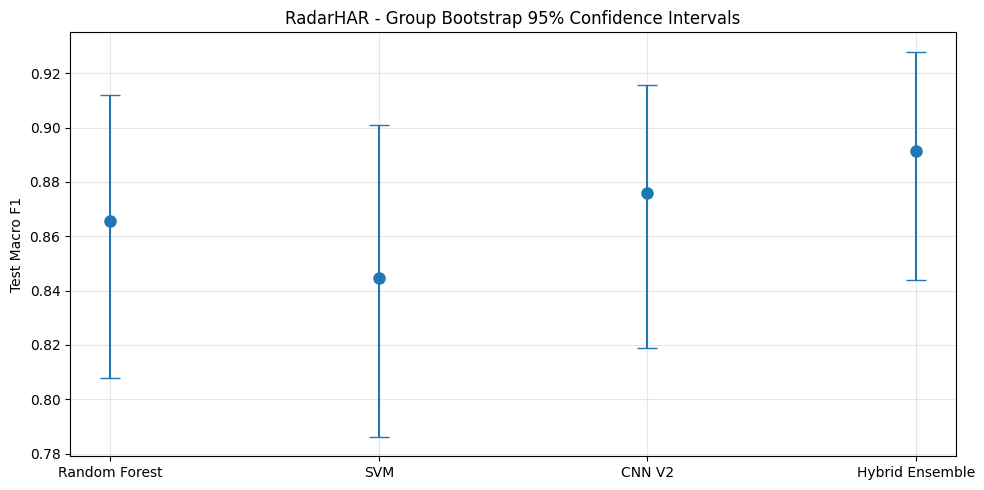

In [67]:
import matplotlib.pyplot as plt

scores = bootstrap_df["Macro F1"].to_numpy()

lower = scores - bootstrap_df[
    "F1 CI Lower"
].to_numpy()

upper = bootstrap_df[
    "F1 CI Upper"
].to_numpy() - scores

plt.figure(figsize=(10, 5))

plt.errorbar(
    bootstrap_df["Model"],
    scores,
    yerr=[lower, upper],
    fmt="o",
    capsize=7,
    markersize=8
)

plt.ylabel("Test Macro F1")
plt.title(
    "RadarHAR - Group Bootstrap 95% Confidence Intervals"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    SAVE_DIR / "bootstrap_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
bootstrap_df.to_csv(
    SAVE_DIR / "bootstrap_confidence_intervals.csv",
    index=False
)

improvement_df.to_csv(
    SAVE_DIR / "ensemble_statistical_comparison.csv",
    index=False
)

print("Statistical analysis saved successfully!")

Statistical analysis saved successfully!


In [69]:
for name in ["Random Forest", "SVM", "CNN V2"]:

    differences = (
        bootstrap_scores["Hybrid Ensemble"]["f1"]
        - bootstrap_scores[name]["f1"]
    )

    lower, upper = np.percentile(
        differences, [2.5, 97.5]
    )

    print(f"\nEnsemble vs {name}")
    print(f"Lower bound: {lower:.10f}")
    print(f"Upper bound: {upper:.10f}")
    print(f"CI includes zero: {lower <= 0 <= upper}")


Ensemble vs Random Forest
Lower bound: -0.0120319149
Upper bound: 0.0630205211
CI includes zero: True

Ensemble vs SVM
Lower bound: -0.0109270340
Upper bound: 0.1009154549
CI includes zero: True

Ensemble vs CNN V2
Lower bound: -0.0000336897
Upper bound: 0.0349049858
CI includes zero: True


In [70]:
group_results = []

for group in np.unique(test_groups):

    mask = test_groups == group

    for name, predictions in model_predictions.items():

        group_results.append({
            "Group ID": group,
            "Model": name,
            "Recordings": int(mask.sum()),

            "Accuracy": accuracy_score(
                y_test[mask],
                predictions[mask]
            ),

            "Macro F1": f1_score(
                y_test[mask],
                predictions[mask],
                average="macro",
                zero_division=0
            )
        })

group_results_df = pd.DataFrame(group_results)

group_accuracy = group_results_df.pivot(
    index="Group ID",
    columns="Model",
    values="Accuracy"
)

display(group_accuracy.round(4))

Model,CNN V2,Hybrid Ensemble,Random Forest,SVM
Group ID,,,,
1,0.9444,0.9444,1.0000,0.9444
5,0.7778,0.8333,0.8333,0.7222
10,0.9655,0.9655,0.8621,0.7586
11,0.8667,0.9000,0.9000,0.8333
13,0.6667,0.7222,0.7222,0.7778
23,0.7143,0.7143,0.7857,0.9286
34,0.8788,0.8485,0.6970,0.6970
40,0.8788,0.9091,0.9091,0.8788
48,0.8667,0.9333,0.9333,0.9333


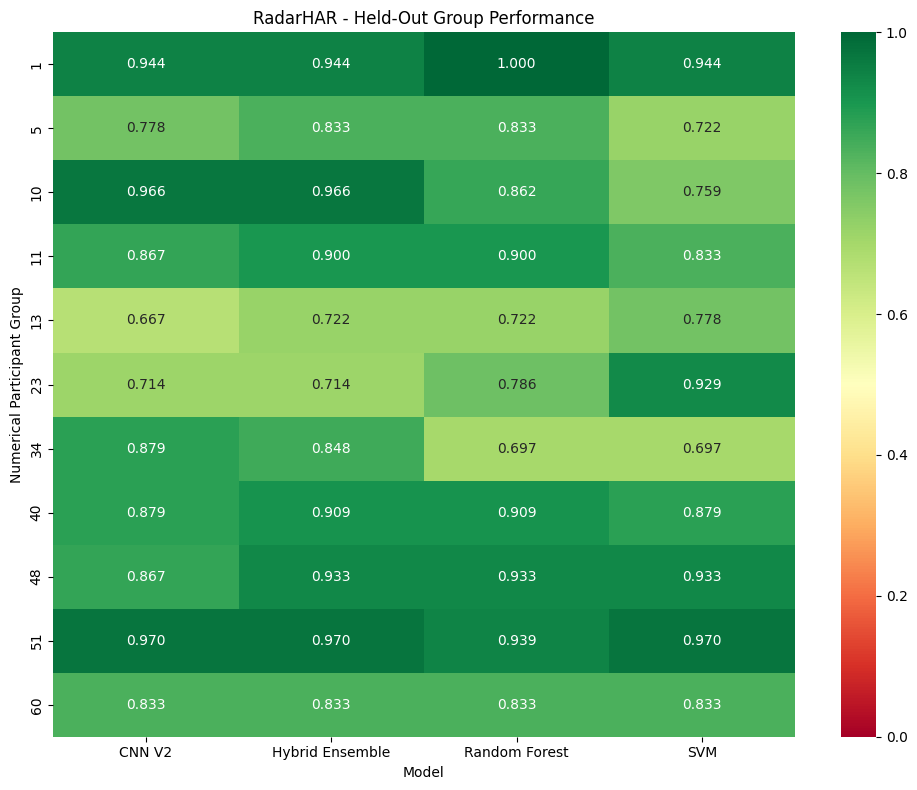

In [71]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    group_accuracy,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

plt.title(
    "RadarHAR - Held-Out Group Performance"
)

plt.xlabel("Model")
plt.ylabel("Numerical Participant Group")

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "group_performance_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [72]:
group_summary = group_results_df.groupby(
    "Model"
)["Accuracy"].agg(
    ["mean", "median", "std", "min", "max"]
)

display(group_summary.round(4))

ensemble_groups = group_results_df[
    group_results_df["Model"] == "Hybrid Ensemble"
]

print("\nLowest-performing groups:")

display(
    ensemble_groups.nsmallest(3, "Accuracy")
)

print("\nHighest-performing groups:")

display(
    ensemble_groups.nlargest(3, "Accuracy")
)

,mean,median,std,min,max
Model,,,,,
CNN V2,0.8511,0.8667,0.0981,0.6667,0.9697
Hybrid Ensemble,0.8703,0.9000,0.0896,0.7143,0.9697
Random Forest,0.8560,0.8621,0.0936,0.6970,1.0000
SVM,0.8434,0.8333,0.0952,0.6970,0.9697



Lowest-performing groups:


,Group ID,Model,Recordings,Accuracy,Macro F1
23,23,Hybrid Ensemble,14,0.714286,0.671429
19,13,Hybrid Ensemble,18,0.722222,0.740909
7,5,Hybrid Ensemble,18,0.833333,0.838095



Highest-performing groups:


,Group ID,Model,Recordings,Accuracy,Macro F1
39,51,Hybrid Ensemble,33,0.969697,0.972028
11,10,Hybrid Ensemble,29,0.965517,0.961039
3,1,Hybrid Ensemble,18,0.944444,0.942857


In [73]:
metadata = pd.read_csv(
    SAVE_DIR / "metadata.csv"
)

print("Metadata shape:", metadata.shape)

print("\nAvailable columns:")
print(metadata.columns.tolist())

print("\nFirst five rows:")
display(metadata.head())

print("\nMissing values:")
print(metadata.isna().sum())

print("\nDataset size:", len(X))
print("Metadata size:", len(metadata))

Metadata shape: (1754, 9)

Available columns:
['filename', 'filepath', 'person_id', 'activity_id', 'activity', 'repetition', 'collection', 'subject_session', 'group_id']

First five rows:


,filename,filepath,person_id,activity_id,activity,repetition,collection,subject_session,group_id
0,1P36A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,36,1,Walking,1,1 December 2017 Dataset,1 December 2017 Dataset_P36,36
1,1P36A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,36,1,Walking,2,1 December 2017 Dataset,1 December 2017 Dataset_P36,36
2,1P36A01R03.dat,/content/RadarHAR_dataset/1 December 2017 Data...,36,1,Walking,3,1 December 2017 Dataset,1 December 2017 Dataset_P36,36
3,1P37A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,37,1,Walking,1,1 December 2017 Dataset,1 December 2017 Dataset_P37,37
4,1P37A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,37,1,Walking,2,1 December 2017 Dataset,1 December 2017 Dataset_P37,37



Missing values:
filename           0
filepath           0
person_id          0
activity_id        0
activity           0
repetition         0
collection         0
subject_session    0
group_id           0
dtype: int64

Dataset size: 1754
Metadata size: 1754


In [74]:
group_results_df.to_csv(
    SAVE_DIR / "group_robustness_results.csv",
    index=False
)

group_summary.to_csv(
    SAVE_DIR / "group_robustness_summary.csv"
)

print("Group robustness results saved!")

Group robustness results saved!


In [75]:
metadata = pd.read_csv(
    SAVE_DIR / "metadata.csv"
)

assert len(metadata) == len(X)

assert np.array_equal(
    metadata["group_id"].to_numpy(),
    groups
)

expected_activities = np.array(class_names)[y]

assert np.array_equal(
    metadata["activity"].to_numpy(),
    expected_activities
)

test_metadata = metadata.iloc[
    test_idx
].copy().reset_index(drop=True)

assert np.array_equal(
    test_metadata["group_id"].to_numpy(),
    test_groups
)

print("All metadata alignment checks passed!")
print("Test metadata shape:", test_metadata.shape)

display(test_metadata.head())

All metadata alignment checks passed!
Test metadata shape: (259, 9)


,filename,filepath,person_id,activity_id,activity,repetition,collection,subject_session,group_id
0,1P40A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,40,1,Walking,1,1 December 2017 Dataset,1 December 2017 Dataset_P40,40
1,1P40A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,40,1,Walking,2,1 December 2017 Dataset,1 December 2017 Dataset_P40,40
2,1P40A01R03.dat,/content/RadarHAR_dataset/1 December 2017 Data...,40,1,Walking,3,1 December 2017 Dataset,1 December 2017 Dataset_P40,40
3,1P51A01R01.dat,/content/RadarHAR_dataset/1 December 2017 Data...,51,1,Walking,1,1 December 2017 Dataset,1 December 2017 Dataset_P51,51
4,1P51A01R02.dat,/content/RadarHAR_dataset/1 December 2017 Data...,51,1,Walking,2,1 December 2017 Dataset,1 December 2017 Dataset_P51,51


In [76]:
print("Full dataset collection distribution:")

display(
    metadata["collection"].value_counts()
)

print("\nTest dataset collection distribution:")

display(
    test_metadata["collection"].value_counts()
)

print("\nActivity distribution by test collection:")

collection_distribution = pd.crosstab(
    test_metadata["collection"],
    test_metadata["activity"]
)

display(collection_distribution)

Full dataset collection distribution:


,count
collection,
1 December 2017 Dataset,360
5 February 2019 UoG Dataset,306
6 February 2019 NG Homes Dataset,301
7 March 2019 West Cumbria Dataset,289
4 July 2018 Dataset,288
3 June 2017 Dataset,162
2 March 2017 Dataset,48



Test dataset collection distribution:


,count
collection,
5 February 2019 UoG Dataset,90
7 March 2019 West Cumbria Dataset,45
1 December 2017 Dataset,36
6 February 2019 NG Homes Dataset,29
2 March 2017 Dataset,23
3 June 2017 Dataset,18
4 July 2018 Dataset,18



Activity distribution by test collection:


activity,Drinking water,Falling,Picking up an object,Sitting down,Standing up,Walking
collection,,,,,,
1 December 2017 Dataset,6,6,6,6,6,6
2 March 2017 Dataset,4,4,4,3,4,4
3 June 2017 Dataset,3,3,3,2,4,3
4 July 2018 Dataset,3,3,3,3,3,3
5 February 2019 UoG Dataset,15,15,15,15,15,15
6 February 2019 NG Homes Dataset,6,0,6,6,6,5
7 March 2019 West Cumbria Dataset,9,0,9,9,9,9


In [77]:
collection_results = []

for collection in test_metadata["collection"].unique():

    mask = (
        test_metadata["collection"].to_numpy()
        == collection
    )

    for name, predictions in model_predictions.items():

        collection_results.append({
            "Collection": collection,
            "Model": name,
            "Recordings": int(mask.sum()),

            "Groups": test_metadata.loc[
                mask, "group_id"
            ].nunique(),

            "Classes Present": len(
                np.unique(y_test[mask])
            ),

            "Accuracy": accuracy_score(
                y_test[mask],
                predictions[mask]
            ),

            "Macro F1": f1_score(
                y_test[mask],
                predictions[mask],
                labels=np.unique(y_test[mask]),
                average="macro",
                zero_division=0
            )
        })

collection_results_df = pd.DataFrame(
    collection_results
)

display(collection_results_df.round(4))

,Collection,Model,Recordings,Groups,Classes Present,Accuracy,Macro F1
0,1 December 2017 Dataset,Random Forest,36,2,6,0.9722,0.9720
1,1 December 2017 Dataset,SVM,36,2,6,0.9444,0.9443
2,1 December 2017 Dataset,CNN V2,36,2,6,0.9444,0.9459
3,1 December 2017 Dataset,Hybrid Ensemble,36,2,6,0.9722,0.9720
4,2 March 2017 Dataset,Random Forest,23,2,6,0.9130,0.9153
5,2 March 2017 Dataset,SVM,23,2,6,0.6957,0.6859
6,2 March 2017 Dataset,CNN V2,23,2,6,1.0000,1.0000
7,2 March 2017 Dataset,Hybrid Ensemble,23,2,6,1.0000,1.0000
8,3 June 2017 Dataset,Random Forest,18,1,6,0.7778,0.7722
9,3 June 2017 Dataset,SVM,18,1,6,0.7778,0.7841


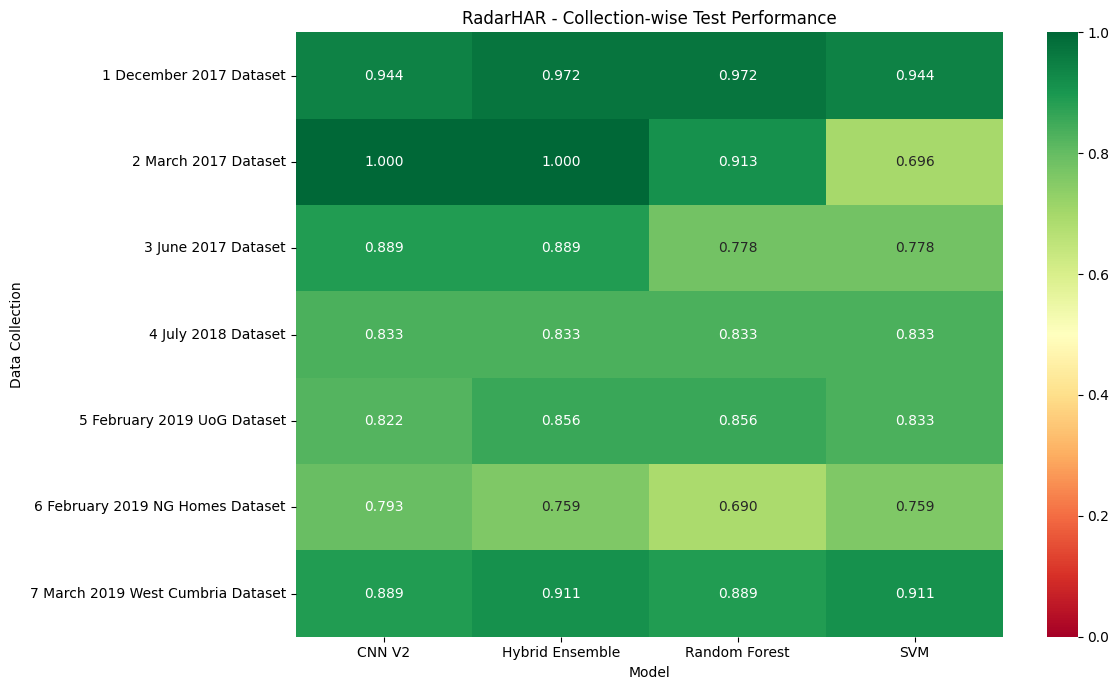

In [78]:
collection_accuracy = collection_results_df.pivot(
    index="Collection",
    columns="Model",
    values="Accuracy"
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    collection_accuracy,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

plt.title(
    "RadarHAR - Collection-wise Test Performance"
)

plt.xlabel("Model")
plt.ylabel("Data Collection")

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "collection_performance_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
collection_results_df.to_csv(
    SAVE_DIR / "collection_robustness_results.csv",
    index=False
)

collection_accuracy.to_csv(
    SAVE_DIR / "collection_accuracy_summary.csv"
)

test_metadata.to_csv(
    SAVE_DIR / "test_metadata.csv",
    index=False
)

print("Collection robustness results saved!")

Collection robustness results saved!


DAY-11

In [80]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/RadarHAR")
MODEL_DIR = SAVE_DIR / "models"

XAI_DIR = SAVE_DIR / "explainability"
XAI_DIR.mkdir(parents=True, exist_ok=True)

best_cnn_v2 = keras.models.load_model(
    MODEL_DIR / "best_cnn_v2.keras",
    compile=False
)

print("CNN V2 loaded successfully!")
print("Input shape:", best_cnn_v2.input_shape)
print("Output shape:", best_cnn_v2.output_shape)

CNN V2 loaded successfully!
Input shape: (None, 128, 128, 1)
Output shape: (None, 6)


In [81]:
conv_layers = []

for layer in best_cnn_v2.layers:

    if isinstance(layer, keras.layers.Conv2D):

        conv_layers.append(layer.name)

        print(
            "Convolutional layer:",
            layer.name
        )

last_conv_layer_name = conv_layers[-1]

print("\nSelected Grad-CAM layer:")
print(last_conv_layer_name)

Convolutional layer: conv2d_3
Convolutional layer: conv2d_4
Convolutional layer: conv2d_5
Convolutional layer: conv2d_6

Selected Grad-CAM layer:
conv2d_6


In [82]:
dataset = np.load(
    SAVE_DIR / "RadarHAR_dataset_v1.npz"
)

print("Dataset keys:", dataset.files)

X = dataset["X"]
y = dataset["y"]

splits = np.load(
    SAVE_DIR / "dataset_splits.npz"
)

val_idx = splits["val_idx"]

X_val = X[val_idx].reshape(
    -1, 128, 128, 1
).astype(np.float32)

y_val = y[val_idx]

class_names = [
    "Walking",
    "Sitting down",
    "Standing up",
    "Drinking water",
    "Picking up an object",
    "Falling"
]

print("Validation spectrograms:", X_val.shape)
print("Validation labels:", y_val.shape)

Dataset keys: ['X', 'y', 'groups', 'indices']
Validation spectrograms: (301, 128, 128, 1)
Validation labels: (301,)


In [83]:
xai_probabilities = best_cnn_v2.predict(
    X_val,
    verbose=0
)

xai_predictions = np.argmax(
    xai_probabilities,
    axis=1
)

xai_confidence = np.max(
    xai_probabilities,
    axis=1
)

correct_indices = np.where(
    xai_predictions == y_val
)[0]

incorrect_indices = np.where(
    xai_predictions != y_val
)[0]

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

print(
    "Validation accuracy:",
    np.mean(xai_predictions == y_val)
)

Correct predictions: 268
Incorrect predictions: 33
Validation accuracy: 0.8903654485049833


In [84]:
inputs = keras.Input(
    shape=best_cnn_v2.input_shape[1:]
)

x = inputs

for layer in best_cnn_v2.layers:

    x = layer(x)

    if layer.name == last_conv_layer_name:

        conv_output = x

grad_model = keras.Model(
    inputs=inputs,
    outputs=[conv_output, x]
)

print("Grad-CAM model created successfully!")

print(
    "Convolutional output:",
    grad_model.output_shape[0]
)

print(
    "Prediction output:",
    grad_model.output_shape[1]
)

Grad-CAM model created successfully!
Convolutional output: (None, 16, 16, 64)
Prediction output: (None, 6)


In [85]:
def generate_gradcam(image, class_index=None):

    image = tf.convert_to_tensor(
        image,
        dtype=tf.float32
    )

    image = tf.reshape(
        image,
        (1, 128, 128, 1)
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image,
            training=False
        )

        if class_index is None:

            class_index = tf.argmax(
                predictions[0]
            )

        class_score = predictions[:, class_index]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    feature_maps = conv_outputs[0]

    heatmap = tf.reduce_sum(
        feature_maps * weights,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    heatmap = tf.math.divide_no_nan(
        heatmap,
        tf.reduce_max(heatmap)
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (128, 128)
    )

    return tf.squeeze(heatmap).numpy()

print("Grad-CAM function ready!")

Grad-CAM function ready!


Actual: Walking
Predicted: Walking
Confidence: 0.999998
Heatmap shape: (128, 128)
Heatmap minimum: 0.0
Heatmap maximum: 0.9731101
All finite: True


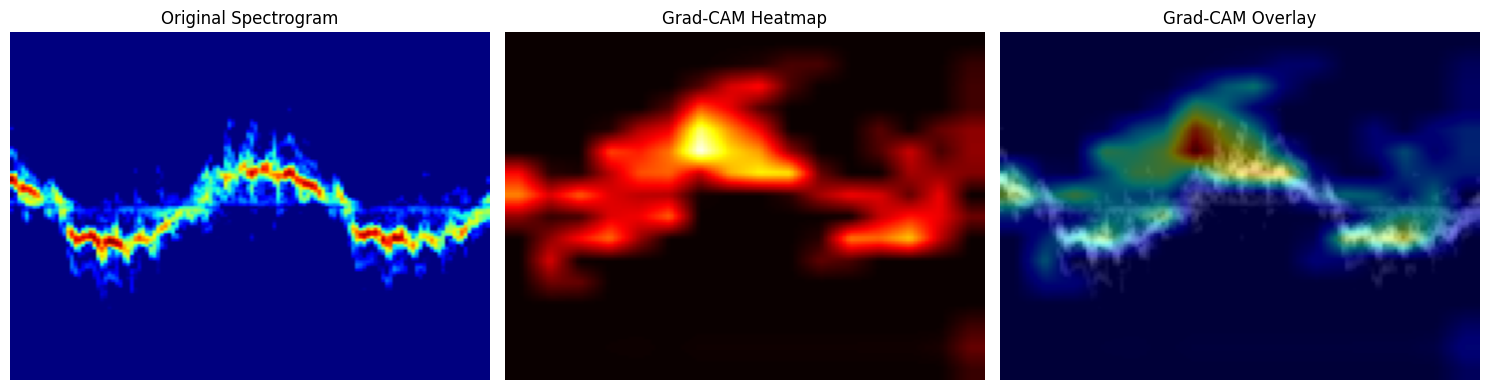

In [86]:
idx = correct_indices[0]

image = X_val[idx].squeeze()

predicted_class = xai_predictions[idx]

heatmap = generate_gradcam(
    X_val[idx],
    predicted_class
)

print("Actual:", class_names[y_val[idx]])

print(
    "Predicted:",
    class_names[predicted_class]
)

print("Confidence:", xai_confidence[idx])

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())
print("All finite:", np.isfinite(heatmap).all())

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

axes[0].imshow(
    image,
    cmap="jet",
    origin="lower",
    aspect="auto"
)

axes[0].set_title("Original Spectrogram")

axes[1].imshow(
    heatmap,
    cmap="hot",
    origin="lower",
    aspect="auto",
    vmin=0,
    vmax=1
)

axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(
    image,
    cmap="gray",
    origin="lower",
    aspect="auto"
)

axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    aspect="auto",
    vmin=0,
    vmax=1
)

axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    XAI_DIR / "first_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

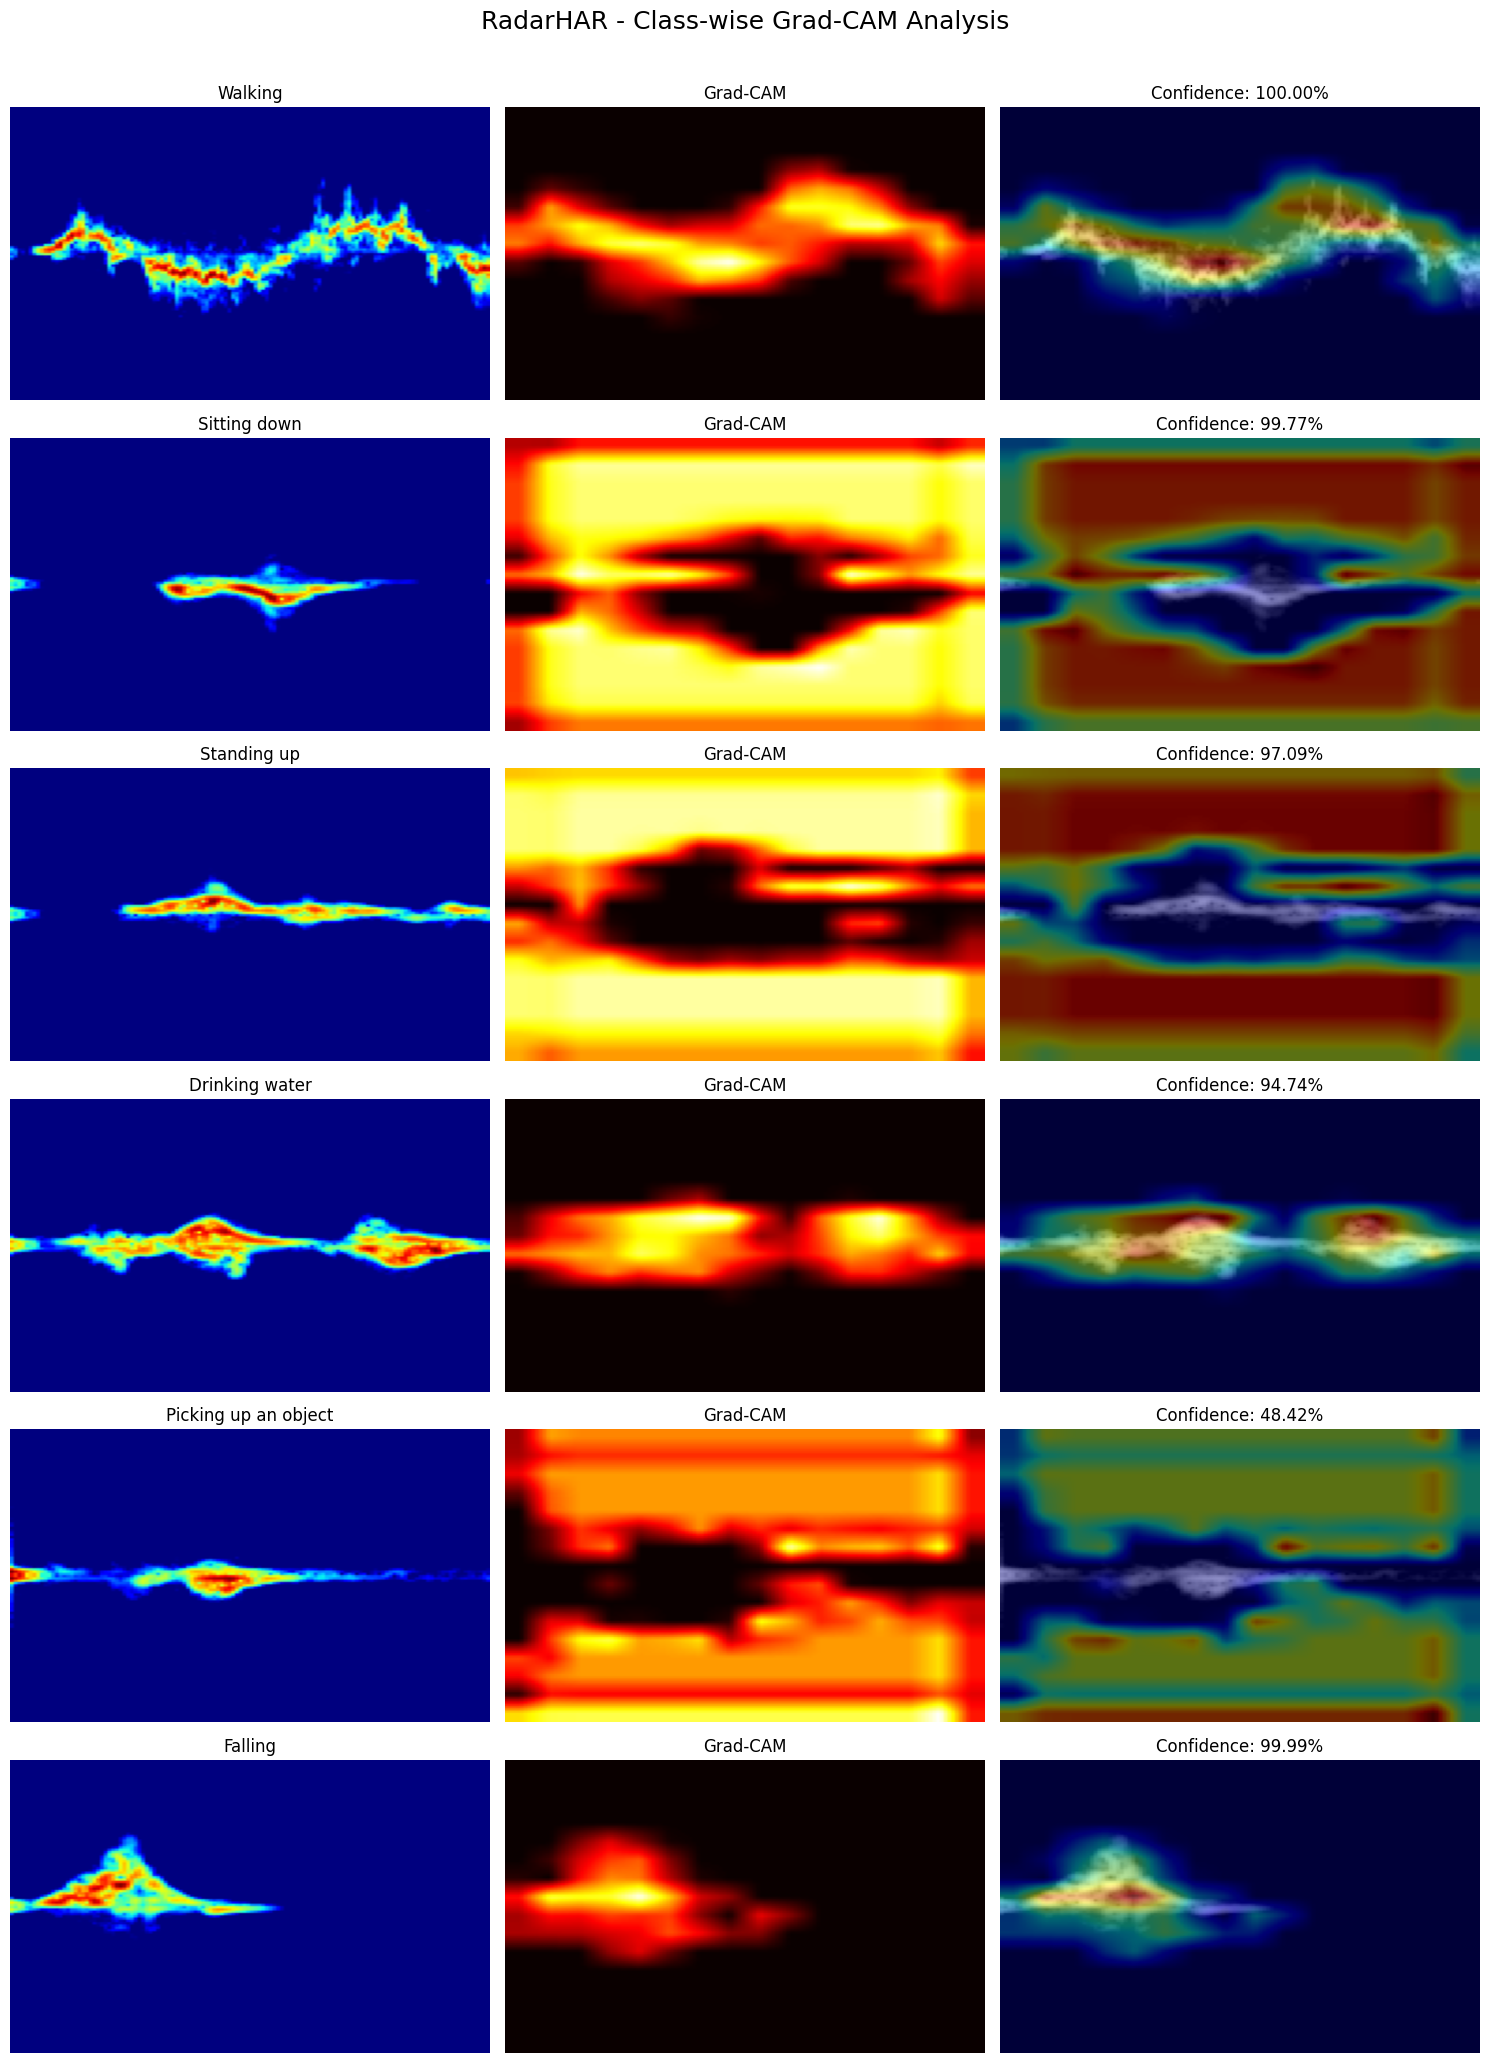

In [87]:
fig, axes = plt.subplots(
    6, 3,
    figsize=(15, 21)
)

rng = np.random.default_rng(42)

for class_id in range(6):

    candidates = np.where(
        (y_val == class_id) &
        (xai_predictions == class_id)
    )[0]

    idx = rng.choice(candidates)

    image = X_val[idx].squeeze()

    heatmap = generate_gradcam(
        X_val[idx],
        class_id
    )

    axes[class_id, 0].imshow(
        image,
        cmap="jet",
        origin="lower",
        aspect="auto"
    )

    axes[class_id, 0].set_title(
        class_names[class_id]
    )

    axes[class_id, 1].imshow(
        heatmap,
        cmap="hot",
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 1].set_title(
        "Grad-CAM"
    )

    axes[class_id, 2].imshow(
        image,
        cmap="gray",
        origin="lower",
        aspect="auto"
    )

    axes[class_id, 2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 2].set_title(
        f"Confidence: {xai_confidence[idx]:.2%}"
    )

    for ax in axes[class_id]:
        ax.axis("off")

fig.suptitle(
    "RadarHAR - Class-wise Grad-CAM Analysis",
    fontsize=18
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    XAI_DIR / "classwise_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
last_layer = best_cnn_v2.layers[-1]

print("Final layer:", last_layer.name)
print("Layer type:", type(last_layer).__name__)
print("Activation:", last_layer.get_config().get("activation"))
print("Grad-CAM layer:", last_conv_layer_name)

best_cnn_v2.summary()

Final layer: dense_3
Layer type: Dense
Activation: softmax
Grad-CAM layer: conv2d_6


Model: "RadarHAR_CNN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 128, 128, 16)   │            32 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 64, 64, 32)     │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 32, 32, 64)     │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, 16, 16, 64)     │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585,766 (2.23 MB)

 Trainable params: 585,766 (2.23 MB)

 Non-trainable params: 0 (0.00 B)

In [89]:
assert isinstance(last_layer, keras.layers.Dense)
assert last_layer.get_config()["activation"] == "softmax"

inputs = keras.Input(shape=(128, 128, 1))

x = inputs

for layer in best_cnn_v2.layers[:-1]:

    x = layer(x)

    if layer.name == last_conv_layer_name:
        conv_output = x

logit_layer = keras.layers.Dense(
    units=6,
    activation=None,
    name="gradcam_logits"
)

logits = logit_layer(x)

logit_grad_model = keras.Model(
    inputs=inputs,
    outputs=[conv_output, logits]
)

logit_layer.set_weights(last_layer.get_weights())

print("Logit-based Grad-CAM model created!")

Logit-based Grad-CAM model created!


In [90]:
_, sample_logits = logit_grad_model(
    X_val[:32],
    training=False
)

new_probabilities = tf.nn.softmax(
    sample_logits,
    axis=-1
).numpy()

original_probabilities = best_cnn_v2.predict(
    X_val[:32],
    verbose=0
)

difference = np.max(
    np.abs(
        new_probabilities - original_probabilities
    )
)

print("Maximum probability difference:", difference)

assert np.allclose(
    new_probabilities,
    original_probabilities,
    atol=1e-5
)

print("Model equivalence verified!")

Maximum probability difference: 2.3841858e-07
Model equivalence verified!


In [91]:
def generate_logit_gradcam(image, class_index=None):

    image = tf.convert_to_tensor(
        image.reshape(1, 128, 128, 1),
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        feature_maps, logits = logit_grad_model(
            image,
            training=False
        )

        if class_index is None:
            class_index = tf.argmax(logits[0])

        score = logits[:, class_index]

    gradients = tape.gradient(
        score,
        feature_maps
    )

    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        feature_maps[0] * weights,
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    heatmap = tf.math.divide_no_nan(
        heatmap,
        tf.reduce_max(heatmap)
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (128, 128)
    )

    return tf.squeeze(heatmap).numpy()

print("Logit Grad-CAM function ready!")

Logit Grad-CAM function ready!


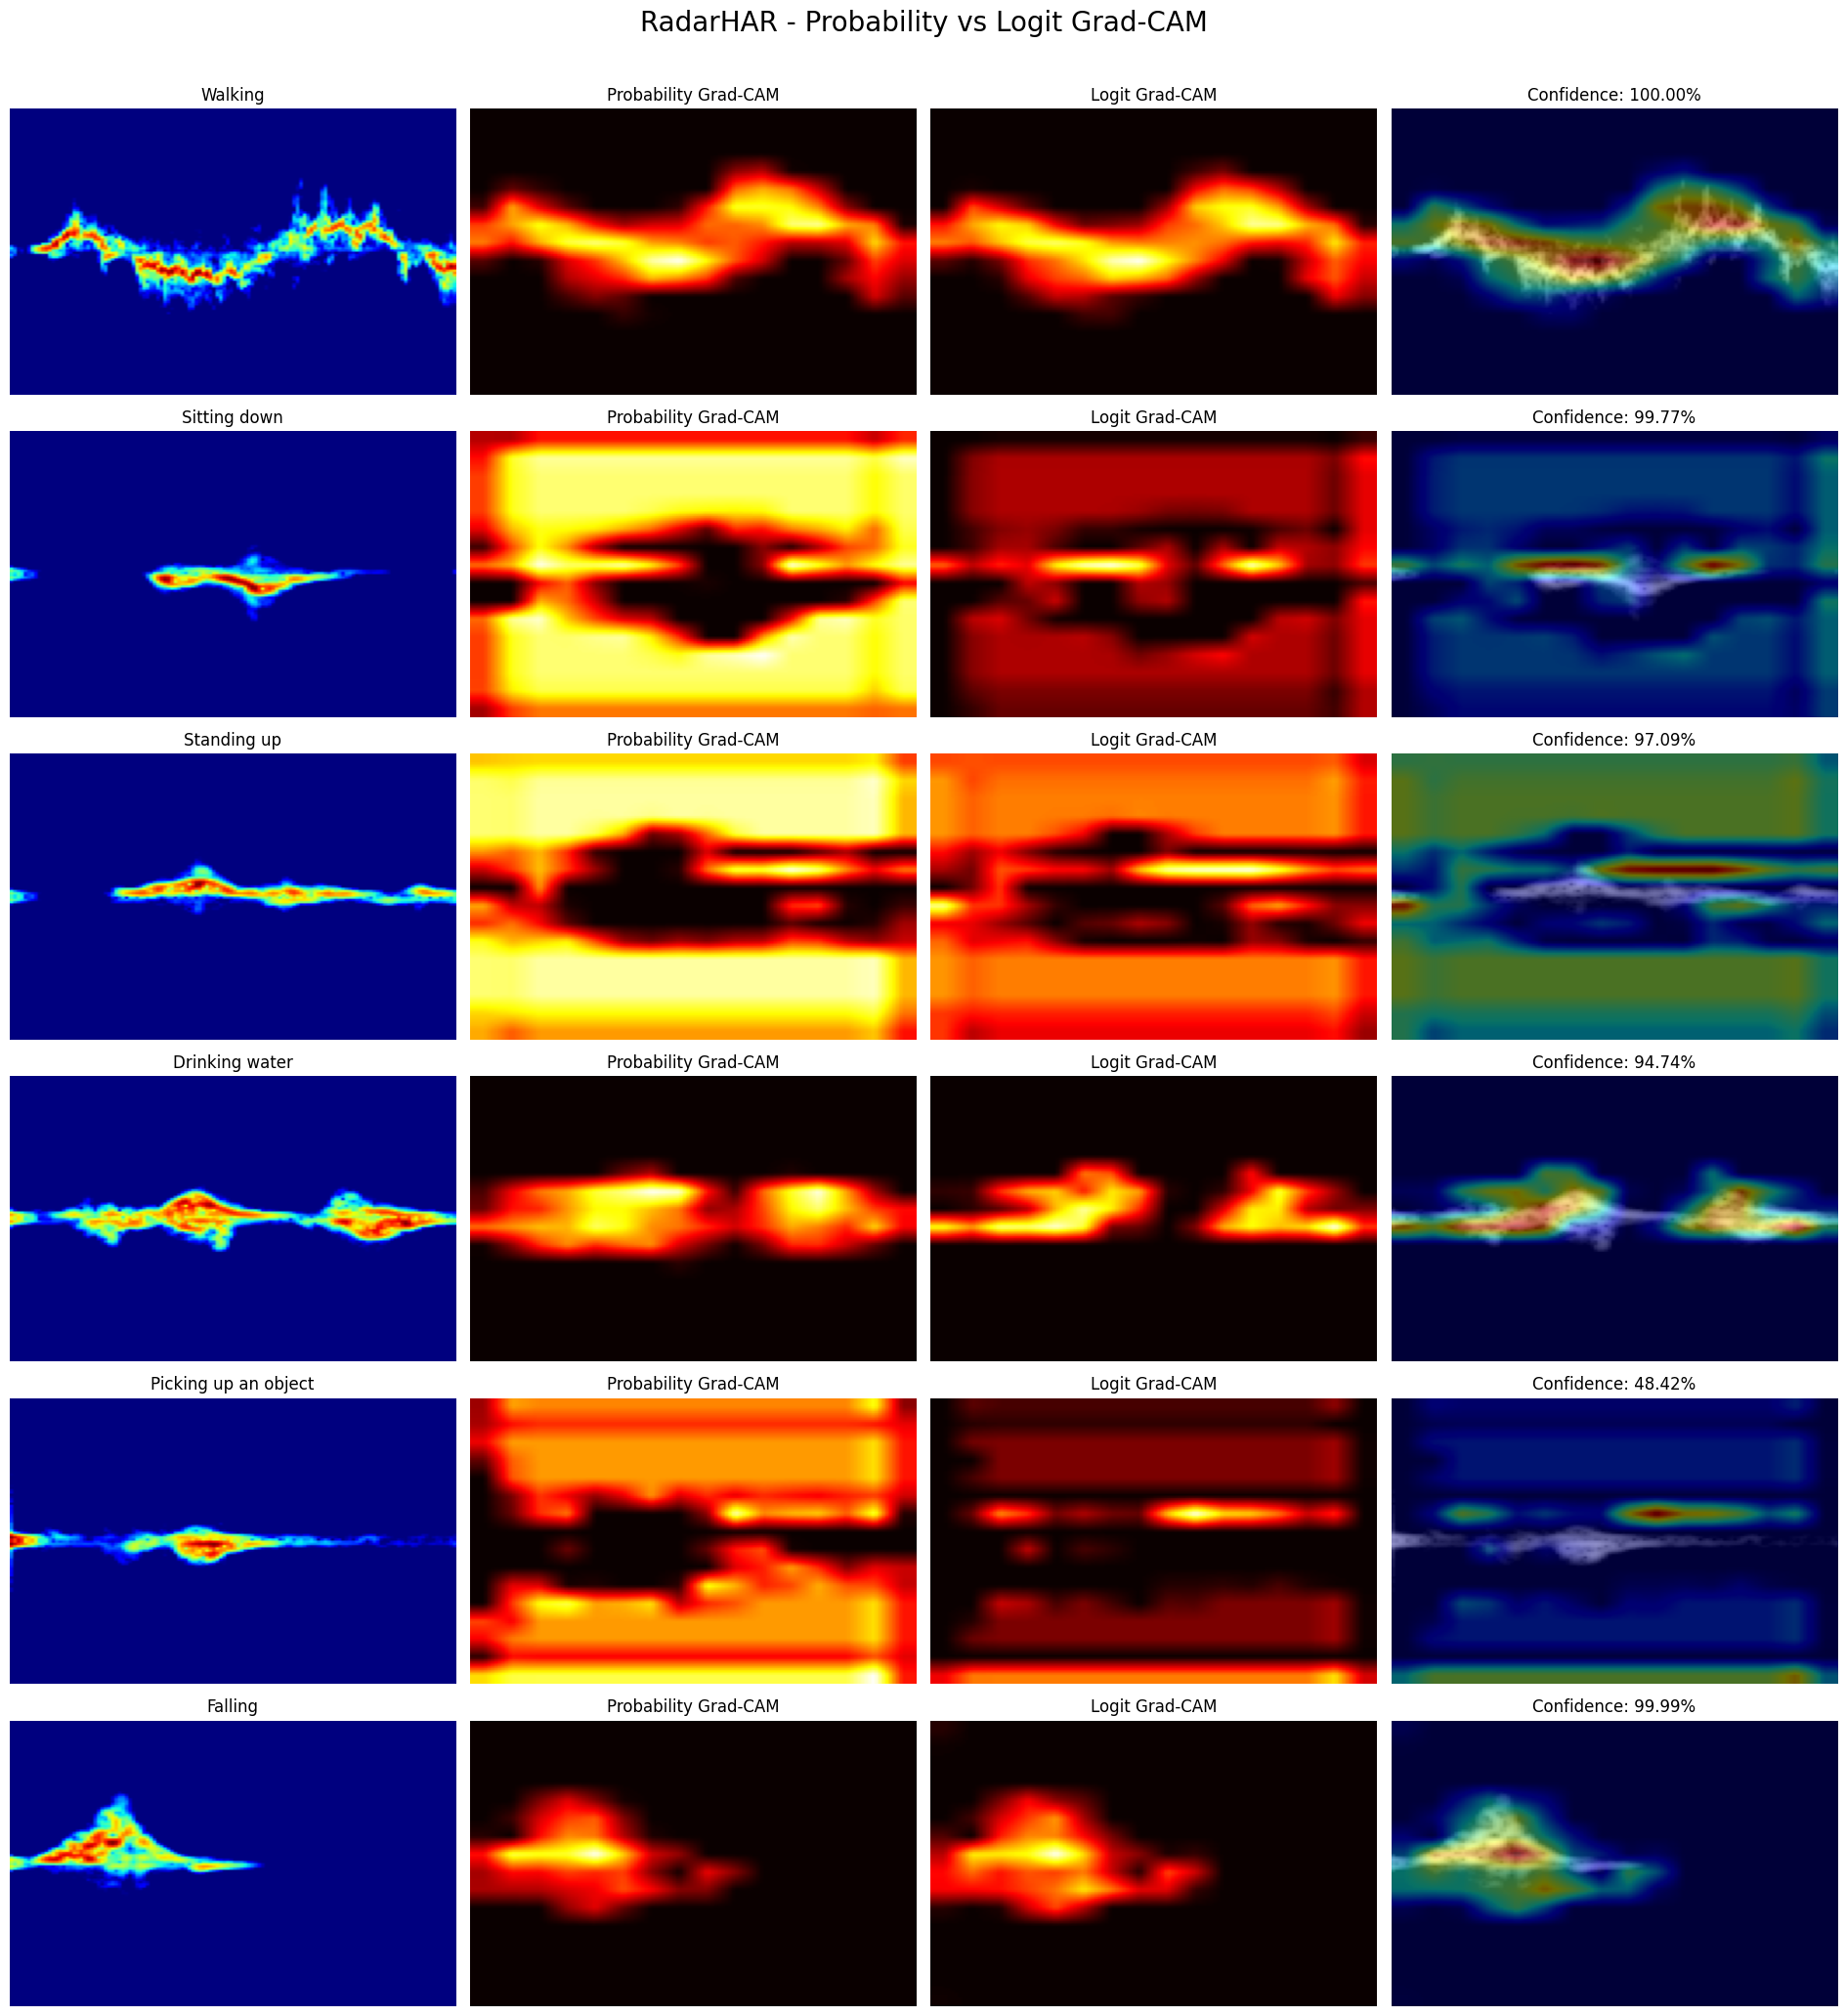

In [92]:
fig, axes = plt.subplots(
    6, 4,
    figsize=(19, 21)
)

rng = np.random.default_rng(42)

for class_id in range(6):

    candidates = np.where(
        (y_val == class_id) &
        (xai_predictions == class_id)
    )[0]

    idx = rng.choice(candidates)

    image = X_val[idx].squeeze()

    probability_cam = generate_gradcam(
        X_val[idx],
        class_id
    )

    logit_cam = generate_logit_gradcam(
        X_val[idx],
        class_id
    )

    axes[class_id, 0].imshow(
        image,
        cmap="jet",
        origin="lower",
        aspect="auto"
    )

    axes[class_id, 0].set_title(
        class_names[class_id]
    )

    axes[class_id, 1].imshow(
        probability_cam,
        cmap="hot",
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 1].set_title(
        "Probability Grad-CAM"
    )

    axes[class_id, 2].imshow(
        logit_cam,
        cmap="hot",
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 2].set_title(
        "Logit Grad-CAM"
    )

    axes[class_id, 3].imshow(
        image,
        cmap="gray",
        origin="lower",
        aspect="auto"
    )

    axes[class_id, 3].imshow(
        logit_cam,
        cmap="jet",
        alpha=0.45,
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 3].set_title(
        f"Confidence: {xai_confidence[idx]:.2%}"
    )

    for ax in axes[class_id]:
        ax.axis("off")

fig.suptitle(
    "RadarHAR - Probability vs Logit Grad-CAM",
    fontsize=20
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    XAI_DIR / "gradcam_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [93]:
def signal_activation_overlap(image, heatmap, threshold=0.1):

    image = image.squeeze()

    signal_mask = image >= threshold

    total_activation = np.sum(heatmap)

    if total_activation <= 1e-8:
        return np.nan, np.mean(signal_mask)

    signal_activation = np.sum(
        heatmap[signal_mask]
    )

    overlap = signal_activation / total_activation

    signal_area = np.mean(signal_mask)

    return overlap, signal_area

print("Signal overlap function ready!")

Signal overlap function ready!


In [94]:
xai_records = []

for idx in range(len(X_val)):

    predicted_class = int(xai_predictions[idx])

    probability_cam = generate_gradcam(
        X_val[idx],
        predicted_class
    )

    logit_cam = generate_logit_gradcam(
        X_val[idx],
        predicted_class
    )

    probability_overlap, signal_area = (
        signal_activation_overlap(
            X_val[idx],
            probability_cam
        )
    )

    logit_overlap, _ = signal_activation_overlap(
        X_val[idx],
        logit_cam
    )

    xai_records.append({
        "Recording": idx,
        "Actual": class_names[y_val[idx]],
        "Predicted": class_names[predicted_class],
        "Correct": bool(
            y_val[idx] == predicted_class
        ),
        "Confidence": float(xai_confidence[idx]),
        "Signal Area": signal_area,
        "Probability Overlap": probability_overlap,
        "Logit Overlap": logit_overlap
    })

    if (idx + 1) % 50 == 0:
        print(f"Processed {idx + 1}/{len(X_val)}")

xai_df = pd.DataFrame(xai_records)

xai_df.to_csv(
    XAI_DIR / "gradcam_quantitative_results.csv",
    index=False
)

print("Quantitative analysis completed!")
print("Total recordings:", len(xai_df))

display(xai_df.head())

Processed 50/301
Processed 100/301
Processed 150/301
Processed 200/301
Processed 250/301
Processed 300/301
Quantitative analysis completed!
Total recordings: 301


,Recording,Actual,Predicted,Correct,Confidence,Signal Area,Probability Overlap,Logit Overlap
0,0,Walking,Walking,True,0.999998,0.128723,0.361118,0.530258
1,1,Walking,Walking,True,0.999997,0.117126,0.501427,0.539661
2,2,Walking,Walking,True,0.999997,0.124695,0.530179,0.552852
3,3,Walking,Walking,True,0.999998,0.148254,0.525474,0.536099
4,4,Walking,Walking,True,0.999971,0.128784,0.480580,0.507562


In [95]:
last_layer = best_cnn_v2.layers[-1]

assert isinstance(last_layer, keras.layers.Dense)
assert last_layer.get_config()["activation"] == "softmax"

inputs = keras.Input(shape=(128, 128, 1))
x = inputs

for layer in best_cnn_v2.layers[:-1]:
    x = layer(x)
    if layer.name == last_conv_layer_name:
        conv_output = x

logit_layer = keras.layers.Dense(6, activation=None)
logits = logit_layer(x)

logit_grad_model = keras.Model(
    inputs, [conv_output, logits]
)

logit_layer.set_weights(last_layer.get_weights())

_, sample_logits = logit_grad_model(X_val[:32], training=False)

assert np.allclose(
    tf.nn.softmax(sample_logits).numpy(),
    best_cnn_v2.predict(X_val[:32], verbose=0),
    atol=1e-5
)

def generate_logit_gradcam(image, class_id):
    image = tf.convert_to_tensor(
        image.reshape(1, 128, 128, 1),
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        features, logits = logit_grad_model(
            image, training=False
        )
        score = logits[:, class_id]

    gradients = tape.gradient(score, features)
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(features[0] * weights, axis=-1)
    heatmap = tf.nn.relu(heatmap)

    heatmap = tf.math.divide_no_nan(
        heatmap, tf.reduce_max(heatmap)
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], (128, 128)
    )

    return tf.squeeze(heatmap).numpy()

print("Logit Grad-CAM ready and verified!")

Logit Grad-CAM ready and verified!


In [96]:
xai_records = []

predictions = best_cnn_v2.predict(X_val, verbose=0)

for idx in range(len(X_val)):

    class_id = int(np.argmax(predictions[idx]))

    heatmap = generate_logit_gradcam(
        X_val[idx], class_id
    )

    mask = X_val[idx].squeeze() >= 0.1

    signal_area = mask.mean()

    overlap = (
        heatmap[mask].sum() / heatmap.sum()
        if heatmap.sum() > 0 else np.nan
    )

    xai_records.append({
        "Activity": class_names[y_val[idx]],
        "Correct": class_id == y_val[idx],
        "Signal Area": signal_area,
        "GradCAM Overlap": overlap
    })

xai_df = pd.DataFrame(xai_records)

xai_summary = xai_df.groupby("Activity").agg(
    Recordings=("Correct", "size"),
    Signal_Area=("Signal Area", "mean"),
    GradCAM_Overlap=("GradCAM Overlap", "mean")
)

xai_summary["Enrichment"] = (
    xai_summary["GradCAM_Overlap"] /
    xai_summary["Signal_Area"].replace(0, np.nan)
)

display(xai_summary.round(4))

print("Undefined heatmaps:",
      xai_df["GradCAM Overlap"].isna().sum())

,Recordings,Signal_Area,GradCAM_Overlap,Enrichment
Activity,,,,
Drinking water,52,0.0714,0.2343,3.2834
Falling,33,0.0664,0.3783,5.6929
Picking up an object,54,0.0613,0.1727,2.8167
Sitting down,54,0.0502,0.2365,4.7117
Standing up,54,0.0513,0.0483,0.9409
Walking,54,0.1220,0.5017,4.1110


Undefined heatmaps: 0


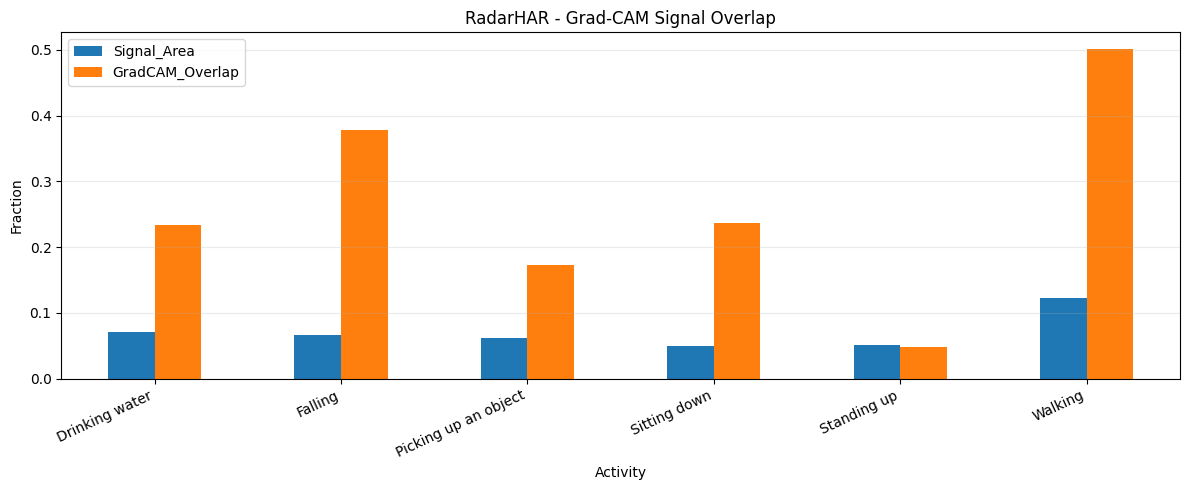

Day 11 results saved successfully!


In [97]:
XAI_DIR.mkdir(parents=True, exist_ok=True)

xai_df.to_csv(
    XAI_DIR / "gradcam_quantitative_results.csv",
    index=False
)

xai_summary.to_csv(
    XAI_DIR / "gradcam_classwise_summary.csv"
)

xai_summary[
    ["Signal_Area", "GradCAM_Overlap"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("RadarHAR - Grad-CAM Signal Overlap")
plt.ylabel("Fraction")
plt.xlabel("Activity")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    XAI_DIR / "gradcam_signal_overlap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Day 11 results saved successfully!")

DAY-12

In [98]:
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
import json

from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/RadarHAR")
MODEL_DIR = SAVE_DIR / "models"

rf_model = joblib.load(
    MODEL_DIR / "random_forest.joblib"
)

cnn_model = tf.keras.models.load_model(
    MODEL_DIR / "best_cnn_v2.keras",
    compile=False
)

RF_WEIGHT = 0.65
CNN_WEIGHT = 0.35

class_names = [
    "Walking",
    "Sitting down",
    "Standing up",
    "Drinking water",
    "Picking up an object",
    "Falling"
]

assert np.array_equal(
    rf_model.classes_, np.arange(6)
)

print("Final models loaded successfully!")

Final models loaded successfully!


In [99]:
def predict_activity(spectrogram, features):

    spectrogram = np.asarray(
        spectrogram, dtype=np.float32
    ).reshape(1, 128, 128, 1)

    features = np.asarray(features).reshape(1, -1)

    assert features.shape[1] == 2029

    rf_probs = rf_model.predict_proba(features)[0]

    cnn_probs = cnn_model.predict(
        spectrogram, verbose=0
    )[0]

    ensemble_probs = (
        RF_WEIGHT * rf_probs +
        CNN_WEIGHT * cnn_probs
    )

    predicted_class = np.argmax(ensemble_probs)

    return {
        "Predicted Activity": class_names[predicted_class],
        "Confidence": float(ensemble_probs[predicted_class]),
        "Random Forest": class_names[np.argmax(rf_probs)],
        "CNN": class_names[np.argmax(cnn_probs)],
        "Probabilities": {
            name: float(prob)
            for name, prob in zip(
                class_names, ensemble_probs
            )
        }
    }

print("Hybrid prediction function ready!")

Hybrid prediction function ready!


Actual Activity: Walking
Predicted Activity: Walking
Confidence: 98.27%
Random Forest: Walking
CNN: Walking


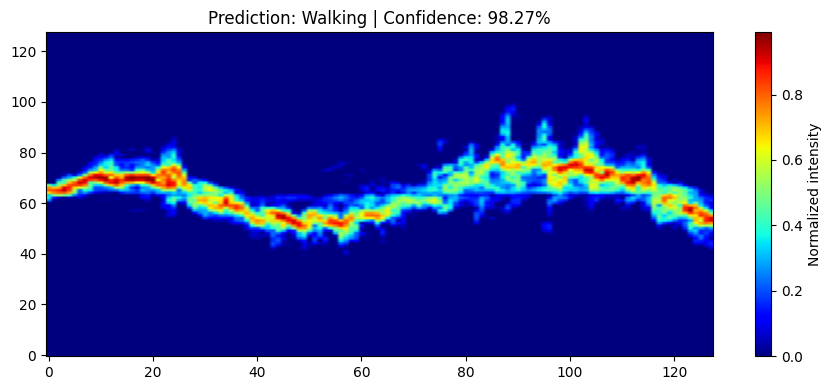

In [100]:
all_features = np.load(
    SAVE_DIR / "extracted_features.npy"
)

test_features = all_features[test_idx]

assert len(test_features) == len(X_test) == len(y_test)

idx = 0

result = predict_activity(
    X_test[idx],
    test_features[idx]
)

print("Actual Activity:", class_names[y_test[idx]])
print("Predicted Activity:", result["Predicted Activity"])
print("Confidence:", f'{result["Confidence"]:.2%}')
print("Random Forest:", result["Random Forest"])
print("CNN:", result["CNN"])

plt.figure(figsize=(9, 4))

plt.imshow(
    X_test[idx].squeeze(),
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.title(
    f'Prediction: {result["Predicted Activity"]}'
    f' | Confidence: {result["Confidence"]:.2%}'
)

plt.colorbar(label="Normalized intensity")
plt.tight_layout()
plt.show()

In [101]:
pipeline_results = []

rng = np.random.default_rng(42)

selected_indices = rng.choice(
    len(X_test),
    size=10,
    replace=False
)

for idx in selected_indices:

    result = predict_activity(
        X_test[idx],
        test_features[idx]
    )

    actual = class_names[y_test[idx]]

    pipeline_results.append({
        "Recording": int(idx),
        "Actual": actual,
        "Predicted": result["Predicted Activity"],
        "Confidence": result["Confidence"],
        "Correct": actual == result["Predicted Activity"]
    })

pipeline_df = pd.DataFrame(pipeline_results)

display(pipeline_df)

pipeline_df.to_csv(
    SAVE_DIR / "prediction_pipeline_demo.csv",
    index=False
)

print("Pipeline demonstration saved!")

,Recording,Actual,Predicted,Confidence,Correct
0,255,Picking up an object,Drinking water,0.438302,False
1,194,Sitting down,Sitting down,0.617978,True
2,22,Drinking water,Drinking water,0.720772,True
3,164,Picking up an object,Picking up an object,0.645913,True
4,111,Sitting down,Sitting down,0.934132,True
5,109,Walking,Walking,0.839505,True
6,179,Falling,Falling,0.791715,True
7,24,Picking up an object,Picking up an object,0.609861,True
8,51,Picking up an object,Picking up an object,0.649215,True
9,218,Walking,Walking,0.997833,True


Pipeline demonstration saved!


DAY-13

In [102]:
!pip install -q gradio

In [103]:
import gradio as gr
import matplotlib.pyplot as plt

def radarhar_demo(recording):

    idx = int(recording)

    result = predict_activity(
        X_test[idx],
        test_features[idx]
    )

    fig, ax = plt.subplots(figsize=(9, 4))

    im = ax.imshow(
        X_test[idx].squeeze(),
        cmap="jet",
        aspect="auto",
        origin="lower"
    )

    ax.set_title("Radar Micro-Doppler Spectrogram")
    ax.set_xlabel("Time bins")
    ax.set_ylabel("Doppler bins")

    fig.colorbar(im, ax=ax)
    fig.tight_layout()

    summary = (
        f"Actual Activity: {class_names[y_test[idx]]}\n"
        f"Predicted Activity: {result['Predicted Activity']}\n"
        f"Confidence: {result['Confidence']:.2%}\n\n"
        f"Random Forest: {result['Random Forest']}\n"
        f"CNN V2: {result['CNN']}"
    )

    return fig, summary, result["Probabilities"]

print("Interactive prediction function ready!")

Interactive prediction function ready!


In [104]:
demo = gr.Interface(
    fn=radarhar_demo,

    inputs=gr.Slider(
        minimum=0,
        maximum=len(X_test)-1,
        step=1,
        value=0,
        label="Select Radar Recording"
    ),

    outputs=[
        gr.Plot(label="Radar Spectrogram"),
        gr.Textbox(label="Prediction Results"),
        gr.Label(
            label="Activity Probabilities",
            num_top_classes=6
        )
    ],

    title="RadarHAR — AI Human Activity Recognition",

    description=(
        "Radar-based human activity recognition using "
        "a hybrid Random Forest and CNN ensemble. "
        "Select a recording to classify its activity."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://978ab1217f87dd60d6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


DAY-14

In [105]:
from pathlib import Path

REPO_DIR = SAVE_DIR / "RadarHAR_GitHub"

folders = [
    "notebooks",
    "src",
    "models",
    "results",
    "figures",
    "docs",
    "demo"
]

for folder in folders:
    (REPO_DIR / folder).mkdir(
        parents=True, exist_ok=True
    )

print("GitHub repository structure created!")

GitHub repository structure created!


In [106]:
extensions = {
    ".png", ".csv", ".json",
    ".keras", ".joblib",
    ".ipynb", ".py", ".md"
}

for path in sorted(SAVE_DIR.rglob("*")):

    if REPO_DIR in path.parents:
        continue

    if path.is_file() and path.suffix in extensions:

        if "batches_v1" in path.parts:
            continue

        print(path.relative_to(SAVE_DIR))

baseline_confusion_matrices.png
baseline_results.csv
bootstrap_confidence_intervals.csv
bootstrap_confidence_intervals.png
cnn_confidence_analysis.png
cnn_confusion_matrix.png
cnn_training_curves.png
cnn_training_history.csv
cnn_v2_confusion_matrix.png
cnn_v2_error_analysis.png
cnn_v2_training_history.csv
collection_accuracy_summary.csv
collection_performance_heatmap.png
collection_robustness_results.csv
data/processed/metadata.csv
ensemble_confusion_matrix.png
ensemble_optimization.png
ensemble_statistical_comparison.csv
experiments/cnn_v1/best_cnn.keras
experiments/cnn_v1/cnn_confusion_matrix.png
experiments/cnn_v1/cnn_training_curves.png
experiments/cnn_v1/cnn_training_history.csv
experiments/cnn_v1/model_comparison.csv
experiments/cnn_v1/model_comparison.png
explainability/classwise_gradcam.png
explainability/first_gradcam.png
explainability/gradcam_classwise_summary.csv
explainability/gradcam_method_comparison.png
explainability/gradcam_quantitative_results.csv
explainability/grad

In [107]:
import shutil

model_files = [
    "random_forest.joblib",
    "svm_model.joblib",
    "best_cnn_v2.keras",
    "ensemble_config.json"
]

for filename in model_files:
    shutil.copy2(
        SAVE_DIR / "models" / filename,
        REPO_DIR / "models" / filename
    )

print("Final models copied successfully!")

Final models copied successfully!


In [108]:
result_files = [
    "baseline_results.csv",
    "cnn_v2_training_history.csv",
    "model_comparison_v2.csv",
    "final_test_results.csv",
    "bootstrap_confidence_intervals.csv",
    "ensemble_statistical_comparison.csv",
    "group_robustness_results.csv",
    "group_robustness_summary.csv",
    "collection_robustness_results.csv",
    "collection_accuracy_summary.csv",
    "prediction_pipeline_demo.csv",
    "explainability/gradcam_classwise_summary.csv",
    "explainability/gradcam_quantitative_results.csv"
]

for filename in result_files:
    source = SAVE_DIR / filename

    shutil.copy2(
        source,
        REPO_DIR / "results" / source.name
    )

print("Experimental results copied successfully!")

Experimental results copied successfully!


In [109]:
figure_files = [
    "baseline_confusion_matrices.png",
    "cnn_v2_confusion_matrix.png",
    "cnn_v2_error_analysis.png",
    "ensemble_confusion_matrix.png",
    "ensemble_optimization.png",
    "final_test_confusion_matrices.png",
    "bootstrap_confidence_intervals.png",
    "group_performance_heatmap.png",
    "collection_performance_heatmap.png",
    "explainability/classwise_gradcam.png",
    "explainability/gradcam_signal_overlap.png",
    "results/activity_distribution.png",
    "results/activity_spectrogram_comparison.png",
    "results/raw_radar_signal.png",
    "results/range_time.png",
    "results/range_time_mti.png",
    "results/walking_spectrogram.png"
]

for filename in figure_files:
    source = SAVE_DIR / filename

    shutil.copy2(
        source,
        REPO_DIR / "figures" / source.name
    )

print("Research figures copied successfully!")

Research figures copied successfully!


In [110]:
total_size = 0

for folder in sorted(REPO_DIR.iterdir()):

    if folder.is_dir():
        files = list(folder.glob("*"))

        size = sum(
            f.stat().st_size
            for f in files if f.is_file()
        ) / (1024 ** 2)

        total_size += size

        print(
            f"{folder.name:12} | "
            f"{len(files):2} files | "
            f"{size:.2f} MB"
        )

print(f"\nTotal repository size: {total_size:.2f} MB")

print("\nLarge files:")

for file in REPO_DIR.rglob("*"):
    if file.is_file():
        size = file.stat().st_size / (1024 ** 2)

        if size > 50:
            print(file.name, round(size, 2), "MB")

demo         |  0 files | 0.00 MB
docs         |  0 files | 0.00 MB
figures      | 17 files | 5.40 MB
models       |  4 files | 30.58 MB
notebooks    |  0 files | 0.00 MB
results      | 13 files | 0.03 MB
src          |  0 files | 0.00 MB

Total repository size: 36.01 MB

Large files:


In [111]:
readme = """# RadarHAR — Radar-Based Human Activity Recognition

## Overview

RadarHAR is a machine learning and deep learning framework
for human activity recognition using radar micro-Doppler
spectrograms.

The system combines handcrafted radar features with
convolutional neural networks through a weighted
probability-based hybrid ensemble.

## Dataset

- Total recordings: 1,754
- Numerical participant groups: 72
- Data collections: 7
- Activity classes: 6
- Training recordings: 1,194
- Validation recordings: 301
- Held-out test recordings: 259
- Spectrogram dimensions: 128 x 128
- Handcrafted features: 2,029

## Recognized Activities

1. Walking
2. Sitting down
3. Standing up
4. Drinking water
5. Picking up an object
6. Falling

## Methodology

Raw Radar Signals
→ Signal Processing
→ Micro-Doppler Spectrograms
→ Feature Extraction
→ Machine Learning and Deep Learning
→ Hybrid Ensemble
→ Activity Prediction

## Models

- Random Forest
- Support Vector Machine
- Convolutional Neural Network (CNN V2)
- Hybrid Random Forest-CNN Ensemble

The ensemble uses 65% Random Forest and 35% CNN
prediction probabilities, selected using validation data.

## Held-Out Test Results

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Random Forest | 85.71% | 86.58% |
| SVM | 83.78% | 84.47% |
| CNN V2 | 86.87% | 87.61% |
| Hybrid Ensemble | 88.42% | 89.16% |

## Confusion Matrices

![Confusion Matrices](figures/final_test_confusion_matrices.png)

## Explainable AI

Grad-CAM was implemented to investigate spatial
regions contributing to CNN predictions.

![Grad-CAM](figures/classwise_gradcam.png)

## Statistical Evaluation

- 2,000 group bootstrap samples
- 95% confidence intervals
- Group-wise robustness analysis
- Collection-wise robustness analysis

The hybrid ensemble achieved the highest observed
test performance. However, paired bootstrap confidence
intervals included zero, so statistical superiority
was not established.

![Confidence Intervals](figures/bootstrap_confidence_intervals.png)

## Interactive Demonstration

A Gradio interface enables activity prediction and
spectrogram visualization using preprocessed radar recordings.

## Technologies

Python, NumPy, Pandas, SciPy, Scikit-learn,
TensorFlow, Keras, Matplotlib, Seaborn and Gradio.

## Limitations

- Drinking water and picking up objects exhibit
  overlapping radar signatures.
- Performance varies across participant groups
  and data collections.
- Numerical participant identifiers were used
  for grouped dataset splitting.
- Real-time radar hardware deployment has not
  been validated.
- Further external validation is required.

## Author

Krutarth Valera

Electronics and Communication Engineering

## Disclaimer

This project is an academic research prototype
and is not a certified safety or medical monitoring system.
"""

(REPO_DIR / "README.md").write_text(
    readme, encoding="utf-8"
)

print("README.md created successfully!")

README.md created successfully!


In [112]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "tensorflow",
    "keras",
    "matplotlib",
    "seaborn",
    "joblib",
    "gradio",
    "tqdm"
]

requirements = []

for package in packages:
    try:
        requirements.append(
            f"{package}=={version(package)}"
        )
    except PackageNotFoundError:
        print("Not installed:", package)

(REPO_DIR / "requirements.txt").write_text(
    "\n".join(requirements) + "\n"
)

print("\n".join(requirements))
print("\nRequirements saved successfully!")

numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
tensorflow==2.21.0
keras==3.13.2
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
gradio==6.31.0
tqdm==4.67.3

Requirements saved successfully!


In [113]:
gitignore = """
__pycache__/
.ipynb_checkpoints/
.DS_Store
.env
.venv/
*.pyc
*.dat
*.npz
*.npy
data/raw/
data/processed/
"""

(REPO_DIR / ".gitignore").write_text(
    gitignore.strip() + "\n"
)

print(".gitignore created successfully!")

.gitignore created successfully!
